# AI-Enabled Labour Market Intelligence System
## Part 1 — Demand Forecasting · Part 2 — Supply Forecast, Skill Gap, Risk, Recommendation
**Smart India Hackathon 2026 · Problem Statement 26246 · Ministry of Skill Development & Entrepreneurship (MSDE)**

> **Part 1 target:** use past demand data to predict future skill demand accurately — at *district × skill* granularity, for **3, 6 and 12 months ahead**.
> **Part 2 target:** predict future labour supply, compare it with the demand forecast, find shortage or oversupply, classify the risk (Low / Medium / High / Critical), recommend an action for planners and explain the prediction with SHAP.

**End-to-end pipeline implemented in this notebook**

```
Demand data → Cleaning → Anchor normalisation → Features → Models → Evaluation → 3M / 6M / 12M demand forecast   (Part 1)
      ↓ hand-over (district, skill, current_demand, forecast_3m/6m/12m, demand_growth, confidence)
Supply data → Cleaning → Features → Models → Evaluation → 3M / 6M / 12M supply forecast
      → Skill gap → Risk class (rules + XGBoost classifier) → Recommendation engine → SHAP → Final output   (Part 2)
      → ONE file: lmis_bundle.pkl  → Streamlit app (Dashboard + Recommendation Engine)
```

| # | Section | What it delivers |
|---|---|---|
| 1–3 | Setup, demand data, cleaning | Reproducible environment, audited analysis-ready demand panel |
| 4 | EDA | Structural patterns that drive the modelling design |
| 5 | Anchor normalisation | Removes the NCS financial-year re-basing so the model learns *real* demand dynamics |
| 6–10 | Features, validation, models, evaluation | Linear Regression baseline, LightGBM, XGBoost, Ensemble, ARIMA — one evaluation set-up, MAE / RMSE / MAPE |
| 11–12 | Anchor scenarios & uncertainty | Explicit next-FY scenarios, calibrated prediction intervals, confidence score |
| 13–16 | Final demand forecast, checks, hand-over | 3M / 6M / 12M forecast for every district × skill, automated checks, checklist |
| 17–19 | Supply data, cleaning, EDA | Supply panel (seats, enrolment, certification, placement), audited and cleaned |
| 20–22 | Supply features, models, evaluation | Same model stack and evaluation discipline as Part 1 |
| 23 | Supply forecast | 3M / 6M / 12M supply forecast with intervals and training capacity |
| 24–25 | Skill gap and risk | Gap = Forecast Demand − Forecast Supply; rule-based risk + XGBoost early-warning classifier |
| 26 | Recommendation engine | Increase / reduce / maintain seats, seat quantities, priorities, seat re-allocation |
| 27 | Explainability | SHAP for the supply forecast and for the risk classifier |
| 28–29 | Final output, checklist | Fixed output schema for FastAPI / dashboard, Definition-of-Done checks |
| 30–31 | Results, limitations, bundle | Honest summary and the single `lmis_bundle.pkl` that feeds `app.py` |


## Methodology at a glance — the design decisions and why we made them

| Decision | What we do | Why it matters |
|---|---|---|
| **Anchor normalisation** | Express demand in *constant-anchor units* (like inflation-adjusting prices to a base year) using the NCS state-level FY vacancy totals | The data shows a step-change in demand every April that tracks the NCS state anchor almost perfectly (EDA §4.2). Without this, a model confuses a *reporting re-basing* with genuine demand growth |
| **Level-invariant target** | Predict the **log-ratio** of future demand to the recent 3-month level, not raw counts | Tree models cannot extrapolate beyond the levels they saw in training; a relative target keeps features and target stationary |
| **Direct multi-horizon** | A separate model for each horizon (3M, 6M, 12M) | Avoids compounding recursive-forecast error; each model optimises its own horizon |
| **Leakage-safe validation** | Strict temporal split: train only on samples whose target is known at the cut-off; test on the following financial year | Random splits would leak the future into training and overstate accuracy |
| **Honest benchmarks** | Naive & seasonal-naive baselines, Linear Regression and ARIMA on the **same** evaluation set-up | A model is only "good" relative to simple alternatives |
| **Calibrated uncertainty** | Empirical (conformal-style) intervals from backtest residuals + an explicit FY-anchor scenario band | Planners need to know *how much to trust* each number |

## 1. Setup

In [1]:
import sys, subprocess, importlib
for _pkg, _mod in [("lightgbm", "lightgbm"), ("xgboost", "xgboost"), ("statsmodels", "statsmodels"), ("shap", "shap")]:
    try:
        importlib.import_module(_mod)
    except ImportError:                                   # first run on a fresh machine / Colab: install what is missing
        print(f"installing {_pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])

import warnings, logging, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupKFold, ParameterSampler
import lightgbm as lgb
import xgboost as xgb
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------ configuration
SEED        = 42
_candidates = [Path("skillmap_dataset.csv"), Path("data/skillmap_dataset.csv"), Path("/content/skillmap_dataset.csv"), Path("../skillmap_dataset.csv")]
DATA_PATH   = next((p for p in _candidates if p.exists()), None)
if DATA_PATH is None:                                   # Colab: prompt for the file; elsewhere: explain
    try:
        from google.colab import files
        DATA_PATH = Path(next(iter(files.upload())))
    except ImportError:
        raise FileNotFoundError("skillmap_dataset.csv not found - place it in the same folder as this notebook.")
BUNDLE_PATH = Path("lmis_bundle.pkl")   # the ONLY file this notebook writes (last cell)
HORIZONS    = (3, 6, 12)                # months ahead, as required by the problem statement
N_TUNE_ITER = 4                         # random-search budget per booster per horizon
VAL_MONTHS  = 3                         # inner validation window used for hyper-parameter tuning
TS_SAMPLE   = 100                       # ARIMA is fitted per series: run it on a random sample of this many series (None = all, slower)
ANCHOR_GROWTH_OVERRIDE = None           # None = data-driven base scenario; or set e.g. 0.10 for +10 %

rng = np.random.default_rng(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------------ plotting style (validated categorical order)
C = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#eda100", "#e87ba4", "#008300", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.facecolor": "white", "figure.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "font.size": 10,
})
DIVERGING = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])

def show(fig, name=None):
    plt.show()

print("Environment ready ·", pd.__version__, "pandas ·", lgb.__version__, "LightGBM ·", xgb.__version__, "XGBoost")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment ready · 3.0.5 pandas · 4.7.0 LightGBM · 3.4.1 XGBoost


## 2. Demand data

The dataset is a monthly panel: one row per **state × district × skill × month** (Apr-2022 → Mar-2026), enriched with NCS vacancy anchors, PMKVY training volumes, NQR qualification metadata and data-quality flags.

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
display(raw.iloc[:5, :13])
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "non-null": raw.notna().sum(), "unique": raw.nunique()}).T.iloc[:, :13])

Rows: 36,288   Columns: 27


,DATE,STATE,DISTRICT,NCO_CODE,SKILL,SECTOR,DEMAND,ACTIVE_VACANCIES,NEW_JOB_POSTINGS,EMPLOYER_COUNT,AVG_SALARY,FINANCIAL_YEAR,NQR_QUALIFICATION_CODE
0,01-04-2022,Rajasthan,Jaipur,7411,Electrician,Electrical,8,10,5,184,16300,2022-23,2022/EHW/ESSC/06452
1,01-05-2022,Rajasthan,Jaipur,7411,Electrician,Electrical,9,11,6,202,16200,2022-23,2022/EHW/ESSC/06452
2,01-06-2022,Rajasthan,Jaipur,7411,Electrician,Electrical,11,13,7,218,17200,2022-23,2022/EHW/ESSC/06452
3,01-07-2022,Rajasthan,Jaipur,7411,Electrician,Electrical,9,12,5,184,16900,2022-23,2022/EHW/ESSC/06452
4,01-08-2022,Rajasthan,Jaipur,7411,Electrician,Electrical,8,10,5,184,17300,2022-23,2022/EHW/ESSC/06452


,DATE,STATE,DISTRICT,NCO_CODE,SKILL,SECTOR,DEMAND,ACTIVE_VACANCIES,NEW_JOB_POSTINGS,EMPLOYER_COUNT,AVG_SALARY,FINANCIAL_YEAR,NQR_QUALIFICATION_CODE
dtype,str,str,str,int64,str,str,int64,int64,int64,int64,int64,str,str
non-null,36288,36288,36288,36288,36288,36288,36288,36288,36288,36288,36288,36288,36288
unique,48,12,63,10,12,5,474,577,326,527,510,4,12


**Key columns**

| Column | Meaning | Role in this notebook |
|---|---|---|
| `DATE`, `STATE`, `DISTRICT`, `SKILL`, `SECTOR`, `NCO_CODE` | Panel keys | Identify each series |
| `DEMAND` | Monthly labour-demand signal | **Forecast target** |
| `ACTIVE_VACANCIES`, `NEW_JOB_POSTINGS`, `EMPLOYER_COUNT`, `AVG_SALARY` | Hiring-intensity signals | Lagged features |
| `NCS_STATE_FY_VACANCIES_REAL`, `NCS_STATE_FY_ACTIVE_EMPLOYERS_REAL` | Real NCS annual state totals ("anchors") | Anchor normalisation (§5) |
| `DISTRICT_WEIGHT`, `PMKVY_DISTRICT_TRAINED_FY2021_22_REAL` | Static district descriptors | Static features |
| `NCS_SERIES_BREAK_FY2025_26`, `LOW_COUNT_FLAG`, `ROW_STATUS` … | Data-quality annotations | Audit, caveats, confidence |

## 3. Data cleaning

Every step below is counted in an **audit table** so the cleaning is transparent and repeatable. The code is deliberately generic (it also repairs gaps, spelling variants and missing values) so the pipeline can be re-run on fresh NCS / job-portal extracts.

In [3]:
audit = []
def record(step, found, action):
    audit.append({"Step": step, "Issues found": int(found), "Action": action})

df = raw.copy()
df.columns = [c.strip().upper() for c in df.columns]

# 1 ── exact duplicates
n0 = len(df); df = df.drop_duplicates()
record("Exact duplicate rows", n0 - len(df), "Removed")

# 2 ── standardise state / district / skill / sector labels (case & whitespace-insensitive -> most frequent spelling)
fixed = 0
for c in ["STATE", "DISTRICT", "SKILL", "SECTOR"]:
    s = df[c].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    key = s.str.lower()
    canon = s.groupby(key).agg(lambda v: v.value_counts().idxmax())
    new = key.map(canon)
    fixed += int((new != df[c]).sum())
    df[c] = new
record("Inconsistent state / district / skill / sector spellings", fixed, "Mapped to one canonical spelling")

# 3 ── dates -> proper month-start timestamps
df["DATE"] = pd.to_datetime(df["DATE"], format="%d-%m-%Y", errors="coerce")
bad_dates = int(df["DATE"].isna().sum())
df = df.dropna(subset=["DATE"])
df["DATE"] = df["DATE"].dt.to_period("M").dt.to_timestamp()
record("Unparseable dates", bad_dates, "Dropped; all dates snapped to month-start")

# 4 ── numeric coercion + missing values
TS_COLS     = ["DEMAND", "ACTIVE_VACANCIES", "NEW_JOB_POSTINGS", "EMPLOYER_COUNT", "AVG_SALARY"]
ANCHOR_COLS = ["NCS_STATE_FY_VACANCIES_REAL", "NCS_STATE_FY_ACTIVE_EMPLOYERS_REAL"]
DIST_COLS   = ["DISTRICT_WEIGHT", "PMKVY_DISTRICT_TRAINED_FY2021_22_REAL"]
for c in TS_COLS + ANCHOR_COLS + DIST_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
n_missing = int(df[TS_COLS + ANCHOR_COLS + DIST_COLS].isna().sum().sum())

df["SERIES_ID"] = df["STATE"] + " | " + df["DISTRICT"] + " | " + df["SKILL"]
df = df.sort_values(["SERIES_ID", "DATE"]).reset_index(drop=True)
if n_missing:
    df[TS_COLS] = df.groupby("SERIES_ID")[TS_COLS].transform(lambda s: s.interpolate(limit_direction="both"))
    for c in DIST_COLS:
        df[c] = df.groupby("DISTRICT")[c].transform(lambda s: s.fillna(s.median()))
    for c in ANCHOR_COLS:
        df[c] = df.groupby(["STATE", "FINANCIAL_YEAR"])[c].transform(lambda s: s.fillna(s.median()))
record("Missing numeric values", n_missing, "Interpolated within series (static fields from district / state-FY)")

# 5 ── negative counts
neg = int((df[TS_COLS] < 0).sum().sum())
df[TS_COLS] = df[TS_COLS].clip(lower=0)
record("Negative values in count / salary fields", neg, "Clipped at 0")

# 6 ── duplicate (series, month) keys
dupk = int(df.duplicated(["SERIES_ID", "DATE"]).sum())
df = df.drop_duplicates(["SERIES_ID", "DATE"], keep="last")
record("Duplicate series-month keys", dupk, "Kept the latest record")

# 7 ── complete monthly grid for every series
full_idx = pd.date_range(df["DATE"].min(), df["DATE"].max(), freq="MS")
cnt = df.groupby("SERIES_ID").size()
n_gap_series, n_gap_months = int((cnt != len(full_idx)).sum()), int((len(full_idx) - cnt).clip(lower=0).sum())
if n_gap_series:
    static_cols = [c for c in df.columns if c not in TS_COLS + ["DATE"]]
    parts = []
    for sid, g in df.groupby("SERIES_ID"):
        if len(g) == len(full_idx):
            parts.append(g); continue
        g = g.set_index("DATE").reindex(full_idx)
        g[static_cols] = g[static_cols].ffill().bfill()
        g[TS_COLS] = g[TS_COLS].interpolate(limit_direction="both")
        g.index.name = "DATE"
        parts.append(g.reset_index())
    df = pd.concat(parts, ignore_index=True).sort_values(["SERIES_ID", "DATE"]).reset_index(drop=True)
record("Missing months inside a series", n_gap_months, "Re-indexed to a complete monthly grid and interpolated")

# 8 ── mapping consistency (NCO / skill / sector / geography)
assert df.groupby("SKILL")["NCO_CODE"].nunique().max() == 1, "a skill maps to several NCO codes"
assert df.groupby("SKILL")["SECTOR"].nunique().max() == 1,   "a skill maps to several sectors"
assert df.groupby("DISTRICT")["STATE"].nunique().max() == 1, "a district sits in several states"
record("Skill→NCO, skill→sector, district→state mapping conflicts", 0, "Verified one-to-one (NCO codes may be shared by sibling skills, e.g. 7411)")

# 9 ── logical consistency + informational flags (kept, not removed)
record("ACTIVE_VACANCIES < DEMAND (logical inconsistency)", int((df["ACTIVE_VACANCIES"] < df["DEMAND"]).sum()), "Reported only")
record("Zero-demand months", int((df["DEMAND"] == 0).sum()), "Kept: legitimate zeros in low-volume series (handled with log1p; MAPE on non-zero actuals)")
record("Low-count rows (LOW_COUNT_FLAG = 1)", int(df["LOW_COUNT_FLAG"].sum()), "Kept; drives a lower confidence score")

# 10 ── robust within-FY spike scan (informational: FY step-changes are signal, not noise)
ld = np.log1p(df["DEMAND"])
grp = [df["SERIES_ID"], df["FINANCIAL_YEAR"]]
dev = ld - ld.groupby(grp).transform("median")
mad = dev.abs().groupby(grp).transform("median").clip(lower=0.05)
record("Within-FY point outliers (|robust z| > 6)", int((dev.abs() / (1.4826 * mad) > 6).sum()), "Flagged only — not removed")

audit_df = pd.DataFrame(audit)
display(audit_df)

,Step,Issues found,Action
0,Exact duplicate rows,0,Removed
1,Inconsistent state / district / skill / sector...,0,Mapped to one canonical spelling
2,Unparseable dates,0,Dropped; all dates snapped to month-start
3,Missing numeric values,0,Interpolated within series (static fields from...
4,Negative values in count / salary fields,0,Clipped at 0
5,Duplicate series-month keys,0,Kept the latest record
6,Missing months inside a series,0,Re-indexed to a complete monthly grid and inte...
7,"Skill→NCO, skill→sector, district→state mappin...",0,Verified one-to-one (NCO codes may be shared b...
8,ACTIVE_VACANCIES < DEMAND (logical inconsistency),0,Reported only
9,Zero-demand months,402,Kept: legitimate zeros in low-volume series (h...


In [4]:
# ---- time indices (fiscal year starts in April) and series metadata
START = df["DATE"].min()
assert START.month == 4, "dataset is expected to start at the beginning of a financial year (April)"
df["t_idx"]  = (df["DATE"].dt.year - START.year) * 12 + df["DATE"].dt.month - START.month
df["FY_IDX"] = df["t_idx"] // 12
df["FY_POS"] = df["t_idx"] % 12                       # 0 = April … 11 = March
FY_LABEL = df.groupby("FY_IDX")["FINANCIAL_YEAR"].agg(lambda s: s.value_counts().idxmax()).to_dict()
assert df.groupby("FY_IDX")["FINANCIAL_YEAR"].nunique().max() == 1, "FINANCIAL_YEAR disagrees with the date"
T_LAST    = int(df["t_idx"].max())
LAST_DATE = df["DATE"].max()
BREAK_FY  = int(df.loc[df["NCS_SERIES_BREAK_FY2025_26"] == 1, "FY_IDX"].min())

meta = (df.drop_duplicates("SERIES_ID").set_index("SERIES_ID")
          [["STATE", "DISTRICT", "SKILL", "SECTOR", "NCO_CODE", "DISTRICT_WEIGHT", "PMKVY_DISTRICT_TRAINED_FY2021_22_REAL"]])

summary = pd.DataFrame({
    "Rows": [f"{len(df):,}"], "Series (district × skill)": [f"{df['SERIES_ID'].nunique():,}"],
    "States": [df["STATE"].nunique()], "Districts": [df["DISTRICT"].nunique()], "Skills": [df["SKILL"].nunique()],
    "Sectors": [df["SECTOR"].nunique()], "Months per series": [len(full_idx)],
    "Period": [f"{df['DATE'].min():%b-%Y} → {LAST_DATE:%b-%Y}"],
}).T.rename(columns={0: "Value"})
display(summary)
display(df.groupby(["SECTOR", "SKILL"]).agg(NCO_code=("NCO_CODE", "first"), districts=("DISTRICT", "nunique"),
                                            avg_monthly_demand=("DEMAND", "mean")).round(1))

,Value
Rows,"36,288"
Series (district × skill),756
States,12
Districts,63
Skills,12
Sectors,5
Months per series,48
Period,Apr-2022 → Mar-2026


NCO_code  districts  \
SECTOR       SKILL                                                
Automotive   Automotive Service Technician      7231         63   
             EV Technician                      7231         63   
Construction Mason                              7112         63   
             Plumber                            7126         63   
             Welder                             7212         63   
Electrical   Electrical Fitter                  7412         63   
             Electrician                        7411         63   
             Solar PV Technician                7411         63   
Healthcare   General Duty Assistant             5321         63   
             Lab Technician                     3212         63   
IT-ITeS      Data Analyst                       2511         63   
             Data Entry Operator                4132         63   

                                            avg_monthly_demand  
SECTOR       SKILL                                              
Automotive   Automotive Service Technician                49.4  
             EV Technician                                18.8  
Construction Mason                                        40.4  
             Plumber                                      28.3  
             Welder                                       36.3  
Electrical   Electrical Fitter                            32.3  
             Electrician                                  72.7  
             Solar PV Technician                          33.2  
Healthcare   General Duty Assistant                       63.2  
             Lab Technician                               26.6  
IT-ITeS      Data Analyst                                 43.7  
             Data Entry Operator                          54.4

## 4. Exploratory analysis — what is the data telling us?

EDA is not decoration here: the patterns below **decide the modelling design**.

### 4.1 National demand — a step-change every April

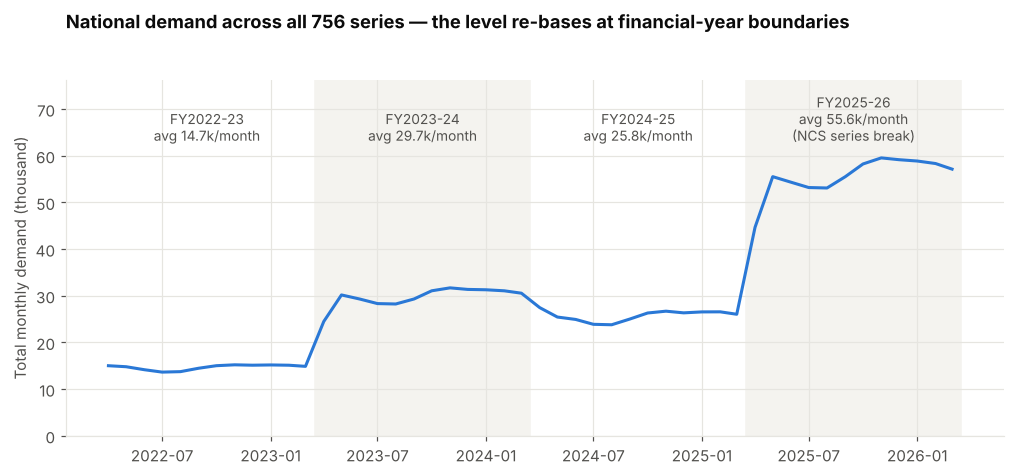

FY-over-FY change in average monthly demand: {'FY2023-24': '+102%', 'FY2024-25': '-13%', 'FY2025-26': '+116%'}


In [5]:
nat = df.groupby("DATE")["DEMAND"].sum()
fy_avg = df.groupby("FY_IDX").apply(lambda g: g.groupby("DATE")["DEMAND"].sum().mean())

fig, ax = plt.subplots(figsize=(11, 4.2))
for fy in sorted(df["FY_IDX"].unique()):
    g = df[df["FY_IDX"] == fy]
    if fy % 2 == 1:
        ax.axvspan(g["DATE"].min() - pd.Timedelta(days=15), g["DATE"].max() + pd.Timedelta(days=15), color="#f4f3ef", zorder=0)
    ax.text(g["DATE"].min() + (g["DATE"].max() - g["DATE"].min()) / 2, nat.max() / 1000 * 1.05,
            f"FY{FY_LABEL[fy]}\navg {fy_avg[fy]/1000:.1f}k/month" + ("\n(NCS series break)" if fy == BREAK_FY else ""),
            ha="center", va="bottom", fontsize=9, color=INK2)
ax.plot(nat.index, nat.values / 1000, color=C[0], lw=2)
ax.set_ylim(0, nat.max() / 1000 * 1.28)
ax.set_ylabel("Total monthly demand (thousand)"); ax.set_title(f"National demand across all {df['SERIES_ID'].nunique()} series — the level re-bases at financial-year boundaries", loc="left", pad=34)
show(fig, "eda_national_demand")

jumps = (fy_avg / fy_avg.shift(1) - 1).dropna()
print("FY-over-FY change in average monthly demand:", {f"FY{FY_LABEL[i]}": f"{v:+.0%}" for i, v in jumps.items()})

**Insight 1.** Within a financial year the series is smooth and seasonal, but the level **re-bases in April** (the printed FY-over-FY changes above run from roughly −13 % to +116 %). A model trained on raw counts would read these jumps as extraordinary growth/decline and mis-forecast every horizon that crosses a financial-year boundary.

### 4.2 Why? — demand is anchored to the real NCS state totals

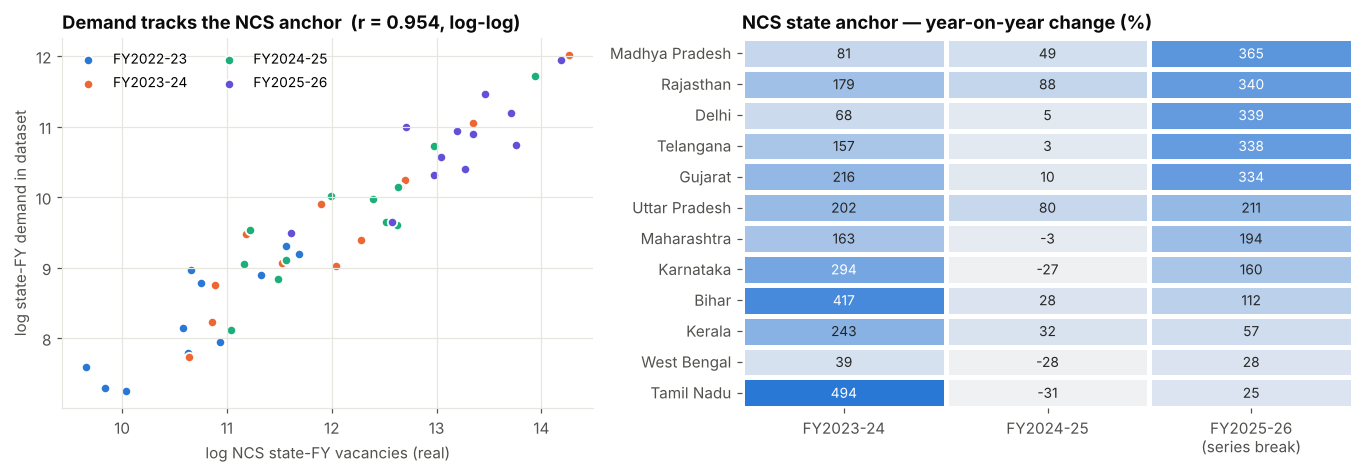

Correlation of YoY log-growth, demand vs NCS anchor (state-FY pairs, n=36): 0.999
Demand ÷ NCS-anchor ratio per state — minimum and maximum across the four financial years:


STATE,Bihar,Delhi,Gujarat,Karnataka,Kerala,Madhya Pradesh,Maharashtra,Rajasthan,Tamil Nadu,Telangana,Uttar Pradesh,West Bengal
min,0.056,0.181,0.136,0.086,0.118,0.053,0.081,0.070,0.101,0.085,0.049,0.106
max,0.058,0.185,0.139,0.089,0.126,0.061,0.083,0.079,0.106,0.088,0.050,0.108


In [6]:
anchor_fy = df.groupby(["STATE", "FY_IDX"])["NCS_STATE_FY_VACANCIES_REAL"].first().unstack()
dem_fy    = df.groupby(["STATE", "FY_IDX"])["DEMAND"].sum().unstack()

lg = pd.DataFrame({"NCS anchor": np.log(anchor_fy.stack()), "Demand": np.log(dem_fy.stack())}).reset_index()
gg = pd.concat({"dem": np.log(dem_fy).diff(axis=1).stack(future_stack=True), "anc": np.log(anchor_fy).diff(axis=1).stack(future_stack=True)}, axis=1).dropna()
r_level  = np.corrcoef(lg["NCS anchor"], lg["Demand"])[0, 1]
r_growth = gg["dem"].corr(gg["anc"])
ratio = (dem_fy / anchor_fy)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
for fy in sorted(lg["FY_IDX"].unique()):
    s = lg[lg["FY_IDX"] == fy]
    ax.scatter(s["NCS anchor"], s["Demand"], s=38, color=C[fy], edgecolor="white", linewidth=1.2, label=f"FY{FY_LABEL[fy]}")
ax.set_xlabel("log NCS state-FY vacancies (real)"); ax.set_ylabel("log state-FY demand in dataset")
ax.set_title(f"Demand tracks the NCS anchor  (r = {r_level:.3f}, log-log)", loc="left"); ax.legend(ncol=2, fontsize=9)

ax = axes[1]
gr = anchor_fy.pct_change(axis=1).iloc[:, 1:]
gr.columns = [f"FY{FY_LABEL[c]}" + ("\n(series break)" if c == BREAK_FY else "") for c in gr.columns]
sns.heatmap(gr.sort_values(gr.columns[-1], ascending=False) * 100, annot=True, fmt=".0f", cmap=sns.light_palette(C[0], as_cmap=True),
            cbar=False, linewidths=2, linecolor="white", ax=ax, annot_kws={"size": 9})
ax.set_title("NCS state anchor — year-on-year change (%)", loc="left"); ax.set_xlabel(""); ax.set_ylabel("")
ax.grid(False)
fig.tight_layout(); show(fig, "eda_anchor_evidence")

print(f"Correlation of YoY log-growth, demand vs NCS anchor (state-FY pairs, n={len(gg)}): {r_growth:.3f}")
print("Demand ÷ NCS-anchor ratio per state — minimum and maximum across the four financial years:")
display((ratio.agg(["min", "max"], axis=1) .round(3)).T)

**Insight 2.** State-level demand is essentially *(NCS annual state total) × (a stable share)*. The year-on-year log-growth correlation with the NCS anchor is ≈ 0.999 and the demand/anchor ratio stays within a narrow band for every state. The April step-changes are therefore **reporting-base shifts**, not changes in the underlying skill mix — and the FY2025-26 anchors carry the dataset's own `NCS_SERIES_BREAK` flag.

**Design consequence → §5:** separate the forecast into *(a)* predictable intensity dynamics (seasonality, skill-mix drift, momentum) that machine learning can learn, and *(b)* the exogenous FY anchor, handled with explicit scenarios.

### 4.3 Seasonality inside the financial year

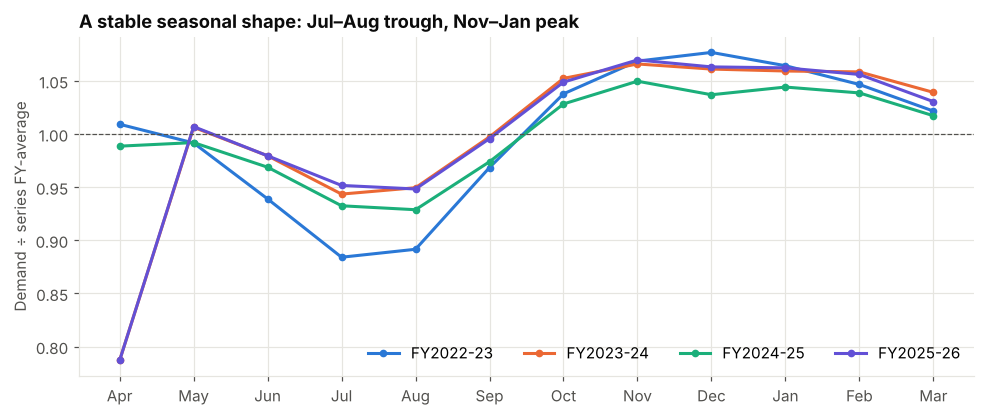

Seasonal index range (all FYs, mean): 0.89 → 1.06


In [7]:
fy_mean = df.groupby(["SERIES_ID", "FY_IDX"])["DEMAND"].transform("mean")
df["REL_TO_FY_MEAN"] = np.where(fy_mean > 0, df["DEMAND"] / fy_mean.replace(0, np.nan), np.nan)
seas = df.groupby(["FY_IDX", "FY_POS"])["REL_TO_FY_MEAN"].mean().unstack(0)
months = ["Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar"]

fig, ax = plt.subplots(figsize=(10.5, 4))
for fy in seas.columns:
    ax.plot(range(12), seas[fy].values, color=C[fy], lw=2, marker="o", ms=4, label=f"FY{FY_LABEL[fy]}")
ax.axhline(1, color=INK2, lw=0.8, ls="--")
ax.set_xticks(range(12)); ax.set_xticklabels(months); ax.set_ylabel("Demand ÷ series FY-average")
ax.set_title("A stable seasonal shape: Jul–Aug trough, Nov–Jan peak", loc="left"); ax.legend(ncol=4)
show(fig, "eda_seasonality")
print("Seasonal index range (all FYs, mean):", seas.mean(axis=1).round(2).min(), "→", seas.mean(axis=1).round(2).max())

**Insight 3.** The seasonal profile (Jul–Aug trough, Nov–Jan peak) is consistent across years, so **calendar features are valuable**. In the two years with a large re-basing (FY2023-24 and FY2025-26) April is visibly lower — the new anchor ramps in — which is one more reason to keep fiscal-position features.

### 4.4 Skill-mix drift — the real structural signal

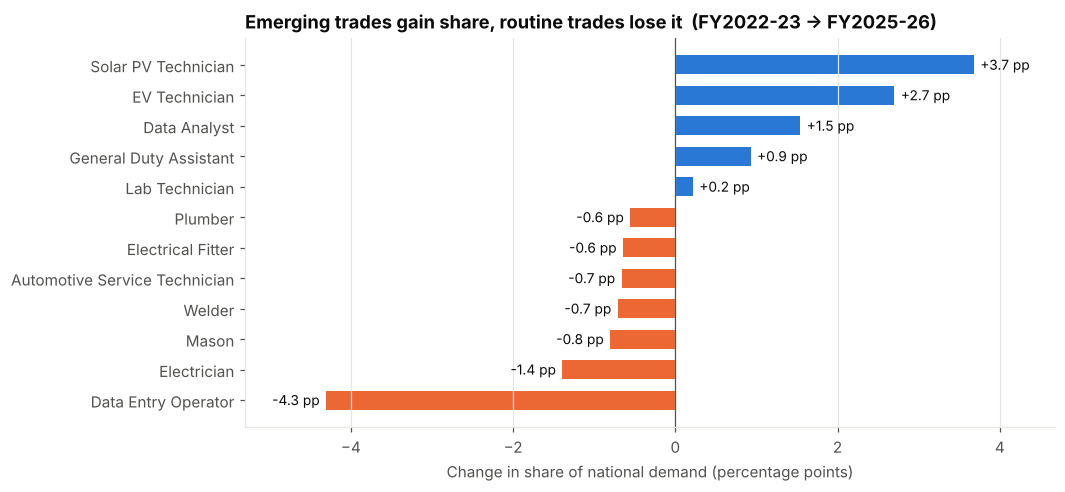

In [8]:
share = (df.groupby(["FY_IDX", "SKILL"])["DEMAND"].sum().unstack(0))
share = share / share.sum() * 100
shift = (share[share.columns.max()] - share[share.columns.min()]).sort_values()

fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.barh(shift.index, shift.values, color=[C[0] if v > 0 else C[1] for v in shift.values], height=0.62)
for i, v in enumerate(shift.values):
    ax.text(v + (0.08 if v > 0 else -0.08), i, f"{v:+.1f} pp", va="center", ha="left" if v > 0 else "right", fontsize=9, color=INK)
ax.axvline(0, color=INK2, lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlim(shift.min() - 1.0, shift.max() + 1.0)
ax.set_xlabel("Change in share of national demand (percentage points)")
ax.set_title(f"Emerging trades gain share, routine trades lose it  (FY{FY_LABEL[0]} → FY{FY_LABEL[max(FY_LABEL)]})", loc="left")
show(fig, "eda_skill_mix_shift")

**Insight 4.** Solar PV, EV and Data-Analyst roles are gaining share; Data-Entry and Electrician roles are losing it. This **relative drift is what planners most need** (it tells them where to add or cut training capacity) — and it survives anchor normalisation, so the model can learn it.

### 4.5 Volume structure — why we need a robust metric and honest uncertainty

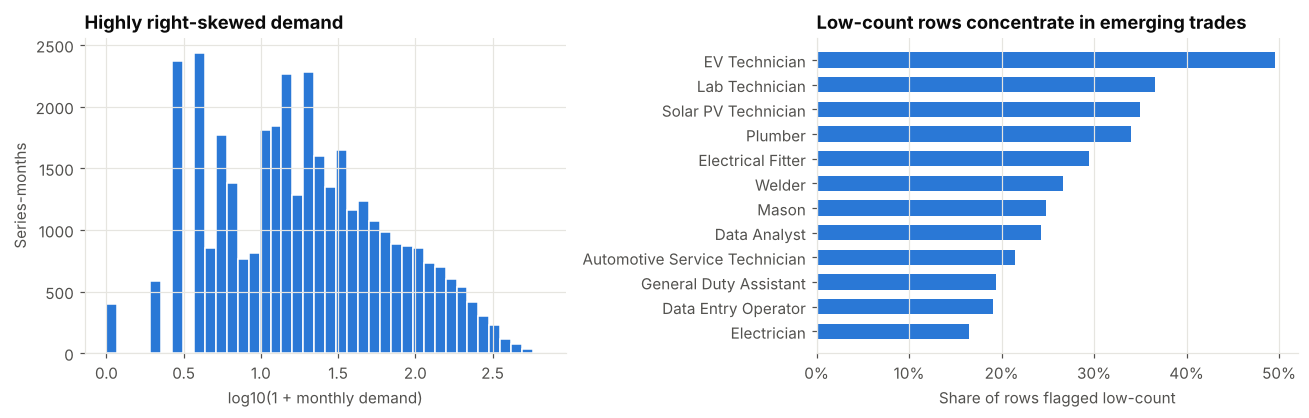

Low-count rows: 28.1%   |   zero-demand months: 1.11%


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].hist(np.log10(1 + df["DEMAND"]), bins=40, color=C[0], edgecolor="white")
axes[0].set_xlabel("log10(1 + monthly demand)"); axes[0].set_ylabel("Series-months")
axes[0].set_title("Highly right-skewed demand", loc="left")
lc = df.groupby("SKILL")["LOW_COUNT_FLAG"].mean().sort_values() * 100
axes[1].barh(lc.index, lc.values, color=C[0], height=0.62); axes[1].grid(axis="y", visible=False)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[1].set_xlabel("Share of rows flagged low-count")
axes[1].set_title("Low-count rows concentrate in emerging trades", loc="left")
fig.tight_layout(); show(fig, "eda_volume")
print(f"Low-count rows: {df['LOW_COUNT_FLAG'].mean():.1%}   |   zero-demand months: {(df['DEMAND']==0).mean():.2%}")

**Insight 5.** Demand spans 0 → ~680 per month and more than a quarter of rows are low-count. Percentage errors on tiny counts are noisy, so we report **MAE, RMSE and MAPE (the required metrics) plus WAPE** (volume-weighted, robust) and give low-volume series wider intervals / lower confidence.

## 5. Anchor normalisation — separating *organic demand* from *reporting re-basing*

**Idea (analogy: inflation-adjusting prices).** Each month's counts are rescaled by `NCS anchor of the reference year ÷ NCS anchor of that month's year` (state-wise), so every month is expressed in the **same constant units**. What remains is the organic signal — seasonality, momentum and skill-mix drift — which a model can genuinely learn.

* Forecasts are produced **in the units of the latest financial year**, so `current_demand` in the handover equals the demand actually observed in the latest month.
* The next year's NCS anchor is not known yet. It is handled explicitly through a **scenario multiplier** (§12), never hidden inside the model.
* To keep the back-test honest, the hold-out evaluation uses a *separate* normalisation whose reference year is the last year **before** the hold-out.

In [10]:
ANCH_VAC = df.groupby(["STATE", "FY_IDX"])["NCS_STATE_FY_VACANCIES_REAL"].first().unstack()
ANCH_EMP = df.groupby(["STATE", "FY_IDX"])["NCS_STATE_FY_ACTIVE_EMPLOYERS_REAL"].first().unstack()
assert (ANCH_VAC > 0).all().all() and (ANCH_EMP > 0).all().all(), "NCS anchors must be positive"
_vac_long, _emp_long = ANCH_VAC.stack(), ANCH_EMP.stack()

PANEL_COLS = ["SERIES_ID", "DATE", "t_idx", "FY_IDX", "STATE", "DISTRICT", "SKILL", "SECTOR", "AVG_SALARY", "LOW_COUNT_FLAG"]

def normalise(frame, ref_fy):
    """Express every month in constant units of financial year `ref_fy` (state-wise NCS anchors)."""
    key   = pd.MultiIndex.from_arrays([frame["STATE"], frame["FY_IDX"]])
    f_vac = ANCH_VAC[ref_fy].reindex(frame["STATE"]).to_numpy() / _vac_long.reindex(key).to_numpy()
    f_emp = ANCH_EMP[ref_fy].reindex(frame["STATE"]).to_numpy() / _emp_long.reindex(key).to_numpy()
    out = frame[PANEL_COLS].copy()
    out["Y"]    = frame["DEMAND"].to_numpy()           * f_vac       # demand
    out["ACT"]  = frame["ACTIVE_VACANCIES"].to_numpy() * f_vac       # active vacancies
    out["NEWP"] = frame["NEW_JOB_POSTINGS"].to_numpy() * f_vac       # new postings
    out["EMP"]  = frame["EMPLOYER_COUNT"].to_numpy()   * f_emp       # employers
    return out

LAST_FY      = int(df["FY_IDX"].max())
HOLDOUT_FY   = LAST_FY                         # the most recent financial year is held out for testing
CUT          = HOLDOUT_FY * 12 - 1             # last month the models may learn from in the back-test (Mar of the previous FY)
REF_BT       = HOLDOUT_FY - 1                  # back-test normalisation reference (no future information)
panel_bt     = normalise(df, REF_BT)           # back-test units
panel_fin    = normalise(df, LAST_FY)          # production units (= raw units of the latest year)
DATES        = pd.date_range(START, periods=T_LAST + 1, freq="MS")
print(f"Back-test: learn up to {DATES[CUT]:%b-%Y} (t={CUT}) · hold-out = FY{FY_LABEL[HOLDOUT_FY]} · production forecast origin = {LAST_DATE:%b-%Y} (t={T_LAST})")

Back-test: learn up to Mar-2025 (t=35) · hold-out = FY2025-26 · production forecast origin = Mar-2026 (t=47)


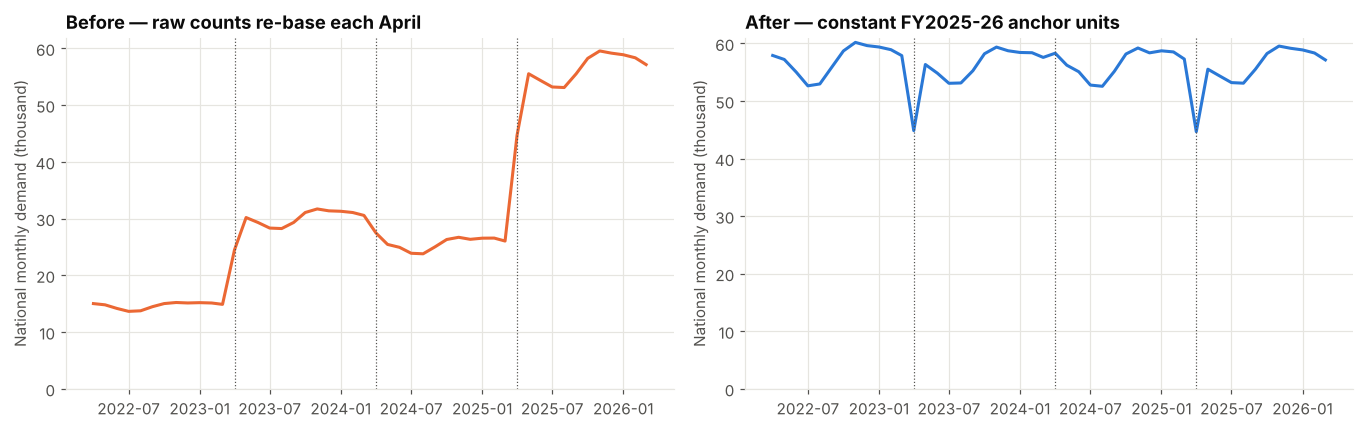

,FY2023-24,FY2024-25,FY2025-26
Raw April ÷ March,2.08,1.02,2.28
Normalised April ÷ March,0.76,0.99,0.77


Median 'April ÷ March' by financial year: after normalisation the jump disappears — only the genuine seasonal dip in April remains.


In [11]:
def april_ratio(frame, col):
    """Median over series of  April value ÷ previous March value  for each financial year."""
    w = frame.pivot(index="t_idx", columns="SERIES_ID", values=col)
    return {f"FY{FY_LABEL[fy]}": float((w.loc[fy * 12] / w.loc[fy * 12 - 1].clip(lower=1)).median()) for fy in range(1, LAST_FY + 1)}

raw_ratio  = april_ratio(df.assign(Y=df["DEMAND"]), "Y")
norm_ratio = april_ratio(panel_fin, "Y")

nat_raw  = df.groupby("DATE")["DEMAND"].sum()
nat_norm = panel_fin.groupby("DATE")["Y"].sum()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), sharex=True)
axes[0].plot(nat_raw.index, nat_raw / 1000, color=C[1], lw=2); axes[0].set_title("Before — raw counts re-base each April", loc="left")
axes[1].plot(nat_norm.index, nat_norm / 1000, color=C[0], lw=2); axes[1].set_title(f"After — constant FY{FY_LABEL[LAST_FY]} anchor units", loc="left")
for ax in axes:
    ax.set_ylim(0, None); ax.set_ylabel("National monthly demand (thousand)")
    for fy in range(1, LAST_FY + 1):
        ax.axvline(DATES[fy * 12], color=INK2, lw=0.8, ls=":")
fig.tight_layout(); show(fig, "anchor_normalisation_before_after")

cmp = pd.DataFrame({"Raw  April ÷ March": raw_ratio, "Normalised  April ÷ March": norm_ratio}).T
display(cmp.round(2))
print("Median 'April ÷ March' by financial year: after normalisation the jump disappears — only the genuine seasonal dip in April remains.")

**Result.** After normalisation the artificial level shifts are gone; what remains is a smooth seasonal series. This is the foundation of everything that follows.

## 6. Feature engineering

Features describe *what the model knows at forecast origin t* — never anything after t. Exactly the features requested in the brief (previous-month demand, 3- and 6-month averages, growth %, month, district, skill, sector) are included and extended with seasonality and hiring-intensity signals.

**Target (per horizon h ∈ {3, 6, 12}):** `log1p(demand at t+h) − log1p(3-month average at t)` — the *relative* change, so the model does not need to extrapolate absolute levels. Predictions are converted back to counts.

In [12]:
SIDS = sorted(df["SERIES_ID"].unique())
META = meta.loc[SIDS]
CAT_COLS   = ["STATE", "DISTRICT", "SKILL", "SECTOR"]
CAT_LEVELS = {c: sorted(df[c].unique()) for c in CAT_COLS}
L = np.log1p

def wide(panel, col):
    return panel.pivot(index="t_idx", columns="SERIES_ID", values=col).reindex(columns=SIDS).sort_index()

def build_features(panel, h):
    """One row per (origin month, series). All features use data up to and including the origin only."""
    Y, ACT, NEWP, EMP, SAL = (wide(panel, c) for c in ["Y", "ACT", "NEWP", "EMP", "AVG_SALARY"])
    tn, S = Y.index.to_numpy(), len(SIDS)
    LY = L(Y)
    a3, a6, a12 = (Y.rolling(k).mean() for k in (3, 6, 12))
    base = L(a3)
    f = {"base_log": base}                                                  # 3-month average (log level)
    for k in (0, 1, 2, 3, 6, 12):                                           # previous-month demand & longer lags (relative to the 3M level)
        f[f"rel_lag{k}"] = LY.shift(k) - base
    f["rel_same_month_ly"]      = LY.shift(12 - h) - base                   # same calendar month as the target, one year earlier
    f["rel_same_month_ly_prev"] = LY.shift(13 - h) - base
    f["avg3_vs_avg6"]  = base - L(a6)                                       # 3M vs 6M average
    f["avg3_vs_avg12"] = base - L(a12)
    f["growth_1m"]  = LY - LY.shift(1)                                      # demand growth (log-%)
    f["growth_3m"]  = base - L(a3.shift(3))
    f["growth_yoy"] = base - L(a3.shift(12))
    f["volatility_6m"] = LY.diff().rolling(6).std()
    act3, new3, emp3, sal3 = (x.rolling(3).mean() for x in (ACT, NEWP, EMP, SAL))
    f["vacancy_ratio"]        = np.log((act3 + 1) / (a3 + 1))
    f["posting_ratio"]        = np.log((new3 + 1) / (act3 + 1))
    f["employers_per_demand"] = L(emp3) - base
    f["employers_growth_3m"]  = L(emp3) - L(emp3.shift(3))
    f["salary_log"]           = np.log(sal3.clip(lower=1))
    f["salary_growth_3m"]     = np.log(sal3.clip(lower=1)) - np.log(sal3.shift(3).clip(lower=1))

    out = {k: v.to_numpy().ravel() for k, v in f.items()}
    fp  = tn % 12                                                           # fiscal position of the origin (0 = April)
    mo  = ((tn + START.month - 1) % 12) + 1                                 # calendar month of the origin
    tm  = ((mo - 1 + h) % 12) + 1                                           # calendar month of the target
    cal = {"month_sin": np.sin(2 * np.pi * mo / 12), "month_cos": np.cos(2 * np.pi * mo / 12),
           "target_month_sin": np.sin(2 * np.pi * tm / 12), "target_month_cos": np.cos(2 * np.pi * tm / 12),
           "fy_pos": fp.astype(float), "target_crosses_fy": ((fp + h) >= 12).astype(float)}
    for k, v in cal.items():
        out[k] = np.repeat(v, S)
    out["district_weight"] = np.tile(META["DISTRICT_WEIGHT"].to_numpy(float), len(tn))
    out["log_pmkvy_trained"] = np.tile(L(META["PMKVY_DISTRICT_TRAINED_FY2021_22_REAL"].to_numpy(float)), len(tn))

    X = pd.DataFrame(out)
    for c in CAT_COLS:
        X[c] = pd.Categorical(np.tile(META[c].to_numpy(), len(tn)), categories=CAT_LEVELS[c])
    X["ORIGIN"], X["SID"] = np.repeat(tn, S), np.tile(SIDS, len(tn))
    X["y_act"] = Y.shift(-h).to_numpy().ravel()                              # target in count units
    X["y_rel"] = (LY.shift(-h) - base).to_numpy().ravel()                    # model target
    X["cur"]   = Y.to_numpy().ravel()
    X["avg3"]  = a3.to_numpy().ravel()
    X["seasonal_naive"] = Y.shift(12 - h).to_numpy().ravel()
    return X

FEATURE_DOC = {
    "Previous-month demand & lags": {"rel_lag0": "demand this month", "rel_lag1": "demand 1 month ago", "rel_lag2": "demand 2 months ago",
                                     "rel_lag3": "demand 3 months ago", "rel_lag6": "demand 6 months ago", "rel_lag12": "demand 12 months ago"},
    "Rolling averages": {"base_log": "3-month average demand (log level)", "avg3_vs_avg6": "3M average vs 6M average", "avg3_vs_avg12": "3M average vs 12M average"},
    "Demand growth %": {"growth_1m": "1-month growth", "growth_3m": "3-month growth", "growth_yoy": "year-on-year growth"},
    "Seasonality / calendar": {"month_sin": "origin month (sin)", "month_cos": "origin month (cos)", "target_month_sin": "target month (sin)",
                               "target_month_cos": "target month (cos)", "fy_pos": "position in financial year", "target_crosses_fy": "target falls in the next FY",
                               "rel_same_month_ly": "same month last year (seasonal anchor)", "rel_same_month_ly_prev": "month before that, last year"},
    "Volatility": {"volatility_6m": "6-month volatility of monthly growth"},
    "Hiring-intensity signals": {"vacancy_ratio": "active vacancies ÷ demand", "posting_ratio": "new postings ÷ active vacancies",
                                 "employers_per_demand": "employers per unit of demand", "employers_growth_3m": "employer-count growth (3M)",
                                 "salary_log": "average salary (log)", "salary_growth_3m": "salary growth (3M)"},
    "Static district descriptors": {"district_weight": "district weight", "log_pmkvy_trained": "PMKVY trained volume (log)"},
}
NUM_FEATURES = [c for grp in FEATURE_DOC.values() for c in grp]
FEATURE_TABLE = pd.DataFrame([(g, k, v) for g, d in FEATURE_DOC.items() for k, v in d.items()], columns=["Group", "Feature", "Meaning"])
FEATURE_TABLE = pd.concat([FEATURE_TABLE, pd.DataFrame({"Group": ["Identifiers (categorical)"] * 4, "Feature": CAT_COLS,
                           "Meaning": ["state", "district", "skill / trade", "sector"]})], ignore_index=True)

FE_BT = {h: build_features(panel_bt, h) for h in HORIZONS}
for h in HORIZONS:
    assert set(NUM_FEATURES) <= set(FE_BT[h].columns)
    FE_BT[h]["valid"] = FE_BT[h][NUM_FEATURES].notna().all(axis=1)
    r = FE_BT[h].groupby("ORIGIN")["base_log"].rank(pct=True, method="first")
    FE_BT[h]["TIER"] = np.clip(np.ceil(r * 4) - 1, 0, 3).fillna(0).astype(int)    # volume quartile within the origin's cross-section
print(f"{len(NUM_FEATURES)} numeric + {len(CAT_COLS)} categorical features · {len(SIDS)} series · feature matrices built for horizons {HORIZONS}")
display(FEATURE_TABLE.style.hide(axis="index"))

29 numeric + 4 categorical features · 756 series · feature matrices built for horizons (3, 6, 12)


Group,Feature,Meaning
Previous-month demand & lags,rel_lag0,demand this month
Previous-month demand & lags,rel_lag1,demand 1 month ago
Previous-month demand & lags,rel_lag2,demand 2 months ago
Previous-month demand & lags,rel_lag3,demand 3 months ago
Previous-month demand & lags,rel_lag6,demand 6 months ago
Previous-month demand & lags,rel_lag12,demand 12 months ago
Rolling averages,base_log,3-month average demand (log level)
Rolling averages,avg3_vs_avg6,3M average vs 6M average
Rolling averages,avg3_vs_avg12,3M average vs 12M average
Demand growth %,growth_1m,1-month growth


In [13]:
# ---- leakage test: features at origin t must not change when ALL later data is removed
h_chk = 6
trunc = build_features(panel_bt[panel_bt["t_idx"] <= CUT], h_chk)
a = trunc[trunc["ORIGIN"] == CUT][NUM_FEATURES].to_numpy(float)
b = FE_BT[h_chk][FE_BT[h_chk]["ORIGIN"] == CUT][NUM_FEATURES].to_numpy(float)
np.testing.assert_allclose(a, b, equal_nan=True)
print("✔ Leakage test passed: features at the cut-off are identical with and without future data.")

✔ Leakage test passed: features at the cut-off are identical with and without future data.


## 7. Validation design — train / rolling validation / hold-out

```
 t=0 ──────────── training ───────────┬── 4 rolling validation blocks (3 target months each) ──┬──── hold-out (latest FY) ───▶
                                      │   Apr–Jun · Jul–Sep · Oct–Dec · Jan–Mar of the last full FY before the cut-off
```

| Stage | Data | Purpose |
|---|---|---|
| **Train (inner)** | samples whose target month is ≤ cut − 3 | fit candidates; tune hyper-parameters on the most recent block |
| **Rolling-origin validation** | four consecutive blocks of 3 target months covering the **last full financial year before the cut-off** (full seasonal cycle *including* the April financial-year transition). Each fold is trained **only** on samples whose target precedes its block | **select the final model per horizon** (mean over folds) |
| **Hold-out test** | targets after the cut (latest financial year) | unbiased accuracy, reported for **all** models on one common set-up |

*Why not a single validation window?* A 3-month window sees neither a financial-year boundary nor a full seasonal cycle, so it can crown a model that merely suits one season. Rolling validation over a whole year is the standard remedy for seasonal series.

Two hold-out views are reported:
* **Fixed origin** — everyone forecasts from the same cut-off month (3M/6M/12M ahead) for all series. This is the *same evaluation set-up* for every model, including ARIMA.
* **Rolling origin** — every origin whose target falls in the hold-out year (≈ 9 000 forecasts per horizon) for the global ML models: a larger-sample robustness check.

In [14]:
def split(X, h):
    lab = X["valid"] & X["y_rel"].notna()
    tgt = X["ORIGIN"] + h
    return {"train_in": X[lab & (tgt <= CUT - VAL_MONTHS)],
            "val":      X[lab & (tgt > CUT - VAL_MONTHS) & (tgt <= CUT)],
            "train":    X[lab & (tgt <= CUT)],
            "test":     X[lab & (tgt > CUT)],
            "test_fixed": X[lab & (X["ORIGIN"] == CUT)]}

SPL = {h: split(FE_BT[h], h) for h in HORIZONS}
rows = []
for h in HORIZONS:
    s = SPL[h]
    assert (s["train_in"]["ORIGIN"] + h).max() <= CUT - VAL_MONTHS and (s["train"]["ORIGIN"] + h).max() <= CUT
    assert (s["test"]["ORIGIN"] + h).min() > CUT and (s["val"]["ORIGIN"] + h).min() > CUT - VAL_MONTHS
    rows.append({"Horizon": f"{h}M", "Train (inner)": len(s["train_in"]), "Tuning block": len(s["val"]), "Train (final back-test)": len(s["train"]),
                 "Hold-out rolling": len(s["test"]), "Hold-out fixed-origin": len(s["test_fixed"]),
                 "Hold-out target months": f"{DATES[CUT + 1]:%b-%y} … {DATES[T_LAST]:%b-%y}"})
display(pd.DataFrame(rows).set_index("Horizon"))
print("✔ No target month of any training sample falls inside the validation or hold-out window.")

,Train (inner),Tuning block,Train (final back-test),Hold-out rolling,Hold-out fixed-origin,Hold-out target months
Horizon,,,,,,
3M,12096,2268,14364,9072,756,Apr-25 … Mar-26
6M,9828,2268,12096,9072,756,Apr-25 … Mar-26
12M,5292,2268,7560,9072,756,Apr-25 … Mar-26


✔ No target month of any training sample falls inside the validation or hold-out window.


## 8. Models — baseline, main ML models and benchmarks

| Role | Model | Notes |
|---|---|---|
| Naive benchmarks | 3-month average, seasonal naive | the bar every model must beat |
| **Baseline** | **Linear Regression** | same features (+ one-hot state / sector / skill), standardised |
| **Main ML** | **LightGBM**, **XGBoost** | global models learning across all 756 series; hyper-parameters tuned by random search on the most recent validation block |
| Main ML | Ensemble (LightGBM + XGBoost) | simple average of the two tuned boosters |
| **Time-series comparison** | **ARIMA** | one model per series (§9) |

In [15]:
def pred_count(X, rel):
    """relative prediction -> demand count"""
    return np.clip(np.expm1(X["base_log"].to_numpy() + np.asarray(rel)), 0, None)

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e, nz = p - y, y > 0
    return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()),
            "MAPE": 100 * (np.abs(e[nz]) / y[nz]).mean(), "WAPE": 100 * np.abs(e).sum() / y.sum()}

def design(X, kind):
    if kind == "tree":
        return X[NUM_FEATURES + CAT_COLS]
    lin = X[NUM_FEATURES].copy()
    for c in ("STATE", "SECTOR", "SKILL"):
        lin = lin.join(pd.get_dummies(X[c], prefix=c, dtype=float))
    return lin

def make_lr():           return Pipeline([("scale", StandardScaler()), ("lr", LinearRegression())])
def make_lgb(**p):       return lgb.LGBMRegressor(random_state=SEED, n_jobs=2, verbosity=-1, **p)
def make_xgb(**p):       return xgb.XGBRegressor(tree_method="hist", enable_categorical=True, random_state=SEED, n_jobs=2, **p)

LGB_DEFAULT = dict(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5)
XGB_DEFAULT = dict(n_estimators=300, learning_rate=0.05, max_depth=4, min_child_weight=20, subsample=0.8, colsample_bytree=0.8, reg_lambda=5)
LGB_SPACE = dict(n_estimators=[200, 300, 500], learning_rate=[0.03, 0.05, 0.08], num_leaves=[7, 15, 31], min_child_samples=[20, 50, 100],
                 subsample=[0.7, 0.85, 1.0], subsample_freq=[1], colsample_bytree=[0.6, 0.8, 1.0], reg_lambda=[1, 5, 20])
XGB_SPACE = dict(n_estimators=[200, 300, 500], learning_rate=[0.03, 0.05, 0.08], max_depth=[3, 4, 6], min_child_weight=[5, 20, 50],
                 subsample=[0.7, 0.85, 1.0], colsample_bytree=[0.6, 0.8, 1.0], reg_lambda=[1, 5, 20])

def tune(make, default, space, Xtr, ytr, Xva, yva):
    """random search; objective = MAE of the log-ratio target on the validation block (symmetric in relative terms)"""
    cands = [default] + list(ParameterSampler(space, N_TUNE_ITER, random_state=SEED))
    scored = []
    for p in cands:
        m = make(**p).fit(Xtr, ytr)
        scored.append((mean_absolute_error(yva, m.predict(Xva)), p))
    scored.sort(key=lambda t: t[0])
    return scored[0][1], scored[0][0], scored[-1][0]

TUNED = {}
t0 = time.time()
for h in HORIZONS:
    s = SPL[h]
    Xtr_t, Xva_t = design(s["train_in"], "tree"), design(s["val"], "tree")
    ytr, yva = s["train_in"]["y_rel"].to_numpy(), s["val"]["y_rel"].to_numpy()
    p_lgb, best_l, worst_l = tune(make_lgb, LGB_DEFAULT, LGB_SPACE, Xtr_t, ytr, Xva_t, yva)
    p_xgb, best_x, worst_x = tune(make_xgb, XGB_DEFAULT, XGB_SPACE, Xtr_t, ytr, Xva_t, yva)
    TUNED[h] = {"lgb": p_lgb, "xgb": p_xgb}
    print(f"h={h:>2}M  tuning done · val log-MAE  LGBM {best_l:.4f} (worst candidate {worst_l:.4f})  XGB {best_x:.4f} (worst {worst_x:.4f})")
print(f"Tuning time: {time.time() - t0:.0f}s")
display(pd.DataFrame({h: {"LightGBM": str({k: v for k, v in TUNED[h]['lgb'].items() if k in ('n_estimators','learning_rate','num_leaves','min_child_samples')}),
                          "XGBoost": str({k: v for k, v in TUNED[h]['xgb'].items() if k in ('n_estimators','learning_rate','max_depth','min_child_weight')})} for h in HORIZONS}).rename(columns=lambda h: f"{h}M"))

h= 3M  tuning done · val log-MAE  LGBM 0.0807 (worst candidate 0.0847)  XGB 0.0809 (worst 0.0816)


h= 6M  tuning done · val log-MAE  LGBM 0.0807 (worst candidate 0.0841)  XGB 0.0816 (worst 0.0829)


h=12M  tuning done · val log-MAE  LGBM 0.0800 (worst candidate 0.0836)  XGB 0.0802 (worst 0.0818)
Tuning time: 20s


,3M,6M,12M
LightGBM,"{'n_estimators': 300, 'learning_rate': 0.05, '...","{'num_leaves': 31, 'n_estimators': 300, 'min_c...","{'num_leaves': 31, 'n_estimators': 300, 'min_c..."
XGBoost,"{'n_estimators': 500, 'min_child_weight': 20, ...","{'n_estimators': 500, 'min_child_weight': 20, ...","{'n_estimators': 500, 'min_child_weight': 20, ..."


### 8.1 Rolling-origin validation → choose the final model per horizon
Each model is evaluated on four consecutive validation blocks (see §7); every fold is trained only on samples whose target precedes the block. Candidates are ranked by their **mean rank across MAE, RMSE and MAPE, averaged over folds**. The hold-out set is *not* used for this choice. (Hyper-parameters were tuned once on the most recent block; the 12-month model has fewer folds because its long label horizon leaves too little earlier data.)

**Selected on rolling validation:** **3M → LightGBM** · **6M → LightGBM** · **12M → Ensemble (LGBM+XGB)**

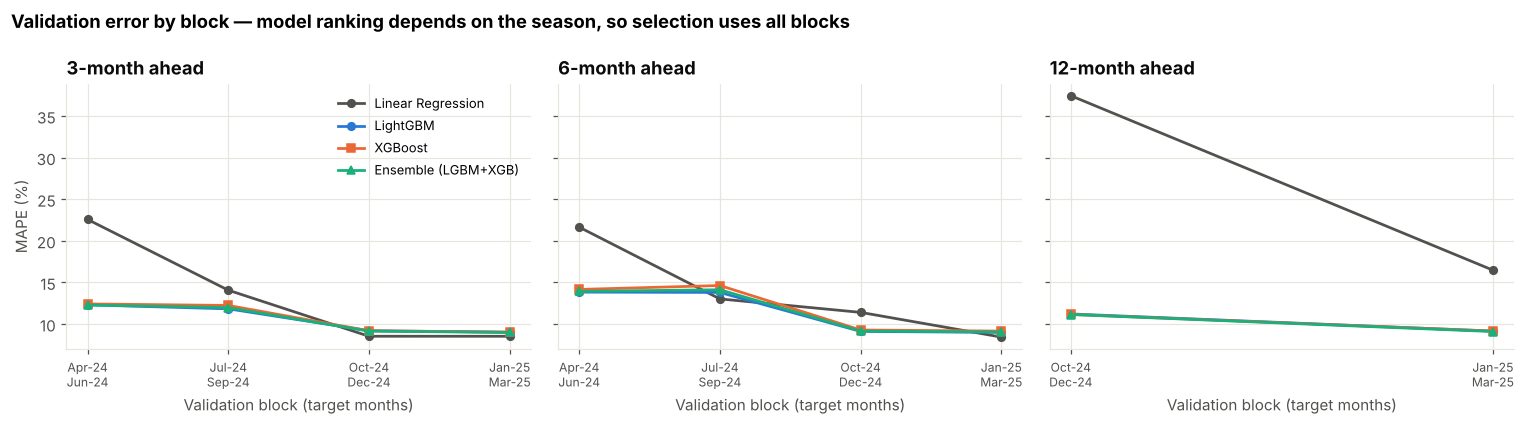

In [16]:
MODEL_NAMES = {"LR": "Linear Regression", "LGBM": "LightGBM", "XGB": "XGBoost", "ENS": "Ensemble (LGBM+XGB)",
               "ARIMA": "ARIMA", "SNAIVE": "Seasonal naive", "NAIVE3": "3M-average naive"}
ML_CANDIDATES = ["LR", "LGBM", "XGB", "ENS"]
BLOCKS    = [(CUT - 11, CUT - 9), (CUT - 8, CUT - 6), (CUT - 5, CUT - 3), (CUT - 2, CUT)]      # target-month ranges of the validation blocks
MIN_TRAIN = 2500                                                                               # a fold needs at least this many training samples

fold_rows = []
for h in HORIZONS:
    X = FE_BT[h]; lab = X["valid"] & X["y_rel"].notna(); tgt = X["ORIGIN"] + h
    for k, (lo_t, hi_t) in enumerate(BLOCKS, start=1):
        tr, va = X[lab & (tgt < lo_t)], X[lab & (tgt >= lo_t) & (tgt <= hi_t)]
        if len(tr) < MIN_TRAIN or len(va) == 0:
            continue
        assert (tr["ORIGIN"] + h).max() < lo_t                                                  # no future information in any fold
        ytr = tr["y_rel"].to_numpy()
        rel = {"LR":   make_lr().fit(design(tr, "lin"), ytr).predict(design(va, "lin")),
               "LGBM": make_lgb(**TUNED[h]["lgb"]).fit(design(tr, "tree"), ytr).predict(design(va, "tree")),
               "XGB":  make_xgb(**TUNED[h]["xgb"]).fit(design(tr, "tree"), ytr).predict(design(va, "tree"))}
        rel["ENS"] = (rel["LGBM"] + rel["XGB"]) / 2
        cand = {m: metrics(va["y_act"], pred_count(va, r)) for m, r in rel.items()}
        cand["NAIVE3"], cand["SNAIVE"] = metrics(va["y_act"], va["avg3"]), metrics(va["y_act"], va["seasonal_naive"])
        for m, mm in cand.items():
            fold_rows.append({"Horizon": h, "Fold": k, "Targets": f"{DATES[lo_t]:%b-%y} … {DATES[hi_t]:%b-%y}", "Model": m, "n_train": len(tr), **mm})
FOLD_TAB = pd.DataFrame(fold_rows)

VAL_TAB = FOLD_TAB.groupby(["Horizon", "Model"])[["MAE", "RMSE", "MAPE", "WAPE"]].mean().reset_index()
VAL_TAB["mean_rank"] = np.nan
for h in HORIZONS:
    m = (VAL_TAB["Horizon"] == h) & VAL_TAB["Model"].isin(ML_CANDIDATES)
    VAL_TAB.loc[m, "mean_rank"] = VAL_TAB.loc[m, ["MAE", "RMSE", "MAPE"]].rank().mean(axis=1)
VAL_TAB["n_folds"] = VAL_TAB["Horizon"].map(FOLD_TAB.groupby("Horizon")["Fold"].nunique())

SELECTED = {h: VAL_TAB[(VAL_TAB.Horizon == h) & VAL_TAB.Model.isin(ML_CANDIDATES)].sort_values(["mean_rank", "MAPE"]).iloc[0]["Model"] for h in HORIZONS}

show_val = VAL_TAB.assign(Model=VAL_TAB.Model.map(MODEL_NAMES)).set_index(["Horizon", "Model"])[["n_folds", "MAE", "RMSE", "MAPE", "WAPE", "mean_rank"]]
display(show_val.style.format({"n_folds": "{:.0f}", "MAE": "{:.2f}", "RMSE": "{:.2f}", "MAPE": "{:.2f}", "WAPE": "{:.2f}", "mean_rank": "{:.2f}"}).background_gradient(subset=["MAPE"], cmap="Blues_r"))
display(Markdown("**Selected on rolling validation:** " + " · ".join(f"**{h}M → {MODEL_NAMES[SELECTED[h]]}**" for h in HORIZONS)))

# ---- chart: MAPE per validation block — shows why a single window is not enough
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
style = {"LR": (INK2, "o"), "LGBM": (C[0], "o"), "XGB": (C[1], "s"), "ENS": (C[2], "^")}
for ax, h in zip(axes, HORIZONS):
    d = FOLD_TAB[(FOLD_TAB.Horizon == h) & FOLD_TAB.Model.isin(ML_CANDIDATES)]
    for m in ML_CANDIDATES:
        e = d[d.Model == m]
        ax.plot(e["Fold"], e["MAPE"], color=style[m][0], marker=style[m][1], lw=1.8, ms=5, label=MODEL_NAMES[m])
    ax.set_xticks(sorted(d["Fold"].unique())); ax.set_xticklabels([d[d.Fold == f]["Targets"].iloc[0].replace(" … ", "\n") for f in sorted(d["Fold"].unique())], fontsize=8)
    ax.set_title(f"{h}-month ahead", loc="left"); ax.set_xlabel("Validation block (target months)")
axes[0].set_ylabel("MAPE (%)"); axes[0].legend(fontsize=8.5, loc="upper right")
fig.suptitle("Validation error by block — model ranking depends on the season, so selection uses all blocks", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout(); show(fig, "validation_blocks")

## 9. Time-series comparison — ARIMA (one model per series)

These classical models are fitted **separately to each series of a random sample (`TS_SAMPLE`)** on the anchor-normalised history up to the cut-off, then forecast 12 months ahead. They therefore share nothing across series (unlike the global ML models) and see no hiring-signal features — a fair reflection of how they would be used in practice.

In [17]:
def _arima_fc(y_log, dates, steps=12):
    import warnings
    warnings.filterwarnings("ignore")
    from statsmodels.tsa.arima.model import ARIMA
    best = None
    for order in [(0, 1, 1), (1, 1, 0), (1, 1, 1), (2, 1, 1), (1, 0, 0)]:
        try:
            r = ARIMA(y_log, order=order, trend="t" if order[1] == 0 else "n").fit()
            if best is None or r.aic < best.aic:
                best = r
        except Exception:
            continue
    return best.forecast(steps) if best is not None else np.repeat(y_log[-3:].mean(), steps)

Y_BT = wide(panel_bt, "Y")                                  # back-test units
ts_sids = SIDS if TS_SAMPLE is None else list(rng.choice(SIDS, size=min(TS_SAMPLE, len(SIDS)), replace=False))
hist = [L(Y_BT.loc[:CUT, sid].to_numpy()) for sid in ts_sids]

t0 = time.time()
STAT = {}
for name, fn in [("ARIMA", _arima_fc)]:
    out = [fn(y, DATES[:CUT + 1], 12) for y in hist]
    STAT[name] = pd.DataFrame(np.clip(np.expm1(np.vstack(out)), 0, None), index=ts_sids, columns=range(1, 13))
    print(f"{MODEL_NAMES[name]:8s} fitted on {len(ts_sids)} series in {time.time() - t0:.0f}s")

ARIMA    fitted on 100 series in 14s


## 10. Model evaluation — MAE, RMSE, MAPE on the hold-out year

### 10.1 Hold-out predictions for every model
Models are re-fitted on **all samples whose target is known at the cut-off** (train + validation) with the tuned hyper-parameters, then evaluated on the hold-out year.

In [18]:
BT_MODELS, TEST_REL = {}, {}
for h in HORIZONS:
    s = SPL[h]
    ytr = s["train"]["y_rel"].to_numpy()
    Xtr_t, Xte_t = design(s["train"], "tree"), design(s["test"], "tree")
    lr  = make_lr().fit(design(s["train"], "lin"), ytr)
    mlg = make_lgb(**TUNED[h]["lgb"]).fit(Xtr_t, ytr)
    mxg = make_xgb(**TUNED[h]["xgb"]).fit(Xtr_t, ytr)
    rel = {"LR": lr.predict(design(s["test"], "lin")), "LGBM": mlg.predict(Xte_t), "XGB": mxg.predict(Xte_t)}
    rel["ENS"] = (rel["LGBM"] + rel["XGB"]) / 2
    BT_MODELS[h], TEST_REL[h] = {"LR": lr, "LGBM": mlg, "XGB": mxg}, rel

def eval_sets(h):
    """returns {model: predicted counts} aligned with SPL[h]['test']"""
    Xt = SPL[h]["test"]
    cnt = {m: pred_count(Xt, TEST_REL[h][m]) for m in ML_CANDIDATES}
    cnt["NAIVE3"], cnt["SNAIVE"] = Xt["avg3"].to_numpy(), Xt["seasonal_naive"].to_numpy()
    return cnt

TEST_CNT = {h: eval_sets(h) for h in HORIZONS}

fixed_rows, roll_rows = [], []
for h in HORIZONS:
    Xt = SPL[h]["test"]
    is_fix = (Xt["ORIGIN"] == CUT).to_numpy()
    for m, p in TEST_CNT[h].items():
        roll_rows.append({"Model": m, "Horizon": h, "n": len(Xt), **metrics(Xt["y_act"], p)})
        fixed_rows.append({"Model": m, "Horizon": h, "n": int(is_fix.sum()), **metrics(Xt["y_act"].to_numpy()[is_fix], p[is_fix])})
    fx = Xt[is_fix]
    for m in ("ARIMA",):
        pr = STAT[m].reindex(fx["SID"]).dropna()                       # series that were fitted
        sub = fx.set_index("SID").loc[pr.index]
        fixed_rows.append({"Model": m, "Horizon": h, "n": len(sub), **metrics(sub["y_act"], pr[h].to_numpy())})

EVAL_FIXED, EVAL_ROLL = pd.DataFrame(fixed_rows), pd.DataFrame(roll_rows)
print(f"ARIMA is fitted per series on a random sample of {len(ts_sids)} series (TS_SAMPLE); all other models use all {len(SIDS)} series.")
# like-for-like: every model on the SAME sample of series (fixed origin)
_rows = []
for h in HORIZONS:
    Xt = SPL[h]["test"]; fx = Xt[Xt["ORIGIN"] == CUT].set_index("SID").loc[STAT["ARIMA"].index]
    _p = {m: pd.Series(TEST_CNT[h][m][(Xt["ORIGIN"] == CUT).to_numpy()], index=Xt[Xt["ORIGIN"] == CUT]["SID"]).loc[fx.index] for m in ("LR", "LGBM", "XGB", "ENS", "SNAIVE", "NAIVE3")}
    _p["ARIMA"] = STAT["ARIMA"][h]
    for m, p in _p.items():
        _rows.append({"Model": MODEL_NAMES[m], "Horizon": f"{h}M", **metrics(fx["y_act"], p.to_numpy())})
display(Markdown("**Same-sample comparison (fixed origin, the ARIMA sample)** — MAPE %"))
display(pd.DataFrame(_rows).pivot(index="Model", columns="Horizon", values="MAPE").round(2))


ARIMA is fitted per series on a random sample of 100 series (TS_SAMPLE); all other models use all 756 series.


**Same-sample comparison (fixed origin, the ARIMA sample)** — MAPE %

Horizon,12M,3M,6M
Model,,,
3M-average naive,11.47,16.00,17.77
ARIMA,11.83,13.71,13.70
Ensemble (LGBM+XGB),8.38,8.02,7.29
LightGBM,8.46,8.09,7.33
Linear Regression,11.76,11.50,10.31
Seasonal naive,12.43,13.42,11.50
XGBoost,8.42,8.02,7.33


In [19]:
def metric_table(E, metric):
    t = E.pivot(index="Model", columns="Horizon", values=metric).rename(columns=lambda h: f"{h}M")
    return t.loc[[m for m in MODEL_NAMES if m in t.index]].rename(index=MODEL_NAMES)

display(Markdown("### 10.2 Same evaluation set-up for every model — fixed origin (all series forecast from the same cut-off month)"))
for metric, unit in [("MAPE", "%"), ("MAE", "demand units / month"), ("RMSE", "demand units / month"), ("WAPE", "%")]:
    display(Markdown(f"**{metric}** ({unit}) — lower is better"))
    display(metric_table(EVAL_FIXED, metric).style.format("{:.2f}").highlight_min(axis=0, color="#cfe3fb"))

### 10.2 Same evaluation set-up for every model — fixed origin (all series forecast from the same cut-off month)

**MAPE** (%) — lower is better

Horizon,3M,6M,12M
Model,,,
Linear Regression,11.07,10.79,10.99
LightGBM,8.56,7.67,7.84
XGBoost,8.57,7.67,7.81
Ensemble (LGBM+XGB),8.52,7.62,7.79
ARIMA,13.71,13.70,11.83
Seasonal naive,13.01,12.26,12.85
3M-average naive,15.23,17.14,11.67


**MAE** (demand units / month) — lower is better

Horizon,3M,6M,12M
Model,,,
Linear Regression,3.52,3.17,3.50
LightGBM,2.76,2.43,2.56
XGBoost,2.72,2.43,2.50
Ensemble (LGBM+XGB),2.73,2.42,2.52
ARIMA,3.09,2.64,3.18
Seasonal naive,3.64,3.83,3.96
3M-average naive,4.79,4.93,3.81


**RMSE** (demand units / month) — lower is better

Horizon,3M,6M,12M
Model,,,
Linear Regression,7.50,6.14,7.28
LightGBM,5.96,5.22,5.33
XGBoost,5.90,5.24,5.22
Ensemble (LGBM+XGB),5.91,5.21,5.26
ARIMA,5.54,3.96,6.56
Seasonal naive,6.95,9.18,8.17
3M-average naive,10.12,9.66,8.21


**WAPE** (%) — lower is better

Horizon,3M,6M,12M
Model,,,
Linear Regression,10.87,9.56,10.18
LightGBM,8.51,7.35,7.44
XGBoost,8.38,7.32,7.29
Ensemble (LGBM+XGB),8.43,7.30,7.33
ARIMA,12.96,10.90,12.49
Seasonal naive,11.24,11.57,11.55
3M-average naive,14.80,14.88,11.11


In [20]:
display(Markdown("### 10.3 Robustness — rolling origin on the full hold-out year (global models and naive benchmarks)"))
for metric in ["MAPE", "MAE", "RMSE"]:
    display(Markdown(f"**{metric}**"))
    display(metric_table(EVAL_ROLL, metric).style.format("{:.2f}").highlight_min(axis=0, color="#cfe3fb"))

### 10.3 Robustness — rolling origin on the full hold-out year (global models and naive benchmarks)

**MAPE**

Horizon,3M,6M,12M
Model,,,
Linear Regression,11.67,11.95,12.55
LightGBM,9.78,9.76,9.58
XGBoost,9.76,9.80,9.52
Ensemble (LGBM+XGB),9.73,9.75,9.50
Seasonal naive,14.25,14.25,14.25
3M-average naive,14.23,15.60,14.20


**MAE**

Horizon,3M,6M,12M
Model,,,
Linear Regression,3.30,3.44,3.59
LightGBM,2.90,2.89,2.76
XGBoost,2.92,2.88,2.72
Ensemble (LGBM+XGB),2.90,2.88,2.73
Seasonal naive,4.34,4.34,4.34
3M-average naive,4.26,4.68,4.26


**RMSE**

Horizon,3M,6M,12M
Model,,,
Linear Regression,6.71,6.98,7.27
LightGBM,6.34,6.34,5.74
XGBoost,6.49,6.19,5.56
Ensemble (LGBM+XGB),6.40,6.24,5.62
Seasonal naive,9.48,9.48,9.48
3M-average naive,8.75,9.58,9.01


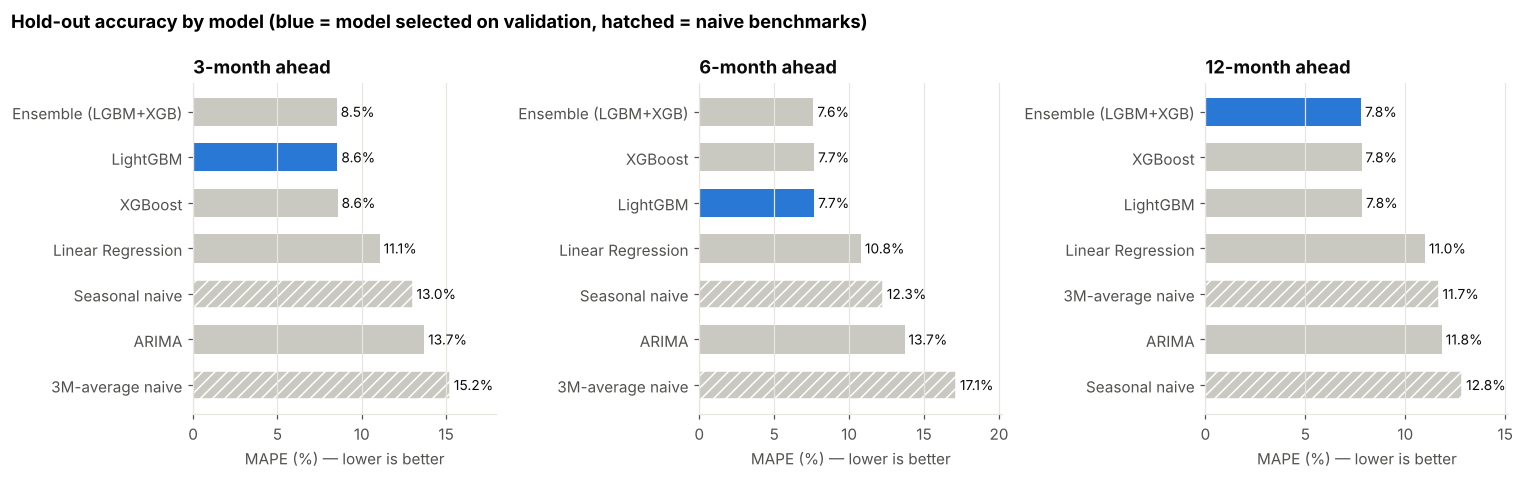

In [21]:
# ---- chart: model comparison (MAPE, fixed origin)
order_hl = {h: SELECTED[h] for h in HORIZONS}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=False)
for ax, h in zip(axes, HORIZONS):
    d = EVAL_FIXED[EVAL_FIXED.Horizon == h].sort_values("MAPE", ascending=False)
    cols = [C[0] if m == order_hl[h] else "#c9c8c1" for m in d.Model]
    bars = ax.barh(d.Model.map(MODEL_NAMES), d.MAPE, color=cols, height=0.62)
    for b, m in zip(bars, d.Model):
        if m in ("NAIVE3", "SNAIVE"):
            b.set_hatch("///"); b.set_edgecolor("white")
    for y, v in enumerate(d.MAPE):
        ax.text(v + d.MAPE.max() * 0.015, y, f"{v:.1f}%", va="center", fontsize=9, color=INK)
    ax.set_title(f"{h}-month ahead", loc="left"); ax.grid(axis="y", visible=False); ax.set_xlim(0, d.MAPE.max() * 1.18)
    ax.set_xlabel("MAPE (%) — lower is better")
fig.suptitle("Hold-out accuracy by model (blue = model selected on validation, hatched = naive benchmarks)", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout(); show(fig, "model_comparison_mape")

In [22]:
# ---- does the validation-selected model also win on the hold-out? (a confirmation, not the selection mechanism)
msgs = []
for h in HORIZONS:
    d = EVAL_FIXED[EVAL_FIXED.Horizon == h].set_index("Model")
    best_hold = d["MAPE"].idxmin()
    ok = SELECTED[h] == best_hold or d.loc[SELECTED[h], "MAPE"] <= d["MAPE"].min() * 1.03
    gain_lr = 100 * (1 - d.loc[SELECTED[h], "MAPE"] / d.loc["LR", "MAPE"])
    msgs.append(f"{h:>2}M  selected = {MODEL_NAMES[SELECTED[h]]:<22} hold-out MAPE {d.loc[SELECTED[h], 'MAPE']:.2f}%  "
                f"vs Linear-Regression baseline {d.loc['LR', 'MAPE']:.2f}%  ({gain_lr:+.0f}% relative improvement)  |  best on hold-out: {MODEL_NAMES[best_hold]}  "
                f"{'✔ consistent' if ok else '⚠ differs — see table'}")
print("\n".join(msgs))

 3M  selected = LightGBM               hold-out MAPE 8.56%  vs Linear-Regression baseline 11.07%  (+23% relative improvement)  |  best on hold-out: Ensemble (LGBM+XGB)  ✔ consistent
 6M  selected = LightGBM               hold-out MAPE 7.67%  vs Linear-Regression baseline 10.79%  (+29% relative improvement)  |  best on hold-out: Ensemble (LGBM+XGB)  ✔ consistent
12M  selected = Ensemble (LGBM+XGB)    hold-out MAPE 7.79%  vs Linear-Regression baseline 10.99%  (+29% relative improvement)  |  best on hold-out: Ensemble (LGBM+XGB)  ✔ consistent


### 10.4 Where does the model work well? — error by aggregation level, skill and data volume
Planners act at district, state and sector level; errors of individual district × skill series partly cancel when aggregated.

**Selected model, fixed-origin hold-out — accuracy by planning level** (WAPE = volume-weighted error)

Horizon,12M,3M,6M
Level,,,
District × skill (series),7.3%,8.5%,7.3%
State × skill,3.7%,5.3%,3.9%
District,3.0%,5.1%,2.5%
Skill (national),2.5%,4.6%,2.1%
Sector (national),2.4%,4.6%,1.4%
State,2.5%,4.7%,1.8%


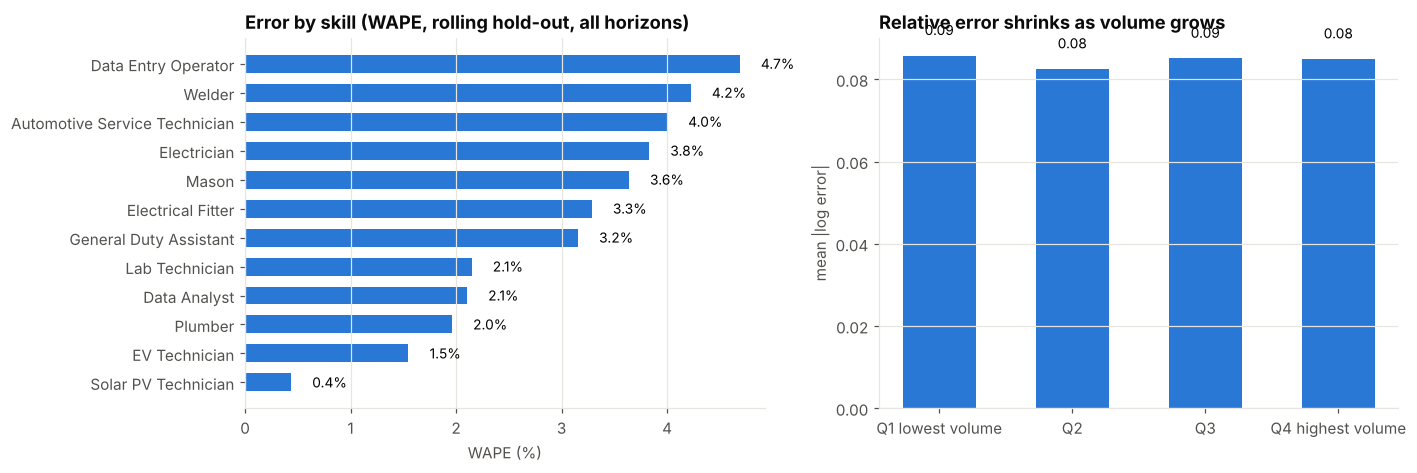

In [23]:
def eval_frame(h, which="fixed"):
    Xt = SPL[h]["test"]
    sel = SELECTED[h]
    d = Xt[["SID", "ORIGIN", "TIER", "y_act"]].copy()
    d["pred"] = TEST_CNT[h][sel]
    d = d.join(META[["STATE", "DISTRICT", "SKILL", "SECTOR"]], on="SID")
    return d[d["ORIGIN"] == CUT] if which == "fixed" else d

agg_rows = []
for h in HORIZONS:
    d = eval_frame(h)
    for level, keys in [("District × skill (series)", ["SID"]), ("District", ["DISTRICT"]), ("State × skill", ["STATE", "SKILL"]),
                        ("State", ["STATE"]), ("Skill (national)", ["SKILL"]), ("Sector (national)", ["SECTOR"])]:
        g = d.groupby(keys)[["y_act", "pred"]].sum()
        m = metrics(g["y_act"], g["pred"])
        agg_rows.append({"Level": level, "Horizon": f"{h}M", "n units": len(g), "MAPE %": m["MAPE"], "WAPE %": m["WAPE"]})
AGG = pd.DataFrame(agg_rows)
display(Markdown("**Selected model, fixed-origin hold-out — accuracy by planning level** (WAPE = volume-weighted error)"))
display(AGG.pivot(index="Level", columns="Horizon", values="WAPE %").loc[["District × skill (series)", "State × skill", "District", "Skill (national)", "Sector (national)", "State"]]
        .style.format("{:.1f}%").background_gradient(cmap="Blues_r", axis=None))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
roll = pd.concat([eval_frame(h, "roll").assign(H=h) for h in HORIZONS])
by_skill = roll.groupby(["SKILL", "H"])[["y_act", "pred"]].sum()
wape_skill = (by_skill.assign(e=(by_skill["pred"] - by_skill["y_act"]).abs()).groupby("SKILL").apply(lambda g: 100 * g["e"].sum() / g["y_act"].sum())).sort_values()
axes[0].barh(wape_skill.index, wape_skill.values, color=C[0], height=0.62)
for i, v in enumerate(wape_skill.values): axes[0].text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_title("Error by skill (WAPE, rolling hold-out, all horizons)", loc="left"); axes[0].grid(axis="y", visible=False); axes[0].set_xlabel("WAPE (%)")
tier_lab = {0: "Q1 lowest volume", 1: "Q2", 2: "Q3", 3: "Q4 highest volume"}
tier_err = roll.assign(r=np.abs(np.log1p(roll["pred"]) - np.log1p(roll["y_act"]))).groupby("TIER")["r"].mean()
axes[1].bar([tier_lab[t] for t in tier_err.index], tier_err.values, color=C[0], width=0.55)
for i, v in enumerate(tier_err.values): axes[1].text(i, v + 0.005, f"{v:.2f}", ha="center", fontsize=9)
axes[1].set_title("Relative error shrinks as volume grows", loc="left"); axes[1].set_ylabel("mean |log error|"); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); show(fig, "error_breakdown")

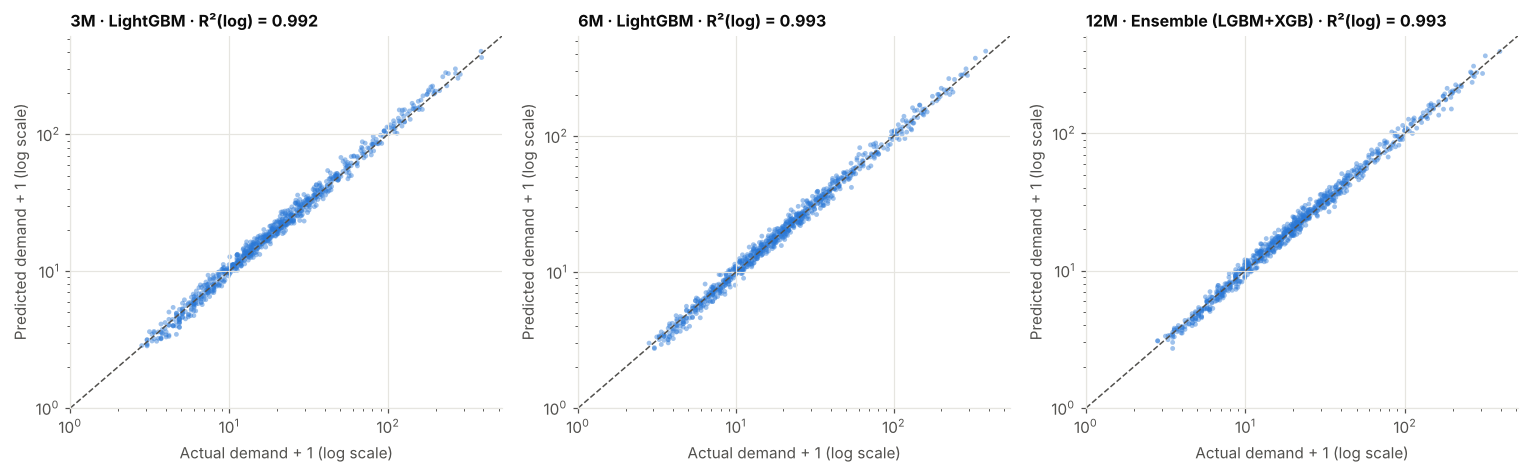

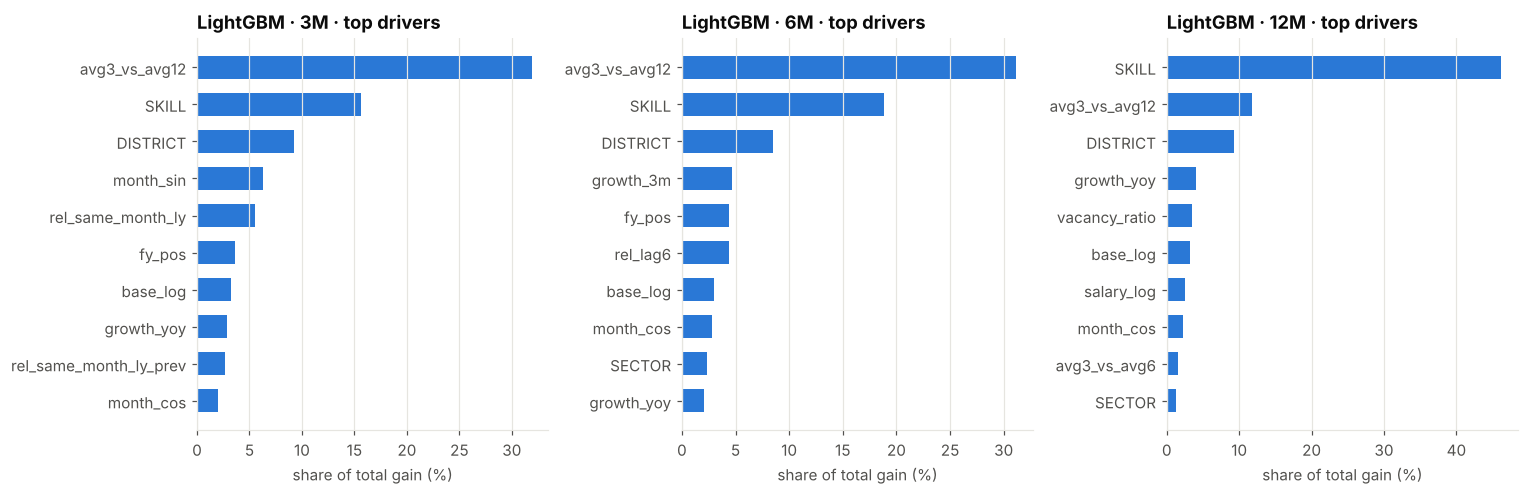

In [24]:
# ---- actual vs predicted + feature importance of the selected / LightGBM model
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, h in zip(axes, HORIZONS):
    d = eval_frame(h)
    ax.scatter(d["y_act"] + 1, d["pred"] + 1, s=10, alpha=0.45, color=C[0], edgecolor="none")
    lim = [1, max(d["y_act"].max(), d["pred"].max()) * 1.3 + 1]
    ax.plot(lim, lim, color=INK2, lw=1, ls="--"); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Actual demand + 1 (log scale)"); ax.set_ylabel("Predicted demand + 1 (log scale)")
    ax.set_title(f"{h}M · {MODEL_NAMES[SELECTED[h]]} · R²(log) = {np.corrcoef(np.log1p(d['y_act']), np.log1p(d['pred']))[0, 1] ** 2:.3f}", loc="left", fontsize=10.5)
fig.tight_layout(); show(fig, "actual_vs_predicted")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, h in zip(axes, HORIZONS):
    cols = NUM_FEATURES + CAT_COLS
    imp = pd.Series(BT_MODELS[h]["LGBM"].booster_.feature_importance("gain"), index=cols)
    imp = (imp / imp.sum() * 100).sort_values().tail(10)
    ax.barh(imp.index, imp.values, color=C[0], height=0.62); ax.grid(axis="y", visible=False)
    ax.set_title(f"LightGBM · {h}M · top drivers", loc="left"); ax.set_xlabel("share of total gain (%)")
fig.tight_layout(); show(fig, "feature_importance")

### 10.5 The role of the NCS anchor — an honest look at what the model does *not* forecast
The ML models forecast the **organic** demand dynamics. The annual NCS re-basing is exogenous. The table shows the hold-out error (fixed origin) if the *future anchor were known* versus if it is *assumed unchanged* — the gap is the anchor effect, not model error.

In [25]:
anch_rows = []
for h in HORIZONS:
    d = eval_frame(h).copy()
    tgt_t = CUT + h
    key = pd.MultiIndex.from_arrays([d["STATE"], np.full(len(d), tgt_t // 12)])
    f_tgt = (ANCH_VAC[REF_BT].reindex(d["STATE"]).to_numpy() / _vac_long.reindex(key).to_numpy())     # nominal -> back-test units at the target month
    nominal_actual = d["y_act"].to_numpy() / f_tgt
    m_known = metrics(d["y_act"], d["pred"])
    m_const = metrics(nominal_actual, d["pred"])
    anch_rows.append({"Horizon": f"{h}M", "WAPE — anchor known (model skill) %": m_known["WAPE"], "WAPE — anchor assumed unchanged %": m_const["WAPE"]})
display(pd.DataFrame(anch_rows).set_index("Horizon").style.format("{:.1f}"))
print("Take-away: demand forecasts are issued at the latest published NCS anchor; when NCS publishes new state totals, forecasts are rescaled with the "
      "scenario multiplier (§12) — the ML model itself does not need re-training for that.")

,WAPE — anchor known (model skill) %,WAPE — anchor assumed unchanged %
Horizon,,
3M,8.5,52.8
6M,7.3,54.3
12M,7.3,53.5


Take-away: demand forecasts are issued at the latest published NCS anchor; when NCS publishes new state totals, forecasts are rescaled with the scenario multiplier (§12) — the ML model itself does not need re-training for that.


## 11. The one thing no model can learn: next year's NCS anchor

Everything above measures accuracy **in real (constant-anchor) terms**. A planner, however, wants *nominal* demand — and nominal demand also depends on the NCS anchor of the target financial year, which is not known when the forecast is made.

We therefore treat the anchor explicitly rather than hiding it:

* **Base scenario** = median state-level anchor growth of the most recent year **not affected by the NCS series break** (the transition before the flagged year).
* **Low / High scenarios** = 25th / 75th percentile of the same distribution.
* The scenario spread is added to the model's own error in the prediction interval (§12), so confidence is lower exactly where the macro uncertainty bites.

,Anchor growth next FY,Derived from
Scenario,,
low,-8.6%,state-level NCS anchor growth FY2024-25 vs FY2...
base,+7.3%,state-level NCS anchor growth FY2024-25 vs FY2...
high,+35.9%,state-level NCS anchor growth FY2024-25 vs FY2...


,Real-terms WAPE %,Nominal WAPE % (base scenario),Nominal bias %
Horizon,,,
3M,8.5,49.5,-49.4
6M,7.3,51.0,-50.9
12M,7.3,50.1,-50.1


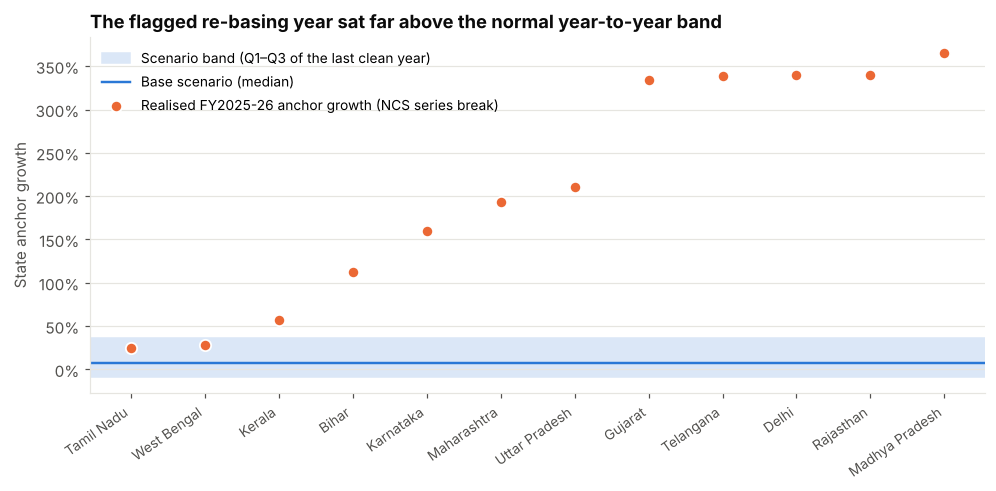

10 of 12 states exceeded the High scenario in FY2025-26 — consistent with the dataset's own NCS_SERIES_BREAK flag.


In [26]:
growth_fy = ANCH_VAC.pct_change(axis=1)
CLEAN_FY  = BREAK_FY - 1                                   # latest FY transition not touched by the series break
g_clean   = growth_fy[CLEAN_FY]
SCEN = {"low": float(g_clean.quantile(.25)), "base": float(g_clean.median()), "high": float(g_clean.quantile(.75))}
if ANCHOR_GROWTH_OVERRIDE is not None:
    SCEN["base"] = float(ANCHOR_GROWTH_OVERRIDE); SCEN["low"] = min(SCEN["low"], SCEN["base"]); SCEN["high"] = max(SCEN["high"], SCEN["base"])
G_BASE = SCEN["base"]
Q_ANCH = 0.5 * (SCEN["high"] - SCEN["low"]) / (1 + SCEN["base"])         # relative half-width of the scenario band

display(pd.DataFrame({"Scenario": list(SCEN.keys()), "Anchor growth next FY": [f"{v:+.1%}" for v in SCEN.values()],
                      "Derived from": [f"state-level NCS anchor growth FY{FY_LABEL[CLEAN_FY]} vs FY{FY_LABEL[CLEAN_FY-1]}"] * 3}).set_index("Scenario"))

# ---- reality check: what would the *nominal* error have been in the hold-out year?
rows = []
for h in HORIZONS:
    d = eval_frame(h)                                                      # selected model, fixed origin, back-test units
    tgt_fy = (CUT + h) // 12
    realised = (ANCH_VAC[tgt_fy].reindex(d["STATE"]) / ANCH_VAC[REF_BT].reindex(d["STATE"])).to_numpy()
    y_nom = d["y_act"].to_numpy() * realised                               # what was actually reported (nominal)
    p_nom = d["pred"].to_numpy() * (1 + SCEN["base"]) ** (tgt_fy - REF_BT)
    rows.append({"Horizon": f"{h}M", "Real-terms WAPE %": metrics(d["y_act"], d["pred"])["WAPE"],
                 "Nominal WAPE % (base scenario)": metrics(y_nom, p_nom)["WAPE"],
                 "Nominal bias %": (p_nom.sum() / y_nom.sum() - 1) * 100})
display(pd.DataFrame(rows).set_index("Horizon").round(1))

real_g = growth_fy[BREAK_FY]
fig, ax = plt.subplots(figsize=(10.5, 4.2))
srt = real_g.sort_values()
ax.axhspan(SCEN["low"] * 100, SCEN["high"] * 100, color="#dbe7f7", zorder=0, label="Scenario band (Q1–Q3 of the last clean year)")
ax.axhline(SCEN["base"] * 100, color=C[0], lw=1.6, label="Base scenario (median)")
ax.scatter(range(len(srt)), srt.values * 100, color=C[1], s=55, zorder=3, edgecolor="white", linewidth=1.2,
           label=f"Realised FY{FY_LABEL[BREAK_FY]} anchor growth (NCS series break)")
ax.set_xticks(range(len(srt))); ax.set_xticklabels(srt.index, rotation=35, ha="right", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylabel("State anchor growth"); ax.grid(axis="x", visible=False)
ax.set_title("The flagged re-basing year sat far above the normal year-to-year band", loc="left"); ax.legend(loc="upper left", fontsize=9)
show(fig, "anchor_scenarios")
n_above = int((real_g > SCEN["high"]).sum())
print(f"{n_above} of {len(real_g)} states exceeded the High scenario in FY{FY_LABEL[BREAK_FY]} — consistent with the dataset's own NCS_SERIES_BREAK flag.")

**How to read this.** In real terms the selected models are accurate (first column). The *nominal* error in the hold-out year is dominated by a **methodological re-basing of the NCS series** (flagged in the data), not by forecasting skill — and no model trained on history could have anticipated it. That is why the hand-over carries explicit scenario bands and why relative rankings (which skill grows faster than another, which district is under-served) are the most robust output for planners.

## 12. Calibrated uncertainty and the confidence score

* **Model error band** — for each horizon and each *volume × volatility* bucket, the 80th percentile of the relative absolute error `|actual − forecast| / max(forecast, 1)` of the **selected model on the rolling hold-out** (a split-conformal style interval; buckets with fewer than 30 cases fall back to the horizon-level quantile). April targets (the ramp-in month of a re-based series) are calibrated separately because their errors are markedly larger; our 3 / 6 / 12-month targets from a March origin fall in June, September and March, so they use the regular-month calibration.
* **Anchor band** — the scenario spread of §11 (relative to the base scenario), added in quadrature whenever the target month falls in a later financial year than the origin.
* **Confidence** = `1 / (1 + q)`, where `q` is the **model-error** half-width (80 % level) of the series' bucket; it lies in (0, 1] and measures how reliable the *organic demand forecast* is. A second score, **`confidence_incl_anchor`** = `1 / (1 + w)`, also prices the unknown next-FY NCS anchor (`w` = combined half-width, i.e. the width of the low/high interval). Both are *empirical reliability scores*, not probabilities: 0.89 means the typical model band is about ±12 % of the forecast.

The interval is validated by **series-grouped cross-validation**: quantiles are estimated on 80 % of the series and coverage is checked on the held-out 20 %.

In [27]:
VOL_ORDER  = ["Q1 lowest volume", "Q2", "Q3", "Q4 highest volume"]
STAB_ORDER = ["Calm", "Moderate", "Volatile"]
VOLA_CUTS  = SPL[3]["train"]["volatility_6m"].quantile([1 / 3, 2 / 3]).to_numpy()        # terciles of 6-month volatility (training data only)
KEYS, MIN_N = ["vol_bucket", "stab_bucket", "tgt_apr"], 30

def add_buckets(frame, h):
    out = frame.copy()
    out["vol_bucket"]  = pd.Series(out["TIER"].map(dict(enumerate(VOL_ORDER))), index=out.index).astype(str)
    out["stab_bucket"] = pd.cut(out["volatility_6m"], [-np.inf, VOLA_CUTS[0], VOLA_CUTS[1], np.inf], labels=STAB_ORDER).astype(str)
    out["tgt_apr"]     = ((out["ORIGIN"] + h) % 12 == 0)                                  # April targets: new-FY ramp-in
    return out

parts = []
for h in HORIZONS:
    Xt = SPL[h]["test"]
    d = add_buckets(Xt[["SID", "ORIGIN", "TIER", "volatility_6m", "y_act"]], h)
    d["pred"], d["h"] = TEST_CNT[h][SELECTED[h]], h
    parts.append(d)
res_df = pd.concat(parts, ignore_index=True)
res_df["abs_res"] = np.abs(res_df["y_act"] - res_df["pred"]) / np.maximum(res_df["pred"], 1)    # relative absolute error

def fit_q(r):
    fine = r.groupby(KEYS)["abs_res"].agg(q80=lambda s: s.quantile(.8), n="size").reset_index()
    fb   = r.groupby("tgt_apr")["abs_res"].quantile(.8)
    return fine, fb, float(r["abs_res"].quantile(.8))

def apply_q(frame, fit):
    fine, fb, overall = fit
    t = frame[KEYS].merge(fine, on=KEYS, how="left")                                      # left-merge keeps the row order
    fallback = frame["tgt_apr"].map(fb).fillna(overall).to_numpy()
    return np.where(t["n"].fillna(0).to_numpy() >= MIN_N, t["q80"].to_numpy(), fallback)

QFIT = {h: fit_q(res_df[res_df["h"] == h]) for h in HORIZONS}

cov = []
for h in HORIZONS:
    r = res_df[res_df["h"] == h].reset_index(drop=True); covered = np.zeros(len(r), bool)
    for tr_i, te_i in GroupKFold(n_splits=5).split(r, groups=r["SID"]):
        q = apply_q(r.iloc[te_i], fit_q(r.iloc[tr_i]))
        covered[te_i] = r["abs_res"].to_numpy()[te_i] <= q
    cov.append({"Horizon": f"{h}M", "Target coverage": "80%", "Empirical coverage on held-out series": f"{covered.mean():.1%}",
                "Regular target months only": f"{covered[~r['tgt_apr'].to_numpy()].mean():.1%}"})
display(pd.DataFrame(cov).set_index("Horizon"))

display(Markdown("**Relative half-width of the model-error band (80 % level), regular target months — 12M horizon**"))
q12 = QFIT[12][0]
display(q12[~q12["tgt_apr"]].pivot(index="vol_bucket", columns="stab_bucket", values="q80").reindex(VOL_ORDER)[STAB_ORDER].round(3))
apr_gap = res_df.groupby("tgt_apr")["abs_res"].median()
print(f"Median relative error: regular target months {apr_gap[False]:.1%}  |  April targets {apr_gap.get(True, np.nan):.1%} (new financial-year ramp-in)")

,Target coverage,Empirical coverage on held-out series,Regular target months only
Horizon,,,
3M,80%,79.9%,79.9%
6M,80%,80.0%,80.0%
12M,80%,79.9%,79.9%


**Relative half-width of the model-error band (80 % level), regular target months — 12M horizon**

stab_bucket,Calm,Moderate,Volatile
vol_bucket,,,
Q1 lowest volume,0.143,0.146,0.158
Q2,0.119,0.116,0.120
Q3,0.117,0.115,0.114
Q4 highest volume,0.112,0.119,0.113


Median relative error: regular target months 6.5%  |  April targets 22.5% (new financial-year ramp-in)


## 13. Final forecast — 3M / 6M / 12M for every district × skill

For each horizon the model **selected on validation (§8.1)** is re-trained on **all available history** — every sample whose target is known as of the last data month — using the hyper-parameters tuned in §8 and the constant-anchor units of the latest financial year (= the raw units of the latest year). It is then asked for the next 3, 6 and 12 months. Nominal values apply the base anchor scenario.

In [28]:
FE_FN, FINAL = {}, {}
for h in HORIZONS:
    X = build_features(panel_fin, h)
    X["valid"] = X[NUM_FEATURES].notna().all(axis=1)
    tr = X[X["valid"] & X["y_rel"].notna()]                                    # only samples whose target is already observed
    pr = X[X["valid"] & (X["ORIGIN"] == T_LAST)].copy()                        # forecast origin = last data month
    assert (tr["ORIGIN"] + h).max() <= T_LAST and len(pr) == len(SIDS), "unexpected forecast-origin rows"
    r = pr["base_log"].rank(pct=True, method="first")
    pr["TIER"] = np.clip(np.ceil(r * 4) - 1, 0, 3).astype(int)
    pr = pr.set_index("SID").reindex(SIDS)
    pr["SID"] = pr.index
    FE_FN[h], FINAL[h] = tr, pr.reset_index(drop=True)

def fit_predict_final(h, kind):
    tr, pr = FE_FN[h], FINAL[h]
    ytr = tr["y_rel"].to_numpy()
    if kind == "LR":
        return make_lr().fit(design(tr, "lin"), ytr).predict(design(pr, "lin"))
    plg = make_lgb(**TUNED[h]["lgb"]).fit(design(tr, "tree"), ytr).predict(design(pr, "tree")) if kind in ("LGBM", "ENS") else None
    pxg = make_xgb(**TUNED[h]["xgb"]).fit(design(tr, "tree"), ytr).predict(design(pr, "tree")) if kind in ("XGB", "ENS") else None
    return {"LGBM": plg, "XGB": pxg, "ENS": None if kind != "ENS" else (plg + pxg) / 2}[kind]

t0 = time.time()
REL_FN = {h: fit_predict_final(h, SELECTED[h]) for h in HORIZONS}
print(f"Final models trained on all history in {time.time() - t0:.0f}s  ·  "
      + "  ·  ".join(f"{h}M: {MODEL_NAMES[SELECTED[h]]} ({len(FE_FN[h]):,} samples)" for h in HORIZONS))

Final models trained on all history in 3s  ·  3M: LightGBM (23,436 samples)  ·  6M: LightGBM (21,168 samples)  ·  12M: Ensemble (LGBM+XGB) (16,632 samples)


In [29]:
# ---------------------------------------------------------------- assemble forecasts with intervals and confidence
fc = {}
for h in HORIZONS:
    pr = add_buckets(FINAL[h], h)
    n_cross = (T_LAST + h) // 12 - LAST_FY                                    # financial years between origin and target
    ca  = pred_count(pr, REL_FN[h])                                           # latest-FY units, organic model forecast
    nom = ca * (1 + G_BASE) ** n_cross                                        # nominal, base anchor scenario
    q80 = apply_q(pr, QFIT[h])
    w   = np.sqrt(q80 ** 2 + (Q_ANCH * (n_cross > 0)) ** 2)                   # combined relative half-width
    lo, hi = np.maximum(nom - w * np.maximum(nom, 1), 0), nom + w * np.maximum(nom, 1)
    fc[h] = pd.DataFrame({"nom": nom, "lo": lo, "hi": hi, "conf": 1 / (1 + q80), "conf_anchor": 1 / (1 + w), "n_cross": n_cross, "vol_bucket": pr["vol_bucket"].to_numpy()}, index=SIDS)
    assert np.isfinite(fc[h][["nom", "lo", "hi", "conf", "conf_anchor"]].to_numpy()).all(), "non-finite forecast"

last_nom = df[df["t_idx"] == T_LAST].set_index("SERIES_ID")["DEMAND"].reindex(SIDS)
avg3_nom = df[df["t_idx"] > T_LAST - 3].groupby("SERIES_ID")["DEMAND"].mean().reindex(SIDS)
avg12    = df[df["t_idx"] > T_LAST - 12].groupby("SERIES_ID")["DEMAND"].mean().reindex(SIDS)
den      = np.maximum(last_nom, 1)

H = pd.DataFrame(index=SIDS)
H["district"], H["skill"], H["state"], H["sector"], H["nco_code"] = META["DISTRICT"], META["SKILL"], META["STATE"], META["SECTOR"], META["NCO_CODE"]
H["current_demand"]        = last_nom.astype(int)
H["current_demand_3m_avg"] = avg3_nom.round(1)
for h in HORIZONS:
    H[f"forecast_{h}m"] = np.rint(fc[h]["nom"]).astype(int)
H["demand_growth"] = ((H["forecast_12m"] - last_nom) / den * 100).round(1)         # like-for-like: same calendar month, 12 months apart
H["growth_3m_pct"] = ((H["forecast_3m"]  - last_nom) / den * 100).round(1)         # not seasonally adjusted
H["growth_6m_pct"] = ((H["forecast_6m"]  - last_nom) / den * 100).round(1)         # not seasonally adjusted
H["confidence"]    = np.mean([fc[h]["conf"] for h in HORIZONS], axis=0).round(2)
H["confidence_incl_anchor"] = np.mean([fc[h]["conf_anchor"] for h in HORIZONS], axis=0).round(2)
for h in HORIZONS:
    H[f"forecast_{h}m_low"]  = np.rint(fc[h]["lo"]).astype(int)
    H[f"forecast_{h}m_high"] = np.rint(fc[h]["hi"]).astype(int)
    H[f"confidence_{h}m"]    = fc[h]["conf"].round(2)
H["demand_trend"]    = np.select([H["demand_growth"] >= 20, H["demand_growth"] >= 5, H["demand_growth"] > -5], ["High growth", "Growth", "Stable"], "Decline")
H["low_volume_flag"] = (avg12 < 10).astype(int)
H["volume_tier"]     = fc[12]["vol_bucket"]
H["model_used"]      = " | ".join(f"{h}M: {MODEL_NAMES[SELECTED[h]]}" for h in HORIZONS)
H["last_data_month"] = f"{LAST_DATE:%Y-%m}"
H["anchor_scenario"] = f"base ({G_BASE:+.1%} next-FY NCS anchor growth)"
handover = H.reset_index(drop=True).sort_values(["state", "district", "skill"]).reset_index(drop=True)

fc_months = {h: (LAST_DATE + pd.DateOffset(months=h)).strftime("%b-%Y") for h in HORIZONS}
display(Markdown(f"**Forecast origin:** {LAST_DATE:%b-%Y} → targets: **3M = {fc_months[3]}**, **6M = {fc_months[6]}**, **12M = {fc_months[12]}**  ·  models: " + " · ".join(f"**{h}M {MODEL_NAMES[SELECTED[h]]}**" for h in HORIZONS)))
display(Markdown("**Hand-over preview (exact fields requested in the brief):**"))
display(handover[handover["skill"] == "Electrician"][["district", "skill", "current_demand", "forecast_3m", "forecast_6m", "forecast_12m", "demand_growth", "confidence"]].head(8))

**Forecast origin:** Mar-2026 → targets: **3M = Jun-2026**, **6M = Sep-2026**, **12M = Mar-2027**  ·  models: **3M LightGBM** · **6M LightGBM** · **12M Ensemble (LGBM+XGB)**

**Hand-over preview (exact fields requested in the brief):**

,district,skill,current_demand,forecast_3m,forecast_6m,forecast_12m,demand_growth,confidence
5,Banka,Electrician,74,70,73,76,2.7,0.90
17,Muzaffarpur,Electrician,91,94,98,96,5.5,0.90
29,Patna,Electrician,75,76,79,78,4.0,0.90
41,Purbi Champaran,Electrician,77,78,81,81,5.2,0.90
53,Saran,Electrician,64,74,76,77,20.3,0.90
65,East,Electrician,74,78,80,79,6.8,0.90
77,New Delhi,Electrician,227,244,250,251,10.6,0.89
89,North West,Electrician,231,202,205,204,-11.7,0.89


### Forecast visuals

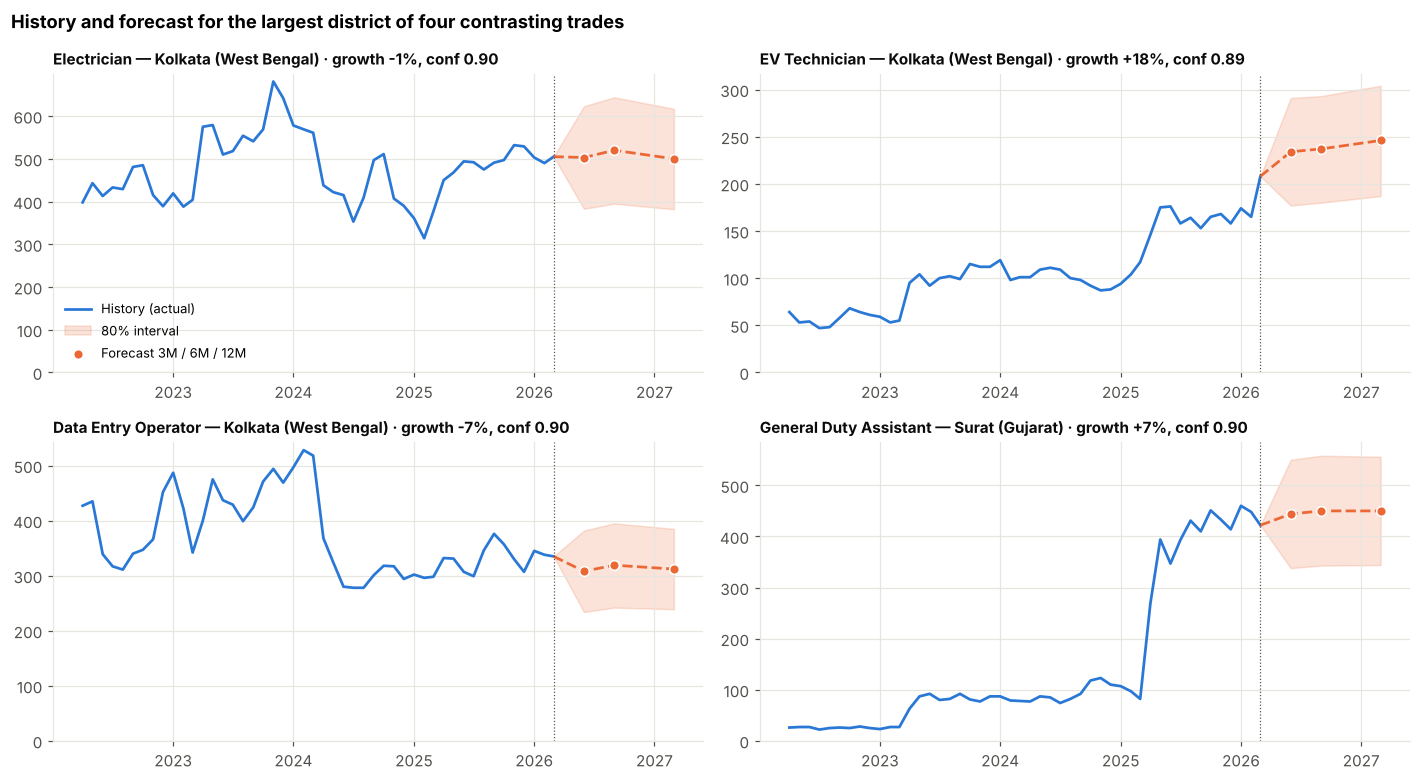

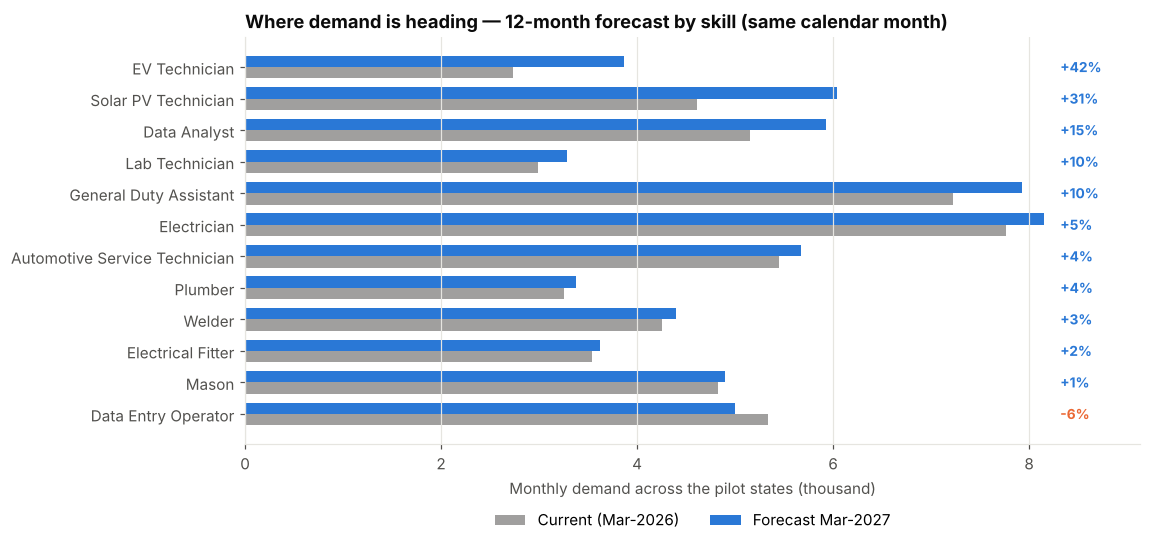

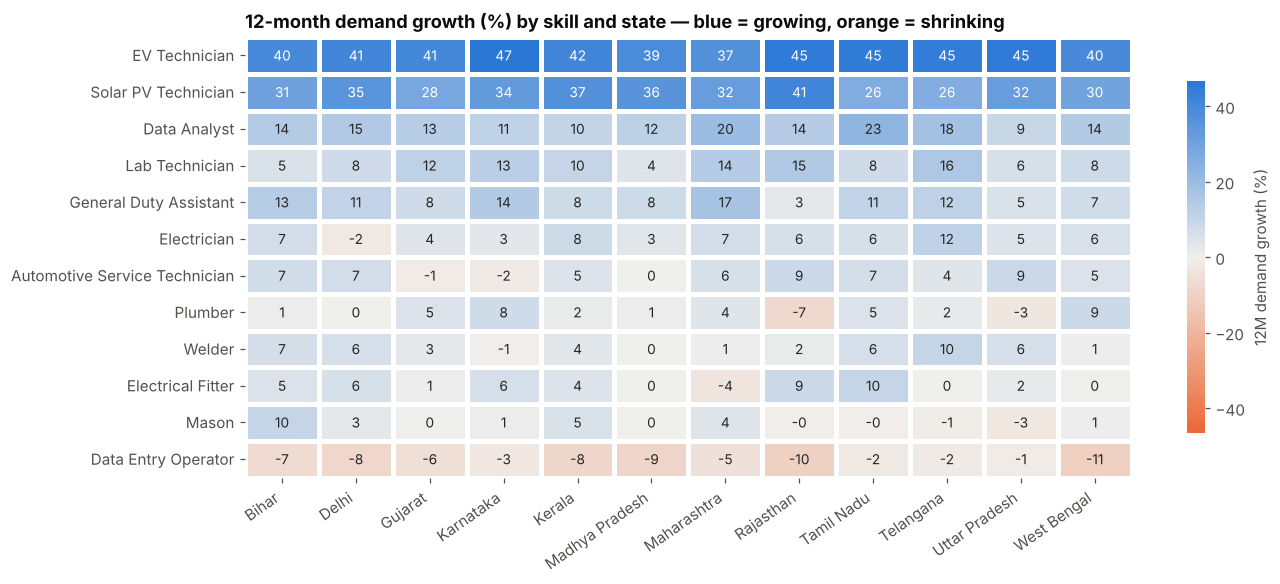

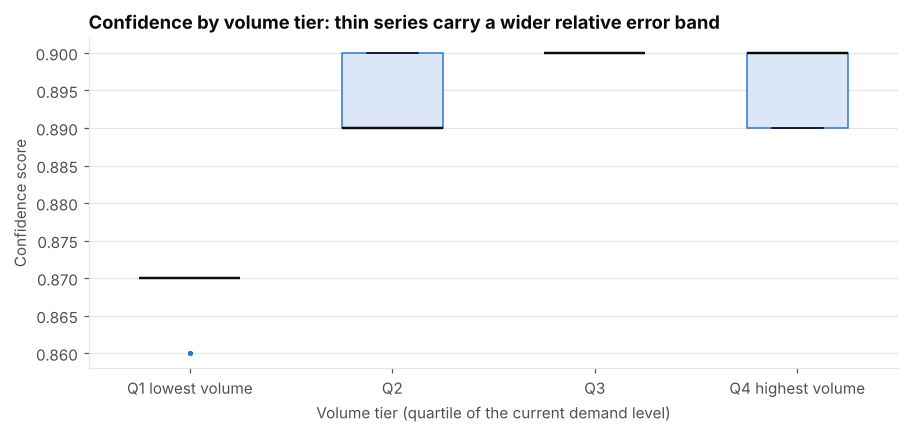

volume_tier                  Q1 lowest volume     Q2    Q3  Q4 highest volume
confidence             mean              0.87  0.894  0.90              0.897
                       min               0.86  0.890  0.90              0.890
                       max               0.87  0.900  0.90              0.900
confidence_incl_anchor mean              0.80  0.810  0.81              0.810
                       min               0.79  0.810  0.81              0.810
                       max               0.80  0.810  0.81              0.810


In [30]:
# ---- (1) example series: history, point forecasts and 80 % bands
picks = []
for skill in ["Electrician", "EV Technician", "Data Entry Operator", "General Duty Assistant"]:
    picks.append(handover[handover["skill"] == skill].sort_values("current_demand_3m_avg").iloc[-1])
fig, axes = plt.subplots(2, 2, figsize=(13, 7.2))
for ax, row in zip(axes.ravel(), picks):
    sid = f"{row['state']} | {row['district']} | {row['skill']}"
    hs = df[df["SERIES_ID"] == sid].set_index("DATE")["DEMAND"]
    xs = [LAST_DATE] + [LAST_DATE + pd.DateOffset(months=h) for h in HORIZONS]
    ys = [hs.iloc[-1]] + [row[f"forecast_{h}m"] for h in HORIZONS]
    lo = [hs.iloc[-1]] + [row[f"forecast_{h}m_low"] for h in HORIZONS]; hi = [hs.iloc[-1]] + [row[f"forecast_{h}m_high"] for h in HORIZONS]
    ax.plot(hs.index, hs.values, color=C[0], lw=1.8, label="History (actual)")
    ax.fill_between(xs, lo, hi, color=C[1], alpha=0.18, label="80% interval")
    ax.plot(xs, ys, color=C[1], lw=1.8, ls="--"); ax.scatter(xs[1:], ys[1:], color=C[1], s=40, zorder=3, edgecolor="white", label="Forecast 3M / 6M / 12M")
    ax.axvline(LAST_DATE, color=INK2, lw=0.8, ls=":")
    ax.set_title(f"{row['skill']} — {row['district']} ({row['state']}) · growth {row['demand_growth']:+.0f}%, conf {row['confidence']:.2f}", loc="left", fontsize=10)
    ax.set_ylim(0, None)
axes[0, 0].legend(loc="lower left", fontsize=8.5)
fig.suptitle("History and forecast for the largest district of four contrasting trades", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); show(fig, "forecast_examples")

# ---- (2) national view by skill
def rollup(g):
    cur = g["current_demand"].sum()
    return pd.Series({"districts": len(g), "current_demand": cur, "current_demand_3m_avg": round(g["current_demand_3m_avg"].sum(), 1),
                      "forecast_3m": g["forecast_3m"].sum(), "forecast_6m": g["forecast_6m"].sum(), "forecast_12m": g["forecast_12m"].sum(),
                      "demand_growth": round((g["forecast_12m"].sum() - cur) / max(cur, 1) * 100, 1)})
nat_roll = handover.groupby(["sector", "skill"]).apply(rollup).reset_index().sort_values("demand_growth")
fig, ax = plt.subplots(figsize=(10.5, 4.8)); y = np.arange(len(nat_roll)); hh = 0.36
ax.barh(y - hh / 2, nat_roll["current_demand"] / 1000, height=hh, color=INK2, alpha=0.55, label=f"Current ({LAST_DATE:%b-%Y})")
ax.barh(y + hh / 2, nat_roll["forecast_12m"] / 1000, height=hh, color=C[0], label=f"Forecast {fc_months[12]}")
xmax = max(nat_roll["forecast_12m"].max(), nat_roll["current_demand"].max()) / 1000
for yi, g in zip(y, nat_roll["demand_growth"]):
    gr = int(round(g)); ax.text(xmax * 1.02, yi, (f"{gr:+d}%" if gr else "0%"), va="center", fontsize=9, color=C[0] if g >= 0 else C[1], fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels(nat_roll["skill"]); ax.grid(axis="y", visible=False); ax.set_xlim(0, xmax * 1.12)
ax.set_xlabel("Monthly demand across the pilot states (thousand)"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
ax.set_title("Where demand is heading — 12-month forecast by skill (same calendar month)", loc="left"); show(fig, "forecast_by_skill")

# ---- (3) heat-map: 12M growth, skill × state
ss = handover.groupby(["state", "skill"]).apply(rollup).reset_index()
hm = ss.pivot(index="skill", columns="state", values="demand_growth")
hm = hm.loc[nat_roll.sort_values("demand_growth", ascending=False)["skill"]]
fig, ax = plt.subplots(figsize=(13, 5.2)); lim = float(np.nanmax(np.abs(hm.values)))
sns.heatmap(hm, annot=True, fmt=".0f", cmap=DIVERGING, center=0, vmin=-lim, vmax=lim, linewidths=2, linecolor="white",
            cbar_kws={"label": "12M demand growth (%)", "shrink": 0.8}, ax=ax, annot_kws={"size": 9}); ax.grid(False)
ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title("12-month demand growth (%) by skill and state — blue = growing, orange = shrinking", loc="left")
plt.xticks(rotation=35, ha="right"); show(fig, "growth_heatmap")

# ---- (4) confidence by volume tier
fig, ax = plt.subplots(figsize=(9.5, 3.9))
data = [handover.loc[handover["volume_tier"] == t, "confidence"].values for t in VOL_ORDER]
bp = ax.boxplot(data, tick_labels=VOL_ORDER, vert=True, widths=0.5, patch_artist=True, medianprops={"color": INK, "lw": 1.6}, flierprops={"marker": "o", "ms": 3, "mfc": C[0], "mec": "none"})
for b in bp["boxes"]: b.set(facecolor="#dbe7f7", edgecolor=C[0])
ax.set_ylabel("Confidence score"); ax.set_xlabel("Volume tier (quartile of the current demand level)"); ax.grid(axis="x", visible=False)
ax.set_title("Confidence by volume tier: thin series carry a wider relative error band", loc="left")
show(fig, "confidence_distribution")
print(handover.groupby("volume_tier")[["confidence", "confidence_incl_anchor"]].agg(["mean", "min", "max"]).reindex(VOL_ORDER).round(3).T.to_string())

**Reading the confidence scores honestly.** `confidence` measures how reliable the *organic* forecast is — thin, volatile series score lower. Every forecast here crosses into the next financial year, so the unknown NCS anchor adds the same macro band to all of them; `confidence_incl_anchor` includes it and is therefore uniformly lower and tightly clustered. Use `forecast_*_low` / `forecast_*_high` for scenario work and the *relative* ranking of growth rates for prioritisation.

## 14. Validation of the hand-over

Before anything is handed to Member 2 the output is checked automatically: schema, uniqueness, ranges, interval ordering and plausibility. A failed check stops the notebook.

In [31]:
req = ["district", "skill", "current_demand", "forecast_3m", "forecast_6m", "forecast_12m", "demand_growth", "confidence"]
checks = {
  "All required hand-over fields present":                          all(c in handover.columns for c in req),
  "Exactly one row per district × skill series":                    len(handover) == META.shape[0] and not handover.duplicated(["state", "district", "skill"]).any(),
  "No missing values in hand-over fields":                          not handover[req].isna().any().any(),
  "Forecasts are non-negative integers":                            bool((handover[["forecast_3m", "forecast_6m", "forecast_12m"]] >= 0).all().all()),
  "Confidence scores within (0, 1]":                                bool(all(handover[c].between(0, 1).all() and (handover[c] > 0).all() for c in ["confidence", "confidence_incl_anchor"])),
  "Interval ordering low ≤ forecast ≤ high (all horizons)":         all(((handover[f"forecast_{h}m_low"] <= handover[f"forecast_{h}m"]) & (handover[f"forecast_{h}m"] <= handover[f"forecast_{h}m_high"])).all() for h in HORIZONS),
  "Every series has a complete history":                            bool((df.groupby("SERIES_ID").size() == len(full_idx)).all()),
  "demand_growth reproducible from the delivered fields":           bool(np.allclose(handover["demand_growth"], ((handover["forecast_12m"] - handover["current_demand"]) / handover["current_demand"].clip(lower=1) * 100), atol=0.06)),
}
ratio = (handover["forecast_12m"] + 1) / (handover["current_demand_3m_avg"] + 1)
checks["Forecast/current ratio plausible (all series within 0.05×–20×)"] = bool(ratio.between(0.05, 20).all())
display(pd.DataFrame({"Check": checks.keys(), "Passed": ["✅" if v else "❌" for v in checks.values()]}).set_index("Check"))
assert all(checks.values()), "hand-over validation failed"
print(f"Forecast ÷ current 3-month run-rate: median {ratio.median():.2f}×, 5th–95th percentile {ratio.quantile(.05):.2f}× – {ratio.quantile(.95):.2f}×")

# ---------------------------------------------------------------- hand-over summary (kept in memory; Part 2 consumes it)
hold = EVAL_FIXED.set_index(["Model", "Horizon"])
payload = {
  "metadata": {
    "problem_statement": "SIH 2026 · PS 26246 · AI-Enabled Labour Market Intelligence — Part 1: Demand Forecasting",
    "generated_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
    "model_per_horizon": {f"{h}m": MODEL_NAMES[SELECTED[h]] for h in HORIZONS},
    "data_last_month": f"{LAST_DATE:%Y-%m}", "forecast_months": {f"{h}m": fc_months[h] for h in HORIZONS},
    "series_count": int(len(handover)), "states": int(handover["state"].nunique()), "skills": int(handover["skill"].nunique()),
    "units": "monthly demand (job-demand signal) at the target month, nominal, rounded to integers",
    "anchor_scenarios_next_fy_growth": {k: round(v, 4) for k, v in SCEN.items()}, "scenario_used": "base",
    "holdout_fixed_origin_metrics_selected_model": {f"{h}m": {k: round(float(hold.loc[(SELECTED[h], h), k]), 2) for k in ("MAE", "RMSE", "MAPE", "WAPE")} for h in HORIZONS},
    "field_definitions": {
      "current_demand": "demand in the last observed month", "current_demand_3m_avg": "average of the last three observed months (run-rate)",
      "forecast_3m/6m/12m": "forecast monthly demand 3 / 6 / 12 months after the last data month (base anchor scenario)",
      "demand_growth": "% change of forecast_12m versus current_demand (same calendar month one year apart, so seasonality cancels; denominator floored at 1)",
      "growth_3m_pct / growth_6m_pct": "% change versus current_demand; NOT seasonally adjusted",
      "forecast_*_low/high": "80% prediction interval incl. model error and anchor-scenario spread",
      "confidence": "mean over horizons of 1 / (1 + q), q = model-error half-width (80% level, relative) of the series' volume x volatility bucket; reliability of the organic forecast, empirical score in (0,1]",
      "confidence_incl_anchor": "same but with the next-FY NCS anchor uncertainty added (1 / (1 + w), w = half-width of the low/high interval)",
      "low_volume_flag": "1 if average monthly demand over the last 12 months is below 10 (the dataset flags counts <= 8 as low-count) — treat percentages with care",
      "volume_tier": "quartile of the 3-month demand level in the cross-section of series (Q1 lowest … Q4 highest)"},
    "caveats": ["Nominal level depends on the next-FY NCS anchor, which is unknown; see anchor_scenarios_next_fy_growth.",
                f"FY{FY_LABEL[BREAK_FY]} NCS series carries a series-break flag; relative rankings are more robust than absolute levels.",
                f"Only {df['FY_IDX'].nunique()} financial years of history are available."]},
}
print("✔ Part 1 hand-over validated and kept in memory — Part 2 below consumes it (no files are written here).")

,Passed
Check,
All required hand-over fields present,✅
Exactly one row per district × skill series,✅
No missing values in hand-over fields,✅
Forecasts are non-negative integers,✅
"Confidence scores within (0, 1]",✅
Interval ordering low ≤ forecast ≤ high (all horizons),✅
Every series has a complete history,✅
demand_growth reproducible from the delivered fields,✅
Forecast/current ratio plausible (all series within 0.05×–20×),✅


Forecast ÷ current 3-month run-rate: median 1.04×, 5th–95th percentile 0.92× – 1.37×
✔ Part 1 hand-over validated and kept in memory — Part 2 below consumes it (no files are written here).


## 15. Checklist — Part 1 completion criteria from the brief

In [32]:
done = {
  "Demand dataset ready":                                      len(raw) > 0 and df["SERIES_ID"].nunique() > 0,
  "Data cleaning complete (audit table above)":                len(audit_df) >= 8 and df[TS_COLS].isna().sum().sum() == 0,
  "Features ready":                                            len(NUM_FEATURES) >= 20 and all(h in FE_BT for h in HORIZONS),
  "Baseline model trained (Linear Regression)":                "LR" in TEST_CNT[3],
  "Main model(s) trained (LightGBM, XGBoost) + ARIMA": all(k in TEST_CNT[3] for k in ("LGBM", "XGB")) and len(STAT["ARIMA"]) > 0,
  "Models evaluated using MAE / RMSE / MAPE":                  {"MAE", "RMSE", "MAPE"} <= set(EVAL_FIXED.columns),
  "Best model selected (rolling validation, confirmed on hold-out)": all(SELECTED[h] in ML_CANDIDATES for h in HORIZONS),
  "3M, 6M, 12M forecast generated":                            all(f"forecast_{h}m" in handover.columns for h in HORIZONS),
  "Final output fields ready":                                 all(c in handover.columns for c in req),
  "Hand-over table ready for Part 2 (one row per district × skill)": len(handover) == len(SIDS) and all(c in handover.columns for c in req),
}
display(pd.DataFrame({"Checklist item": done.keys(), "Status": ["✅ Done" if v else "❌ Open" for v in done.values()]}).set_index("Checklist item"))
assert all(done.values())

,Status
Checklist item,
Demand dataset ready,✅ Done
Data cleaning complete (audit table above),✅ Done
Features ready,✅ Done
Baseline model trained (Linear Regression),✅ Done
"Main model(s) trained (LightGBM, XGBoost) + ARIMA",✅ Done
Models evaluated using MAE / RMSE / MAPE,✅ Done
"Best model selected (rolling validation, confirmed on hold-out)",✅ Done
"3M, 6M, 12M forecast generated",✅ Done
Final output fields ready,✅ Done


## 16. Hand-over to Part 2

Part 2 (supply forecast → skill gap → risk → recommendation → SHAP) starts from the `handover` table built above — exactly the agreed fields:

| Field | Meaning |
|---|---|
| `district`, `skill` (+ `state`, `sector`, `nco_code`) | series identifiers |
| `current_demand` | demand in the last observed month |
| `forecast_3m`, `forecast_6m`, `forecast_12m` | forecast monthly demand 3 / 6 / 12 months ahead (base anchor scenario) |
| `demand_growth` | % change of the 12M forecast versus the current month (same calendar month, so seasonality cancels) |
| `confidence` | reliability score of the forecast, in (0, 1] |
| `forecast_*_low` / `forecast_*_high` | 80 % prediction intervals (incl. anchor-scenario spread) |

Nothing is written to disk by Part 1. At the very end of the notebook **one** file, `lmis_bundle.pkl`, is created; it feeds the Streamlit app (`app.py`).

**Rules for using the numbers**

1. Gaps are most robust as **relative** measures — they survive the unknown next-FY NCS anchor; use `forecast_*_low/high` for scenario gaps.
2. Down-weight rows with `low_volume_flag = 1` (12-month average demand < 10) or low `confidence`.
3. `demand_trend` is a convenience label on `demand_growth`: ≥ 20 % *High growth*, 5–20 % *Growth*, ±5 % *Stable*, < −5 % *Decline*.

In [33]:
def ev(h, k, model=None):
    return float(hold.loc[(model or SELECTED[h], h), k])
top_up, top_dn = nat_roll.sort_values("demand_growth", ascending=False).iloc[0], nat_roll.sort_values("demand_growth").iloc[0]
lr_gain = np.mean([1 - ev(h, "MAE") / ev(h, "MAE", "LR") for h in HORIZONS])
sn_gain = np.mean([1 - ev(h, "MAE") / ev(h, "MAE", "SNAIVE") for h in HORIZONS])
ts_best = {h: min(("ARIMA",), key=lambda m: ev(h, "MAPE", m)) for h in HORIZONS}
display(Markdown(f"""
## Results at a glance

* **Scope:** {len(handover):,} district × skill series · {handover['state'].nunique()} states · {handover['skill'].nunique()} skills · forecasts for **{fc_months[3]}**, **{fc_months[6]}** and **{fc_months[12]}** (origin {LAST_DATE:%b-%Y}).
* **Selected models (rolling validation):** {" · ".join(f"**{h}M → {MODEL_NAMES[SELECTED[h]]}**" for h in HORIZONS)}.
* **Accuracy (fixed-origin hold-out, real terms):** MAPE **{ev(3,'MAPE'):.1f}% / {ev(6,'MAPE'):.1f}% / {ev(12,'MAPE'):.1f}%** at 3 / 6 / 12 months · WAPE {ev(3,'WAPE'):.1f}% / {ev(6,'WAPE'):.1f}% / {ev(12,'WAPE'):.1f}%.
* **Versus alternatives:** MAE {-lr_gain:+.0%} relative to the Linear-Regression baseline and {-sn_gain:+.0%} relative to seasonal-naive (average across horizons); best classical time-series model: {" / ".join(f"{MODEL_NAMES[ts_best[h]]} {ev(h,'MAPE',ts_best[h]):.1f}%" for h in HORIZONS)} MAPE at 3 / 6 / 12 months.
* **Uncertainty:** 80 % intervals validated on held-out series (coverage table in §12); confidence differentiates low-volume and volatile trades.
* **Fastest-growing skill (12M):** **{top_up['skill']}** ({top_up['demand_growth']:+.0f}%) · **weakest:** **{top_dn['skill']}** ({top_dn['demand_growth']:+.0f}%) — pilot-state aggregate, base anchor scenario ({G_BASE:+.1%}).
"""))


## Results at a glance

* **Scope:** 756 district × skill series · 12 states · 12 skills · forecasts for **Jun-2026**, **Sep-2026** and **Mar-2027** (origin Mar-2026).
* **Selected models (rolling validation):** **3M → LightGBM** · **6M → LightGBM** · **12M → Ensemble (LGBM+XGB)**.
* **Accuracy (fixed-origin hold-out, real terms):** MAPE **8.6% / 7.7% / 7.8%** at 3 / 6 / 12 months · WAPE 8.5% / 7.3% / 7.3%.
* **Versus alternatives:** MAE -24% relative to the Linear-Regression baseline and -32% relative to seasonal-naive (average across horizons); best classical time-series model: ARIMA 13.7% / ARIMA 13.7% / ARIMA 11.8% MAPE at 3 / 6 / 12 months.
* **Uncertainty:** 80 % intervals validated on held-out series (coverage table in §12); confidence differentiates low-volume and volatile trades.
* **Fastest-growing skill (12M):** **EV Technician** (+42%) · **weakest:** **Data Entry Operator** (-6%) — pilot-state aggregate, base anchor scenario (+7.3%).


## Limitations and next steps (stated openly — a credible LMIS names its assumptions)

* **Short history.** Four financial years limit how much any model can learn about multi-year cycles; accuracy statements refer to the latest-FY hold-out.
* **FY anchor is exogenous.** Nominal demand for a future FY depends on the NCS annual total, which is unknown at forecast time and was re-based in the latest year (series break). The notebook exposes the base / low / high scenarios and `ANCHOR_GROWTH_OVERRIDE`; planners can plug in the published figure as soon as NCS releases it.
* **Modelled data.** Rows are tagged `REAL_ANCHORED_MODELLED`; salary values are `MODELLED_ASSUMPTION` and carry little signal. The pipeline is built so that real NCS / job-portal extracts can replace the dummy data without code changes.
* **Next steps:** (1) refresh monthly as NCS / e-Shram / job-portal data arrives; (2) add hierarchical reconciliation so district forecasts sum exactly to state totals; (3) Part 2 (below) consumes this hand-over: supply forecast, skill gap, risk, recommendations and SHAP explanations.

---
# PART 2 — Supply Forecast · Skill Gap · Risk · Recommendation

Part 2 starts from the **hand-over of Part 1** (the agreed demand fields) and answers the planner's real question:

> *Will there be enough trained people, where and when — and what should we do about it?*

```
Supply data → Cleaning → Features → Models → Evaluation → 3M / 6M / 12M supply forecast
        → Skill gap (demand − supply) → Risk class → Recommendation → SHAP explanation → fixed output format
```

### What "supply" means here
**Supply = the monthly flow of newly certified, job-ready candidates** produced by the training system of a district for a skill. It is compared month by month with **demand = the monthly flow of vacancies** from Part 1, so that `Gap = Forecast Demand − Forecast Supply` is expressed in the same unit (people per month). A positive gap is a **shortage**, a negative gap is an **oversupply**.

### ⚠ About the supply data — please read
The dataset provided for this hackathon contains **demand data only** (job vacancies, NCS anchors, and one real supply-side column: PMKVY candidates trained per district in FY 2021-22). There is no seat / enrolment / certification / placement table.
This notebook therefore **simulates a supply panel** with the same structure a real training registry would deliver:

| What | Source |
|---|---|
| Size of each district's training system | **Real** — scaled with the PMKVY FY 2021-22 trained volume of that district (column in the dataset) |
| Supply level of each skill relative to demand, yearly growth, course duration, completion rate | **Assumptions**, written out in `SKILL_PARAMS` below (editable) |
| Seats, monthly enrolment, certification (lagged by course duration), placement, centres | **Simulated** from the above, with noise, seasonality and occasional disruptions |

Consequences you should communicate openly: the *numbers* of gaps, risks and recommendations demonstrate how the system works; they are **not findings about real districts**. Everything downstream (cleaning, models, evaluation, risk, recommendations, SHAP, dashboard) is real, tested code, and **real supply data can be plugged in by setting `SUPPLY_CSV`** to a file with the columns listed in the next cell.

In [34]:
# ---- the agreed hand-over from Part 1: the only demand information Part 2 uses for the final combination
HANDOVER_FIELDS = ["district", "skill", "current_demand", "forecast_3m", "forecast_6m", "forecast_12m", "demand_growth", "confidence"]
_miss = [c for c in HANDOVER_FIELDS if c not in handover.columns]
assert not _miss, f"hand-over incomplete, missing: {_miss}"
assert not handover[HANDOVER_FIELDS].isna().any().any(), "hand-over contains missing values"
assert not handover.duplicated(["state", "district", "skill"]).any(), "hand-over is not unique per district x skill"
DEMAND_IN = handover.copy()
display(DEMAND_IN[HANDOVER_FIELDS].head(5))
display(Markdown(f"✅ **Hand-over received from Part 1:** {len(DEMAND_IN):,} district × skill rows, all agreed fields present, no missing values. "
                 f"Demand forecasts target **{fc_months[3]}**, **{fc_months[6]}** and **{fc_months[12]}**."))

,district,skill,current_demand,forecast_3m,forecast_6m,forecast_12m,demand_growth,confidence
0,Banka,Automotive Service Technician,46,50,49,52,13.0,0.90
1,Banka,Data Analyst,49,52,53,52,6.1,0.89
2,Banka,Data Entry Operator,49,44,44,44,-10.2,0.89
3,Banka,EV Technician,25,33,34,34,36.0,0.87
4,Banka,Electrical Fitter,32,31,33,34,6.2,0.90


✅ **Hand-over received from Part 1:** 756 district × skill rows, all agreed fields present, no missing values. Demand forecasts target **Jun-2026**, **Sep-2026** and **Mar-2027**.

## 17. Supply data

Required columns of a real supply file (monthly, one row per district × skill × month):
`DATE (dd-mm-yyyy), STATE, DISTRICT, SKILL, SEATS_SANCTIONED (annual), ENROLLED, CERTIFIED, PLACED, TRAINING_CENTRES`.

In [35]:
# ------------------------------------------------------------------ configuration
SUPPLY_CSV     = None      # <- put a real supply file here (e.g. "supply_dataset.csv"); None = simulate (see the note above)
INJECT_DEFECTS = True      # simulated extract only: add duplicates / gaps / spelling variants, as real registry extracts have
SUPPLY_COLS    = ["DATE", "STATE", "DISTRICT", "SKILL", "SEATS_SANCTIONED", "ENROLLED", "CERTIFIED", "PLACED", "TRAINING_CENTRES"]

# Documented assumptions of the simulation (editable).
#   rho        supply ÷ demand for a typical district in the latest financial year (<1 = under-supplied trade, >1 = over-supplied)
#   growth     yearly growth of certified output (capacity expansion / contraction)
#   lag        course duration in months (certification follows enrolment after this lag)
#   completion certified ÷ enrolled
SKILL_PARAMS = pd.DataFrame({
    "EV Technician":                 (0.62,  0.22, 6, 0.82),
    "Solar PV Technician":           (0.75,  0.18, 4, 0.84),
    "Data Analyst":                  (0.93,  0.08, 6, 0.80),
    "General Duty Assistant":        (1.02,  0.05, 3, 0.88),
    "Lab Technician":                (1.06,  0.03, 6, 0.85),
    "Automotive Service Technician": (1.08,  0.00, 6, 0.84),
    "Electrician":                   (1.10,  0.01, 4, 0.86),
    "Plumber":                       (1.14,  0.00, 3, 0.88),
    "Welder":                        (1.20, -0.01, 3, 0.87),
    "Electrical Fitter":             (1.26,  0.00, 4, 0.86),
    "Mason":                         (1.40, -0.02, 3, 0.88),
    "Data Entry Operator":           (1.80, -0.04, 3, 0.90),
}, index=["rho", "growth", "lag", "completion"]).T

def simulate_supply(seed=SEED):
    """Simulated, real-anchored supply panel (one row per series x month, months 0..T_LAST)."""
    assert set(SKILL_PARAMS.index) == set(META["SKILL"].unique()), "SKILL_PARAMS must cover exactly the skills of the demand data"
    g, n_t = np.random.default_rng(seed + 11), T_LAST + 1
    W = 1 + 0.5 * (np.array([1.25, 1.35, 1.25, 1.15, 0.95, 0.90, 1.10, 0.95, 0.75, 0.70, 0.80, 0.85]) - 1)   # intake seasonality by fiscal month (Apr..Mar), mean 1
    Dw   = wide(panel_fin, "Y")                                                                      # demand in constant latest-FY units
    Dbar = Dw[Dw.index // 12 == LAST_FY].mean()                                                      # mean monthly demand of the latest FY, per series
    dist = META.assign(Dbar=Dbar.reindex(META.index).to_numpy()).groupby(["STATE", "DISTRICT"]).agg(
        Dtot=("Dbar", "sum"), pm=("PMKVY_DISTRICT_TRAINED_FY2021_22_REAL", "first"))
    intensity = dist["pm"] / (12 * dist["Dtot"])                                                     # REAL PMKVY volume relative to the district's demand
    dfac = pd.Series(np.clip((intensity / intensity.median()) ** 0.30, 0.70, 1.45).to_numpy() * np.exp(g.normal(0, 0.15, len(dist))), index=dist.index)
    spc  = pd.Series(np.clip(60 * np.exp(g.normal(0, 0.25, len(dist))), 25, 140), index=dist.index)   # seats per centre of the district
    frames = []
    for sid in SIDS:
        st, di, sk = META.at[sid, "STATE"], META.at[sid, "DISTRICT"], META.at[sid, "SKILL"]
        rho0, gr, lag, comp0 = SKILL_PARAMS.loc[sk]; lag = int(lag)
        rho  = rho0 * dfac[(st, di)] * np.exp(g.normal(0, 0.12))
        comp = float(np.clip(comp0 + g.normal(0, 0.03), 0.55, 0.95))
        util0 = float(np.clip(0.90 - 0.28 * max(0.0, rho - 1.0) + g.normal(0, 0.03), 0.45, 0.97))   # seats stay empty when the market is saturated
        fys   = np.arange(-1, LAST_FY + 1)                                                           # FY -1 (pre-history) .. latest FY
        level = rho * Dbar[sid] / (1 + gr) ** (LAST_FY - fys) * np.exp(g.normal(0, 0.03, len(fys)))  # monthly certified output level per FY
        util  = np.clip(util0 + g.normal(0, 0.02, len(fys)), 0.40, 0.98)
        seats = np.maximum(12, np.rint(12 * level / (comp * util))).astype(int)                       # annual seats sanctioned per FY
        months = np.arange(-12, n_t); fy_i, pos = months // 12 + 1, months % 12
        enr = seats[fy_i] * util[fy_i] * W[pos] / 12 * np.exp(g.normal(0, 0.06, len(months)))
        if g.random() < 0.07:                                                                        # a temporary disruption (e.g. a centre closure)
            s0 = int(g.integers(-6, n_t - 4)); enr[(months >= s0) & (months < s0 + 3)] *= g.uniform(0.3, 0.6)
        enr  = np.rint(enr)
        cert = np.rint(comp * np.exp(g.normal(0, 0.05, n_t)) * enr[12 - lag: 12 - lag + n_t])        # certification = completion x enrolment `lag` months earlier
        D    = Dw[sid].to_numpy()
        S3, D3 = pd.Series(cert).rolling(3, min_periods=1).mean().to_numpy(), pd.Series(D).rolling(3, min_periods=1).mean().to_numpy()
        place_rate = np.clip(0.78 * (D3 / np.maximum(S3, 1)) ** 0.45, 0.15, 0.97)                    # placement responds to market tightness
        placed = np.rint(place_rate * np.r_[cert[0], cert[:-1]])
        f = np.arange(n_t) // 12 + 1
        cen = np.maximum(1, np.rint(seats / spc[(st, di)])).astype(int)
        frames.append(pd.DataFrame({"DATE": DATES[:n_t], "STATE": st, "DISTRICT": di, "SKILL": sk, "SEATS_SANCTIONED": seats[f],
                                    "ENROLLED": enr[12:].astype(int), "CERTIFIED": cert.astype(int), "PLACED": placed.astype(int), "TRAINING_CENTRES": cen[f]}))
    return pd.concat(frames, ignore_index=True)

def inject_defects(frame, seed=SEED):
    """Make a simulated extract look like a real registry export (all defects are repaired in the cleaning step)."""
    g = np.random.default_rng(seed + 23)
    out = frame.copy(); out["DATE"] = out["DATE"].dt.strftime("%d-%m-%Y")
    out = out.drop(index=out.index[g.choice(len(out), int(0.001 * len(out)), replace=False)])           # missing months
    for c in ["ENROLLED", "CERTIFIED", "PLACED"]:                                                        # missing values
        out[c] = out[c].astype(float); out.iloc[g.choice(len(out), int(0.004 * len(out)), replace=False), out.columns.get_loc(c)] = np.nan
    i1 = g.choice(len(out), int(0.005 * len(out)), replace=False)                                        # spelling variants
    out.iloc[i1, out.columns.get_loc("SKILL")] = out.iloc[i1]["SKILL"].str.upper().to_numpy()
    i2 = g.choice(len(out), int(0.004 * len(out)), replace=False)
    out.iloc[i2, out.columns.get_loc("DISTRICT")] = ("  " + out.iloc[i2]["DISTRICT"] + " ").to_numpy()
    out = pd.concat([out, out.sample(int(0.003 * len(out)), random_state=seed)])                         # duplicate rows
    return out.sample(frac=1, random_state=seed).reset_index(drop=True)

SIMULATED = SUPPLY_CSV is None
if SIMULATED:
    SUPPLY_TRUTH = simulate_supply()
    raw_supply   = inject_defects(SUPPLY_TRUTH) if INJECT_DEFECTS else SUPPLY_TRUTH.assign(DATE=SUPPLY_TRUTH["DATE"].dt.strftime("%d-%m-%Y"))
    SUPPLY_SOURCE = "SIMULATED (anchored to real PMKVY FY2021-22 district volumes)"
else:
    raw_supply    = pd.read_csv(SUPPLY_CSV)
    SUPPLY_SOURCE = f"REAL supply file: {SUPPLY_CSV}"
print(f"Supply source: {SUPPLY_SOURCE}\nRaw extract: {len(raw_supply):,} rows x {raw_supply.shape[1]} columns")
display(raw_supply.head(6))
if SIMULATED:
    display(Markdown("**Assumptions used by the simulation** (`SKILL_PARAMS`) — supply ÷ demand below 1 means an under-supplied trade:"))
    display(SKILL_PARAMS.rename(columns={"rho": "supply ÷ demand (latest FY)", "growth": "yearly growth", "lag": "course months", "completion": "completion rate"}).sort_values("supply ÷ demand (latest FY)"))

Supply source: SIMULATED (anchored to real PMKVY FY2021-22 district volumes)
Raw extract: 36,360 rows x 9 columns


,DATE,STATE,DISTRICT,SKILL,SEATS_SANCTIONED,ENROLLED,CERTIFIED,PLACED,TRAINING_CENTRES
0,01-05-2024,Maharashtra,Aurangabad,Solar PV Technician,573,54.0,24.0,22.0,7
1,01-07-2024,Rajasthan,Alwar,Data Entry Operator,865,67.0,54.0,31.0,19
2,01-08-2025,Karnataka,Dharwad,Plumber,865,68.0,65.0,41.0,17
3,01-09-2025,Kerala,Ernakulam,Mason,1536,55.0,64.0,26.0,23
4,01-02-2026,Gujarat,Gandhinagar,Welder,1060,66.0,59.0,53.0,17
5,01-10-2022,Rajasthan,Ajmer,Automotive Service Technician,509,31.0,35.0,23.0,7


**Assumptions used by the simulation** (`SKILL_PARAMS`) — supply ÷ demand below 1 means an under-supplied trade:

,supply ÷ demand (latest FY),yearly growth,course months,completion rate
EV Technician,0.62,0.22,6.0,0.82
Solar PV Technician,0.75,0.18,4.0,0.84
Data Analyst,0.93,0.08,6.0,0.80
General Duty Assistant,1.02,0.05,3.0,0.88
Lab Technician,1.06,0.03,6.0,0.85
Automotive Service Technician,1.08,0.00,6.0,0.84
Electrician,1.10,0.01,4.0,0.86
Plumber,1.14,0.00,3.0,0.88
Welder,1.20,-0.01,3.0,0.87
Electrical Fitter,1.26,0.00,4.0,0.86


## 18. Supply data cleaning

The same discipline as for the demand data: every step is counted in an audit table, and the code is generic, so it works unchanged on a real registry extract.

In [36]:
audit_s = []
def rec(step, found, action):
    audit_s.append({"Step": step, "Issues found": int(found), "Action": action})

sup = raw_supply.copy()
sup.columns = [c.strip().upper() for c in sup.columns]
_miss = [c for c in SUPPLY_COLS if c not in sup.columns]
assert not _miss, f"supply file lacks required columns: {_miss}"
sup = sup[SUPPLY_COLS].copy()

# 1 ── exact duplicates
n0 = len(sup); sup = sup.drop_duplicates()
rec("Exact duplicate rows", n0 - len(sup), "Removed")

# 2 ── district / skill / state names -> the canonical spellings of the demand master (case & whitespace insensitive)
fixed = unmatched = 0
bad = pd.Series(False, index=sup.index)
for c in ["STATE", "DISTRICT", "SKILL"]:
    canon = {v.lower(): v for v in df[c].unique()}
    s = sup[c].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    new = s.str.lower().map(canon)
    fixed += int(((new != sup[c]) & new.notna()).sum()); bad |= new.isna()
    sup[c] = new.fillna(s)
rec("Inconsistent district / skill / state spellings", fixed, "Mapped to the canonical spelling of the demand master")
rec("Labels that do not exist in the demand master", int(bad.sum()), "Dropped (cannot be joined to a demand series)")
sup = sup[~bad]

# 3 ── dates -> month-start timestamps
sup["DATE"] = pd.to_datetime(sup["DATE"], dayfirst=True, errors="coerce")
bad_dates = int(sup["DATE"].isna().sum()); sup = sup.dropna(subset=["DATE"])
sup["DATE"] = sup["DATE"].dt.to_period("M").dt.to_timestamp()
rec("Unparseable dates", bad_dates, "Dropped; all dates snapped to month-start")
sup = sup[(sup["DATE"] >= DATES[0]) & (sup["DATE"] <= DATES[-1])]

# 4 ── numeric coercion, key, duplicate (series, month) keys
FLOW, STATIC = ["ENROLLED", "CERTIFIED", "PLACED"], ["SEATS_SANCTIONED", "TRAINING_CENTRES"]
for c in FLOW + STATIC:
    sup[c] = pd.to_numeric(sup[c], errors="coerce")
sup["SERIES_ID"] = sup["STATE"] + " | " + sup["DISTRICT"] + " | " + sup["SKILL"]
dupk = int(sup.duplicated(["SERIES_ID", "DATE"]).sum())
sup = sup.drop_duplicates(["SERIES_ID", "DATE"], keep="last")
rec("Duplicate series-month keys", dupk, "Kept the latest record")

# 5 ── series must match the demand master; complete monthly grid
orphan = int((~sup["SERIES_ID"].isin(SIDS)).sum()); sup = sup[sup["SERIES_ID"].isin(SIDS)]
rec("Rows of series that do not exist in the demand data", orphan, "Dropped")
no_supply = sorted(set(SIDS) - set(sup["SERIES_ID"]))
assert not no_supply, f"{len(no_supply)} demand series have no supply data at all, e.g. {no_supply[:3]}"
full = pd.MultiIndex.from_product([SIDS, DATES], names=["SERIES_ID", "DATE"])
sup = sup.set_index(["SERIES_ID", "DATE"])
n_gap = len(full.difference(sup.index))
sup = sup.reindex(full)
rec("Missing months inside a series", n_gap, "Re-indexed to a complete monthly grid, values interpolated")

# 6 ── missing values, then negative values
for c in ["STATE", "DISTRICT", "SKILL"]:
    sup[c] = sup.groupby(level=0)[c].transform(lambda s: s.ffill().bfill())
n_nan = int(sup[FLOW + STATIC].isna().sum().sum())
sup[FLOW]   = sup.groupby(level=0)[FLOW].transform(lambda s: s.interpolate(limit_direction="both"))
sup[STATIC] = sup.groupby(level=0)[STATIC].transform(lambda s: s.ffill().bfill())
assert not sup[FLOW + STATIC].isna().any().any(), "supply values missing for an entire series"
rec("Missing numeric values (incl. the rows of missing months)", n_nan, "Flows interpolated within the series; capacity fields carried forward")
neg = int((sup[FLOW + STATIC] < 0).sum().sum())
sup[FLOW + STATIC] = sup[FLOW + STATIC].clip(lower=0).round().astype(int)
rec("Negative values", neg, "Clipped at 0")

# 7 ── consistency checks (reported, not altered)
sup = sup.reset_index()
sup["SECTOR"] = sup["SERIES_ID"].map(META["SECTOR"])
sup["t_idx"] = ((sup["DATE"].dt.year - START.year) * 12 + sup["DATE"].dt.month - START.month).astype(int)
sup["FY_IDX"] = sup["t_idx"] // 12
assert sup.groupby("DISTRICT")["STATE"].nunique().max() == 1, "a district appears in several states"
yr = sup.groupby(["SERIES_ID", "FY_IDX"])[["ENROLLED", "SEATS_SANCTIONED"]].agg({"ENROLLED": "sum", "SEATS_SANCTIONED": "first"})
rec("Series-years with enrolment above the sanctioned seats (+10 %)", int((yr["ENROLLED"] > 1.10 * yr["SEATS_SANCTIONED"]).sum()), "Reported only")
rec("Months with placements above the certified candidates of the previous month", int((sup["PLACED"] > sup.groupby("SERIES_ID")["CERTIFIED"].shift(1).fillna(sup["CERTIFIED"]) * 1.05 + 1).sum()), "Reported only")
rec("Zero-certification months", int((sup["CERTIFIED"] == 0).sum()), "Kept (legitimate in small series; handled with log1p)")

sup = sup.sort_values(["SERIES_ID", "DATE"]).reset_index(drop=True)
audit_s_df = pd.DataFrame(audit_s)
display(audit_s_df)

# ---- verification
assert len(sup) == len(SIDS) * len(DATES) and sup["SERIES_ID"].nunique() == len(SIDS)
assert (sup.groupby("SERIES_ID").size() == len(DATES)).all()
if SIMULATED:
    truth = SUPPLY_TRUTH.assign(SERIES_ID=lambda d: d["STATE"] + " | " + d["DISTRICT"] + " | " + d["SKILL"]).sort_values(["SERIES_ID", "DATE"]).reset_index(drop=True)
    diff = int((sup[FLOW + STATIC].to_numpy() != truth[FLOW + STATIC].to_numpy()).sum())
    allowed = n_nan + n_gap * len(FLOW + STATIC)
    assert diff <= allowed, "cleaning altered values that were not defective"
    print(f"✔ Cleaning verified against the simulation truth: {diff} of {sup[FLOW + STATIC].size:,} values differ, "
          f"all of them in imputed cells (at most {allowed} cells were imputed).")
print(f"✔ Clean supply panel: {len(sup):,} rows · {sup['SERIES_ID'].nunique()} series · {len(DATES)} months · no missing values.")

,Step,Issues found,Action
0,Exact duplicate rows,108,Removed
1,Inconsistent district / skill / state spellings,326,Mapped to the canonical spelling of the demand...
2,Labels that do not exist in the demand master,0,Dropped (cannot be joined to a demand series)
3,Unparseable dates,0,Dropped; all dates snapped to month-start
4,Duplicate series-month keys,0,Kept the latest record
5,Rows of series that do not exist in the demand...,0,Dropped
6,Missing months inside a series,36,"Re-indexed to a complete monthly grid, values ..."
7,Missing numeric values (incl. the rows of miss...,615,Flows interpolated within the series; capacity...
8,Negative values,0,Clipped at 0
9,Series-years with enrolment above the sanction...,0,Reported only


✔ Cleaning verified against the simulation truth: 496 of 181,440 values differ, all of them in imputed cells (at most 795 cells were imputed).
✔ Clean supply panel: 36,288 rows · 756 series · 48 months · no missing values.


## 19. Supply EDA — what is the supply side telling us?

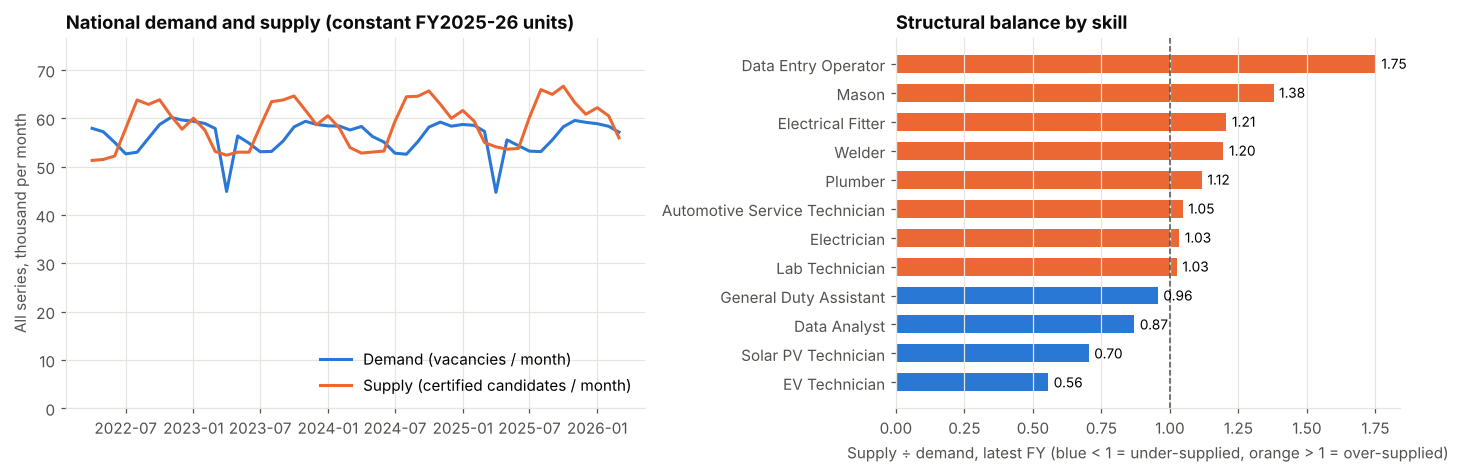

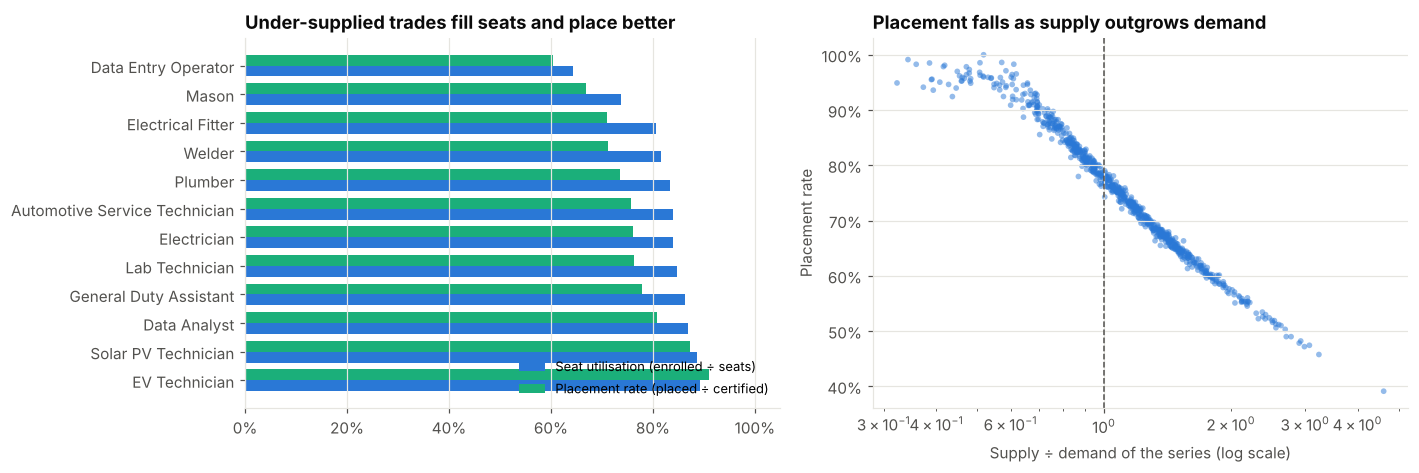

In [37]:
Dw_ca = wide(panel_fin, "Y"); Sw = wide(sup, "CERTIFIED")
nat_d, nat_s = Dw_ca.sum(axis=1), Sw.sum(axis=1)

lat = sup[sup["FY_IDX"] == LAST_FY]
by_skill = lat.groupby("SKILL").agg(supply=("CERTIFIED", "sum"))
by_skill["demand"] = Dw_ca.loc[Dw_ca.index // 12 == LAST_FY].sum().groupby(META["SKILL"]).sum()
by_skill["ratio"] = by_skill["supply"] / by_skill["demand"]
by_skill = by_skill.sort_values("ratio")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
ax.plot(DATES, nat_d / 1000, color=C[0], lw=2, label="Demand (vacancies / month)")
ax.plot(DATES, nat_s / 1000, color=C[1], lw=2, label="Supply (certified candidates / month)")
ax.set_ylim(0, max(nat_d.max(), nat_s.max()) / 1000 * 1.15); ax.set_ylabel("All series, thousand per month")
ax.set_title("National demand and supply (constant FY2025-26 units)", loc="left"); ax.legend(loc="lower right")
ax = axes[1]
cols = [C[0] if r < 1 else C[1] for r in by_skill["ratio"]]
ax.barh(by_skill.index, by_skill["ratio"], color=cols, height=0.62); ax.axvline(1, color=INK2, lw=1, ls="--"); ax.grid(axis="y", visible=False)
for i, v in enumerate(by_skill["ratio"]): ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Supply ÷ demand, latest FY (blue < 1 = under-supplied, orange > 1 = over-supplied)"); ax.set_title("Structural balance by skill", loc="left")
fig.tight_layout(); show(fig, "supply_overview")

ser = lat.groupby("SERIES_ID").agg(enr=("ENROLLED", "sum"), seats=("SEATS_SANCTIONED", "first"), cert=("CERTIFIED", "sum"), plc=("PLACED", "sum"))
ser["util"], ser["place_rate"] = ser["enr"] / ser["seats"], ser["plc"] / ser["cert"].clip(lower=1)
ser["ratio"] = ser["cert"] / Dw_ca.loc[Dw_ca.index // 12 == LAST_FY].sum().reindex(ser.index).clip(lower=1)
ser["SKILL"] = META["SKILL"].reindex(ser.index)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
sk = ser.groupby("SKILL").agg(enr=("enr", "sum"), seats=("seats", "sum"), cert=("cert", "sum"), plc=("plc", "sum"))
sk["Seat utilisation"], sk["Placement rate"] = sk["enr"] / sk["seats"], sk["plc"] / sk["cert"]
sk = sk.loc[by_skill.index]; y = np.arange(len(sk)); hh = 0.38
axes[0].barh(y - hh / 2, sk["Seat utilisation"] * 100, height=hh, color=C[0], label="Seat utilisation (enrolled ÷ seats)")
axes[0].barh(y + hh / 2, sk["Placement rate"] * 100, height=hh, color=C[2], label="Placement rate (placed ÷ certified)")
axes[0].set_yticks(y); axes[0].set_yticklabels(sk.index); axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[0].grid(axis="y", visible=False)
axes[0].set_xlim(0, 105); axes[0].legend(loc="lower right", fontsize=8.5); axes[0].set_title("Under-supplied trades fill seats and place better", loc="left")
sc = ser[ser["cert"] > 30]
axes[1].scatter(sc["ratio"], sc["place_rate"] * 100, s=14, alpha=0.5, color=C[0], edgecolor="none")
axes[1].set_xscale("log"); axes[1].axvline(1, color=INK2, lw=1, ls="--")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[1].set_xlabel("Supply ÷ demand of the series (log scale)"); axes[1].set_ylabel("Placement rate")
axes[1].set_title("Placement falls as supply outgrows demand", loc="left")
fig.tight_layout(); show(fig, "supply_signals")

**Insight 6 — supply is a pipeline.** Certification follows enrolment after the course duration, so **enrolment is a leading indicator of supply**: the 3- and 6-month supply forecasts can lean on it, only the 12-month forecast must anticipate new intake.

**Insight 7 — placement is the market's own tightness signal.** Where certified candidates outnumber vacancies, placement rates fall and seats stay empty; where trades are under-supplied the opposite holds. These signals feed the supply features and, later, the risk classifier and the recommendation text.

*(On the simulated panel these relationships are built in by assumption; on real registry data the same charts would test them.)*

## 20. Supply features

For every district × skill × origin month, **only information available at the origin** is used. The supply side is a pipeline, so besides the lags of certification we use the *enrolment pipeline* (people already in training), seat utilisation, placement and market-tightness signals.

| Group | Features |
|---|---|
| Lags & rolling averages of certified candidates | this month, 1, 2, 3, 6, 12 months ago (relative to the 3M level), 3M vs 6M / 12M averages |
| **Pipeline (leading)** | enrolled 0…6 months ago (relative to the certified level), 6-month enrolment vs certified level |
| Capacity & utilisation | seats sanctioned (log), seat utilisation, training centres, seats per centre |
| Placement & tightness | placement rate (placed ÷ certified), **demand ÷ supply ratio** (the market signal), employer-side demand growth |
| Growth & volatility | 1M / 3M / YoY growth of certification, 6M volatility |
| Calendar | origin / target month (cyclical), position in the financial year |
| Identifiers | state, district, skill, sector |

In [38]:
SUP_WIDE = {c: sup.pivot(index="t_idx", columns="SERIES_ID", values=c).reindex(columns=SIDS).sort_index() for c in FLOW + STATIC}
DEM_WIDE = wide(panel_fin, "Y")                       # demand (constant latest-FY units), available at every origin

def build_supply_features(h):
    """One row per (origin month, series). Every feature uses data up to and including the origin only."""
    Cw, Ew, Pw, Sd, Ct = (SUP_WIDE[c] for c in ["CERTIFIED", "ENROLLED", "PLACED", "SEATS_SANCTIONED", "TRAINING_CENTRES"])
    tn, S = Cw.index.to_numpy(), len(SIDS)
    LC, LE = L(Cw), L(Ew)
    a3, a6, a12 = (Cw.rolling(k).mean() for k in (3, 6, 12))
    base = L(a3)
    f = {"base_log": base}
    for k in (0, 1, 2, 3, 6, 12):
        f[f"rel_lag{k}"] = LC.shift(k) - base
    f["rel_same_month_ly"] = LC.shift(12 - h) - base
    f["avg3_vs_avg6"], f["avg3_vs_avg12"] = base - L(a6), base - L(a12)
    for k in range(0, 7):                                                   # enrolment pipeline: who is in training right now
        f[f"enr_lag{k}"] = LE.shift(k) - base
    f["enr6_vs_cert"] = L(Ew.rolling(6).mean()) - L(a6)
    f["seats_log"] = np.log(Sd.clip(lower=1))
    f["seat_util"] = (Ew.rolling(12).sum() / Sd.clip(lower=1)).clip(upper=2)
    f["centres"] = Ct.astype(float)
    f["seats_per_centre"] = Sd / Ct.clip(lower=1)
    p3, plc_prev = Pw.rolling(3).mean(), Cw.shift(1).rolling(3).mean()
    f["placement_rate"] = (p3 / plc_prev.clip(lower=1)).clip(upper=1.5)
    D3 = DEM_WIDE.rolling(3).mean()
    f["demand_supply_ratio"] = np.log((D3 + 1) / (a3 + 1))                  # >0 : market tighter than the pipeline
    f["demand_growth_3m"]    = L(D3) - L(D3.shift(3))
    f["growth_1m"], f["growth_3m"], f["growth_yoy"] = LC - LC.shift(1), base - L(a3.shift(3)), base - L(a3.shift(12))
    f["volatility_6m"] = LC.diff().rolling(6).std()
    out = {k: v.to_numpy().ravel() for k, v in f.items()}
    fp, mo = tn % 12, ((tn + START.month - 1) % 12) + 1
    tm = ((mo - 1 + h) % 12) + 1
    for k, v in {"month_sin": np.sin(2 * np.pi * mo / 12), "month_cos": np.cos(2 * np.pi * mo / 12),
                 "target_month_sin": np.sin(2 * np.pi * tm / 12), "target_month_cos": np.cos(2 * np.pi * tm / 12),
                 "fy_pos": fp.astype(float), "target_crosses_fy": ((fp + h) >= 12).astype(float)}.items():
        out[k] = np.repeat(v, S)
    X = pd.DataFrame(out)
    for c in CAT_COLS:
        X[c] = pd.Categorical(np.tile(META[c].to_numpy(), len(tn)), categories=CAT_LEVELS[c])
    X["ORIGIN"], X["SID"] = np.repeat(tn, S), np.tile(SIDS, len(tn))
    X["y_act"] = Cw.shift(-h).to_numpy().ravel()
    X["y_rel"] = (LC.shift(-h) - base).to_numpy().ravel()
    X["cur"], X["avg3"] = Cw.to_numpy().ravel(), a3.to_numpy().ravel()
    X["seasonal_naive"] = Cw.shift(12 - h).to_numpy().ravel()
    X["dem_avg3"] = D3.to_numpy().ravel()
    return X

SUP_FEATURES = ([c for c in build_supply_features(3).columns if c not in CAT_COLS + ["ORIGIN", "SID", "y_act", "y_rel", "cur", "avg3", "seasonal_naive", "dem_avg3"]])
SFE_BT = {}
for h in HORIZONS:
    X = build_supply_features(h)
    X["valid"] = X[SUP_FEATURES].notna().all(axis=1)
    r = X.groupby("ORIGIN")["base_log"].rank(pct=True, method="first")
    X["TIER"] = np.clip(np.ceil(r * 4) - 1, 0, 3).fillna(0).astype(int)
    SFE_BT[h] = X

# ---- leakage test: changing everything AFTER the origin must not change any feature of that origin
T0, h0 = CUT - 6, 6
saved = {c: SUP_WIDE[c].copy() for c in FLOW}; saved_d = DEM_WIDE.copy()
ref = build_supply_features(h0); ref = ref[ref["ORIGIN"] == T0][SUP_FEATURES].reset_index(drop=True)
for c in FLOW: SUP_WIDE[c].loc[T0 + 1:] *= 3
DEM_WIDE.loc[T0 + 1:] *= 3
chk = build_supply_features(h0); chk = chk[chk["ORIGIN"] == T0][SUP_FEATURES].reset_index(drop=True)
for c in FLOW: SUP_WIDE[c] = saved[c]
DEM_WIDE = saved_d
assert np.allclose(ref.to_numpy(float), chk.to_numpy(float), equal_nan=True), "LEAKAGE: a supply feature uses post-origin data"
print(f"✔ Leakage test passed — {len(SUP_FEATURES)} numeric + {len(CAT_COLS)} categorical supply features, none sees data after its origin month.")

✔ Leakage test passed — 35 numeric + 4 categorical supply features, none sees data after its origin month.


## 21. Supply models

Same recipe that worked for demand: a **direct multi-horizon** model per horizon (3M / 6M / 12M) predicting the **log-ratio to the 3-month average**, so the model learns *change* rather than level. Candidates: Linear Regression (baseline), LightGBM, XGBoost and their ensemble; the benchmark set also contains seasonal-naive, 3M-average naive, ARIMA. Hyper-parameters are tuned on a block *inside* the training window; the final choice uses rolling-origin validation over the last full financial year.

In [39]:
def s_split(X, h):
    lab = X["valid"] & X["y_rel"].notna(); tgt = X["ORIGIN"] + h
    return {"train_in": X[lab & (tgt <= CUT - VAL_MONTHS)], "val": X[lab & (tgt > CUT - VAL_MONTHS) & (tgt <= CUT)],
            "train": X[lab & (tgt <= CUT)], "test": X[lab & (tgt > CUT)], "test_fixed": X[lab & (X["ORIGIN"] == CUT)]}
SSPL = {h: s_split(SFE_BT[h], h) for h in HORIZONS}
for h in HORIZONS:
    s = SSPL[h]
    assert (s["train"]["ORIGIN"] + h).max() <= CUT and (s["test"]["ORIGIN"] + h).min() > CUT

def s_design(X, kind):
    if kind == "tree":
        return X[SUP_FEATURES + CAT_COLS]
    lin = X[SUP_FEATURES].copy()
    for c in ("STATE", "SECTOR", "SKILL"):
        lin = lin.join(pd.get_dummies(X[c], prefix=c, dtype=float))
    return lin

S_TUNE_ITER = N_TUNE_ITER
def s_tune(make, default, space, Xtr, ytr, Xva, yva):
    cands = [default] + list(ParameterSampler(space, S_TUNE_ITER, random_state=SEED))
    scored = sorted(((mean_absolute_error(yva, make(**p).fit(Xtr, ytr).predict(Xva)), p) for p in cands), key=lambda t: t[0])
    return scored[0][1], scored[0][0]

S_TUNED, t0 = {}, time.time()
for h in HORIZONS:
    s = SSPL[h]; Xtr, Xva = s_design(s["train_in"], "tree"), s_design(s["val"], "tree")
    ytr, yva = s["train_in"]["y_rel"].to_numpy(), s["val"]["y_rel"].to_numpy()
    pl, bl = s_tune(make_lgb, LGB_DEFAULT, LGB_SPACE, Xtr, ytr, Xva, yva)
    px, bx = s_tune(make_xgb, XGB_DEFAULT, XGB_SPACE, Xtr, ytr, Xva, yva)
    S_TUNED[h] = {"lgb": pl, "xgb": px}
    print(f"h={h:>2}M  tuned · validation log-MAE  LightGBM {bl:.4f} · XGBoost {bx:.4f}")
print(f"Tuning time: {time.time() - t0:.0f}s")

# ---- rolling-origin validation and model selection (identical protocol to Part 1)
sfold = []
for h in HORIZONS:
    X = SFE_BT[h]; lab = X["valid"] & X["y_rel"].notna(); tgt = X["ORIGIN"] + h
    for k, (lo_t, hi_t) in enumerate(BLOCKS, start=1):
        tr, va = X[lab & (tgt < lo_t)], X[lab & (tgt >= lo_t) & (tgt <= hi_t)]
        if len(tr) < MIN_TRAIN or len(va) == 0:
            continue
        assert (tr["ORIGIN"] + h).max() < lo_t
        ytr = tr["y_rel"].to_numpy()
        rel = {"LR":   make_lr().fit(s_design(tr, "lin"), ytr).predict(s_design(va, "lin")),
               "LGBM": make_lgb(**S_TUNED[h]["lgb"]).fit(s_design(tr, "tree"), ytr).predict(s_design(va, "tree")),
               "XGB":  make_xgb(**S_TUNED[h]["xgb"]).fit(s_design(tr, "tree"), ytr).predict(s_design(va, "tree"))}
        rel["ENS"] = (rel["LGBM"] + rel["XGB"]) / 2
        cand = {m: metrics(va["y_act"], pred_count(va, r)) for m, r in rel.items()}
        cand["NAIVE3"], cand["SNAIVE"] = metrics(va["y_act"], va["avg3"]), metrics(va["y_act"], va["seasonal_naive"])
        for m, mm in cand.items():
            sfold.append({"Horizon": h, "Fold": k, "Model": m, **mm})
SFOLD = pd.DataFrame(sfold)
SVAL = SFOLD.groupby(["Horizon", "Model"])[["MAE", "RMSE", "MAPE", "WAPE"]].mean().reset_index()
SVAL["mean_rank"] = np.nan
for h in HORIZONS:
    m = (SVAL["Horizon"] == h) & SVAL["Model"].isin(ML_CANDIDATES)
    SVAL.loc[m, "mean_rank"] = SVAL.loc[m, ["MAE", "RMSE", "MAPE"]].rank().mean(axis=1)
S_SELECTED = {h: SVAL[(SVAL.Horizon == h) & SVAL.Model.isin(ML_CANDIDATES)].sort_values(["mean_rank", "MAPE"]).iloc[0]["Model"] for h in HORIZONS}
display(SVAL.assign(Model=SVAL.Model.map(MODEL_NAMES)).set_index(["Horizon", "Model"]).style.format("{:.2f}", na_rep="–"))
display(Markdown("**Selected on rolling validation (supply):** " + " · ".join(f"**{h}M → {MODEL_NAMES[S_SELECTED[h]]}**" for h in HORIZONS)))

h= 3M  tuned · validation log-MAE  LightGBM 0.0498 · XGBoost 0.0529


h= 6M  tuned · validation log-MAE  LightGBM 0.0665 · XGBoost 0.0671


h=12M  tuned · validation log-MAE  LightGBM 0.0816 · XGBoost 0.0823
Tuning time: 21s


**Selected on rolling validation (supply):** **3M → Ensemble (LGBM+XGB)** · **6M → LightGBM** · **12M → Ensemble (LGBM+XGB)**

## 22. Supply model evaluation — hold-out financial year

The models are refit on everything up to the hold-out year and scored on the **last 12 months they have never seen**: fixed-origin (one forecast date, the pure “forecast ahead” test) and rolling-origin (all origins in the year). Metrics: **MAE, RMSE, MAPE** and WAPE, always against the naive benchmarks. ARIMA are fitted per series on the same sample as in Part 1.

In [40]:
SBT_MODELS, STEST_REL = {}, {}
for h in HORIZONS:
    s = SSPL[h]; ytr = s["train"]["y_rel"].to_numpy()
    lr  = make_lr().fit(s_design(s["train"], "lin"), ytr)
    mlg = make_lgb(**S_TUNED[h]["lgb"]).fit(s_design(s["train"], "tree"), ytr)
    mxg = make_xgb(**S_TUNED[h]["xgb"]).fit(s_design(s["train"], "tree"), ytr)
    rel = {"LR": lr.predict(s_design(s["test"], "lin")), "LGBM": mlg.predict(s_design(s["test"], "tree")), "XGB": mxg.predict(s_design(s["test"], "tree"))}
    rel["ENS"] = (rel["LGBM"] + rel["XGB"]) / 2
    SBT_MODELS[h], STEST_REL[h] = {"LR": lr, "LGBM": mlg, "XGB": mxg}, rel
STEST_CNT = {}
for h in HORIZONS:
    Xt = SSPL[h]["test"]
    c = {m: pred_count(Xt, STEST_REL[h][m]) for m in ML_CANDIDATES}
    c["NAIVE3"], c["SNAIVE"] = Xt["avg3"].to_numpy(), Xt["seasonal_naive"].to_numpy()
    STEST_CNT[h] = c

# ARIMA on the same sample of series used in Part 1
shist = [L(SUP_WIDE["CERTIFIED"].loc[:CUT, sid].to_numpy()) for sid in ts_sids]
t0, SSTAT = time.time(), {}
for name, fn in [("ARIMA", _arima_fc)]:
    out = [fn(y, DATES[:CUT + 1], 12) for y in shist]
    SSTAT[name] = pd.DataFrame(np.clip(np.expm1(np.vstack(out)), 0, None), index=ts_sids, columns=range(1, 13))
print(f"ARIMA fitted on {len(ts_sids)} supply series in {time.time() - t0:.0f}s")

fx_rows, rl_rows = [], []
for h in HORIZONS:
    Xt = SSPL[h]["test"]; is_fix = (Xt["ORIGIN"] == CUT).to_numpy()
    for m, p in STEST_CNT[h].items():
        rl_rows.append({"Model": m, "Horizon": h, "n": len(Xt), **metrics(Xt["y_act"], p)})
        fx_rows.append({"Model": m, "Horizon": h, "n": int(is_fix.sum()), **metrics(Xt["y_act"].to_numpy()[is_fix], p[is_fix])})
    fx = Xt[is_fix]
    for m in ("ARIMA",):
        pr = SSTAT[m].reindex(fx["SID"]).dropna(); sub = fx.set_index("SID").loc[pr.index]
        fx_rows.append({"Model": m, "Horizon": h, "n": len(sub), **metrics(sub["y_act"], pr[h].to_numpy())})
SEVAL_FIXED, SEVAL_ROLL = pd.DataFrame(fx_rows), pd.DataFrame(rl_rows)

def s_table(E, metric):
    t = E.pivot(index="Model", columns="Horizon", values=metric).reindex(["NAIVE3", "SNAIVE", "ARIMA", "LR", "LGBM", "XGB", "ENS"])
    t.index = [MODEL_NAMES[i] for i in t.index]; t.columns = [f"{h}M" for h in t.columns]
    return t
for title, E in [("Fixed-origin hold-out (one forecast date = Mar of the previous year → next 3 / 6 / 12 months)", SEVAL_FIXED), ("Rolling-origin hold-out (every origin of the hold-out year)", SEVAL_ROLL)]:
    display(Markdown(f"**{title}**"))
    for mt in ("MAE", "RMSE", "MAPE"):
        display(Markdown(f"*{mt}*  ({'candidates per month' if mt != 'MAPE' else '%'})"))
        display(s_table(E, mt).style.format("{:.2f}", na_rep="–").highlight_min(axis=0, color="#cfe8d5"))
best = {h: SEVAL_FIXED[(SEVAL_FIXED.Horizon == h) & SEVAL_FIXED.Model.isin(ML_CANDIDATES)].set_index("Model")["WAPE"] for h in HORIZONS}
snv = {h: float(SEVAL_FIXED[(SEVAL_FIXED.Horizon == h) & (SEVAL_FIXED.Model == "SNAIVE")]["WAPE"].iloc[0]) for h in HORIZONS}
display(Markdown("**Selected model vs. the seasonal-naive benchmark (fixed-origin WAPE):** " +
                 " · ".join(f"{h}M: **{best[h][S_SELECTED[h]]:.1f} %** vs {snv[h]:.1f} %" for h in HORIZONS)))

ARIMA fitted on 100 supply series in 13s


**Fixed-origin hold-out (one forecast date = Mar of the previous year → next 3 / 6 / 12 months)**

*MAE*  (candidates per month)

,3M,6M,12M
3M-average naive,8.07,12.78,8.74
Seasonal naive,7.30,9.39,8.31
ARIMA,5.71,9.95,7.20
Linear Regression,4.64,8.98,6.02
LightGBM,3.70,7.25,6.04
XGBoost,3.74,7.20,6.04
Ensemble (LGBM+XGB),3.66,7.19,6.02


*RMSE*  (candidates per month)

...

*RMSE*  (candidates per month)

,3M,6M,12M
3M-average naive,23.05,22.87,16.65
Seasonal naive,16.54,16.54,16.54
ARIMA,–,–,–
Linear Regression,11.61,13.97,13.84
LightGBM,8.27,12.63,13.62
XGBoost,8.98,12.65,13.77
Ensemble (LGBM+XGB),8.51,12.59,13.64


*MAPE*  (%)

,3M,6M,12M
3M-average naive,16.58,18.05,11.89
Seasonal naive,11.56,11.56,11.56
ARIMA,–,–,–
Linear Regression,7.73,8.42,8.62
LightGBM,5.28,7.30,8.49
XGBoost,5.77,7.39,8.60
Ensemble (LGBM+XGB),5.43,7.30,8.50


**Selected model vs. the seasonal-naive benchmark (fixed-origin WAPE):** 3M: **5.2 %** vs 10.3 % · 6M: **8.4 %** vs 10.9 % · 12M: **8.1 %** vs 11.2 %

### Prediction intervals for supply
Exactly as for demand: an 80 % band from the hold-out residuals, by volume tier × volatility × April-target bucket, with an empirical-coverage check on held-out series. Confidence = 1 / (1 + band half-width).

In [41]:
SVOLA_CUTS = SSPL[3]["train"]["volatility_6m"].quantile([1 / 3, 2 / 3]).to_numpy()
def s_add_buckets(frame, h):
    out = frame.copy()
    out["vol_bucket"]  = pd.Series(out["TIER"].map(dict(enumerate(VOL_ORDER))), index=out.index).astype(str)
    out["stab_bucket"] = pd.cut(out["volatility_6m"], [-np.inf, SVOLA_CUTS[0], SVOLA_CUTS[1], np.inf], labels=STAB_ORDER).astype(str)
    out["tgt_apr"]     = ((out["ORIGIN"] + h) % 12 == 0)
    return out
parts = []
for h in HORIZONS:
    d = s_add_buckets(SSPL[h]["test"][["SID", "ORIGIN", "TIER", "volatility_6m", "y_act"]], h)
    d["pred"], d["h"] = STEST_CNT[h][S_SELECTED[h]], h
    parts.append(d)
sres = pd.concat(parts, ignore_index=True)
sres["abs_res"] = np.abs(sres["y_act"] - sres["pred"]) / np.maximum(sres["pred"], 1)
SQFIT = {h: fit_q(sres[sres["h"] == h]) for h in HORIZONS}
cov = []
for h in HORIZONS:
    r = sres[sres["h"] == h].reset_index(drop=True); covered = np.zeros(len(r), bool)
    for a, b in GroupKFold(n_splits=5).split(r, groups=r["SID"]):
        covered[b] = r["abs_res"].to_numpy()[b] <= apply_q(r.iloc[b], fit_q(r.iloc[a]))
    cov.append({"Horizon": f"{h}M", "Target coverage": "80%", "Empirical coverage on held-out series": f"{covered.mean():.1%}"})
display(pd.DataFrame(cov).set_index("Horizon"))

,Target coverage,Empirical coverage on held-out series
Horizon,,
3M,80%,79.7%
6M,80%,79.6%
12M,80%,79.9%


## 23. Final supply forecast — 3, 6 and 12 months ahead

The selected model per horizon is refit on **all** history and applied at the forecast origin (last data month). The output is the expected number of newly certified candidates per month, with an 80 % interval and a confidence score. `training_capacity` is the *structural* ceiling of the pipeline: annual sanctioned seats × completion rate ÷ 12.

In [42]:
SFE_FN, SFINAL = {}, {}
for h in HORIZONS:
    X = build_supply_features(h); X["valid"] = X[SUP_FEATURES].notna().all(axis=1)
    tr = X[X["valid"] & X["y_rel"].notna()]
    pr = X[X["valid"] & (X["ORIGIN"] == T_LAST)].copy()
    assert (tr["ORIGIN"] + h).max() <= T_LAST and len(pr) == len(SIDS)
    r = pr["base_log"].rank(pct=True, method="first"); pr["TIER"] = np.clip(np.ceil(r * 4) - 1, 0, 3).astype(int)
    pr = pr.set_index("SID").reindex(SIDS); pr["SID"] = pr.index
    SFE_FN[h], SFINAL[h] = tr, pr.reset_index(drop=True)

def s_fit_predict_final(h, kind, return_models=False):
    tr, pr = SFE_FN[h], SFINAL[h]; ytr = tr["y_rel"].to_numpy(); models = {}
    if kind == "LR":
        models["LR"] = make_lr().fit(s_design(tr, "lin"), ytr); p = models["LR"].predict(s_design(pr, "lin"))
    else:
        if kind in ("LGBM", "ENS"): models["LGBM"] = make_lgb(**S_TUNED[h]["lgb"]).fit(s_design(tr, "tree"), ytr)
        if kind in ("XGB", "ENS"):  models["XGB"]  = make_xgb(**S_TUNED[h]["xgb"]).fit(s_design(tr, "tree"), ytr)
        p = np.mean([m.predict(s_design(pr, "tree")) for m in models.values()], axis=0)
    return (p, models) if return_models else p

t0 = time.time(); SREL_FN, SMODELS = {}, {}
for h in HORIZONS:
    SREL_FN[h], SMODELS[h] = s_fit_predict_final(h, S_SELECTED[h], True)
print(f"Final supply models trained on all history in {time.time() - t0:.0f}s · " + " · ".join(f"{h}M: {MODEL_NAMES[S_SELECTED[h]]}" for h in HORIZONS))

sfc = {}
for h in HORIZONS:
    pr = s_add_buckets(SFINAL[h], h)
    nom = pred_count(pr, SREL_FN[h]); q80 = apply_q(pr, SQFIT[h])
    sfc[h] = pd.DataFrame({"nom": nom, "lo": np.maximum(nom - q80 * np.maximum(nom, 1), 0), "hi": nom + q80 * np.maximum(nom, 1), "conf": 1 / (1 + q80)}, index=SIDS)
    assert np.isfinite(sfc[h].to_numpy()).all()

lat_fy = sup[sup["FY_IDX"] == LAST_FY].groupby("SERIES_ID").agg(seats=("SEATS_SANCTIONED", "last"), enr=("ENROLLED", "sum"), cert=("CERTIFIED", "sum"), plc=("PLACED", "sum"), centres=("TRAINING_CENTRES", "last"))
SUP_OUT = pd.DataFrame(index=SIDS)
SUP_OUT["current_supply"]  = SUP_WIDE["CERTIFIED"].loc[T_LAST].astype(int)
SUP_OUT["current_supply_3m_avg"] = SUP_WIDE["CERTIFIED"].loc[T_LAST - 2:T_LAST].mean().round(1)
for h in HORIZONS:
    SUP_OUT[f"supply_{h}m"] = np.rint(sfc[h]["nom"]).astype(int)
    SUP_OUT[f"supply_{h}m_low"], SUP_OUT[f"supply_{h}m_high"] = np.rint(sfc[h]["lo"]).astype(int), np.rint(sfc[h]["hi"]).astype(int)
    SUP_OUT[f"supply_confidence_{h}m"] = sfc[h]["conf"].round(2)
SUP_OUT["supply_confidence"] = np.mean([sfc[h]["conf"] for h in HORIZONS], axis=0).round(2)
comp = sup.groupby("SERIES_ID").apply(lambda g: g[g["FY_IDX"] == LAST_FY]["CERTIFIED"].sum() / max(g[g["FY_IDX"] == LAST_FY]["ENROLLED"].sum(), 1))
SUP_OUT["completion_rate"]  = comp.reindex(SIDS).clip(0, 1).round(3)
SUP_OUT["training_capacity"] = np.rint(lat_fy["seats"].reindex(SIDS) * SUP_OUT["completion_rate"] / 12).astype(int)
SUP_OUT["seat_utilisation"] = (lat_fy["enr"] / lat_fy["seats"].clip(lower=1)).reindex(SIDS).round(3)
SUP_OUT["placement_rate"]   = (lat_fy["plc"] / lat_fy["cert"].clip(lower=1)).reindex(SIDS).clip(0, 1).round(3)
SUP_OUT["training_centres"] = lat_fy["centres"].reindex(SIDS).astype(int)
SUP_OUT["supply_model_used"] = " | ".join(f"{h}M: {MODEL_NAMES[S_SELECTED[h]]}" for h in HORIZONS)
display(Markdown("**Supply forecast preview — Electrician:**"))
display(SUP_OUT[META["SKILL"].reindex(SUP_OUT.index) == "Electrician"][["current_supply", "supply_3m", "supply_6m", "supply_12m", "supply_confidence", "training_capacity"]].head(6))
display(Markdown(f"National totals — certified per month: now **{SUP_OUT['current_supply'].sum():,}** → 3M **{SUP_OUT['supply_3m'].sum():,}** · 6M **{SUP_OUT['supply_6m'].sum():,}** · 12M **{SUP_OUT['supply_12m'].sum():,}**"))

Final supply models trained on all history in 6s · 3M: Ensemble (LGBM+XGB) · 6M: LightGBM · 12M: Ensemble (LGBM+XGB)


**Supply forecast preview — Electrician:**

,current_supply,supply_3m,supply_6m,supply_12m,supply_confidence,training_capacity
Bihar | Banka | Electrician,82,74,95,83,0.90,109
Bihar | Muzaffarpur | Electrician,96,80,108,88,0.91,105
Bihar | Patna | Electrician,94,89,112,98,0.91,117
Bihar | Purbi Champaran | Electrician,102,89,123,101,0.90,131
Bihar | Saran | Electrician,70,67,85,71,0.91,74
Delhi | East | Electrician,75,68,90,78,0.90,89


National totals — certified per month: now **55,946** → 3M **54,920** · 6M **65,535** · 12M **57,406**

## 24. Skill gap — demand meets supply

`Gap = Forecast Demand − Forecast Supply` per district × skill and per horizon, in **people per month**. Positive = **shortage**, negative = **oversupply**.
The *planning horizon* for the headline `skill_gap`, `risk` and `recommendation` is **12 months**: a training seat opened today produces certified candidates only after the course duration, so the 12-month view is the one planners can still act on. The 3M and 6M gaps are reported next to it as the early-warning path.

The normalised **gap index** `(D − S) / max(D, S, 1)` runs from −1 (pure oversupply) to +1 (pure shortage) and makes small and large districts comparable.

✔ Worked example of the brief reproduced: 8,200 − 6,300 = 1,900 shortage → gap index 0.23 → Critical Shortage.


**National skill balance, 12 months ahead (people per month)**

,demand_12m,supply_12m,gap_12m,gap_index
skill,,,,
Solar PV Technician,"6,041","3,809","+2,232",+0.37
EV Technician,"3,866","1,851","+2,015",+0.52
General Duty Assistant,"7,929","6,476","+1,453",+0.18
Data Analyst,"5,927","4,721","+1,206",+0.20
Automotive Service Technician,"5,674","5,326",+348,+0.06
Plumber,"3,376","3,074",+302,+0.09
Welder,"4,394","4,100",+294,+0.07
Lab Technician,"3,288","3,020",+268,+0.08
Electrician,"8,155","7,987",+168,+0.02


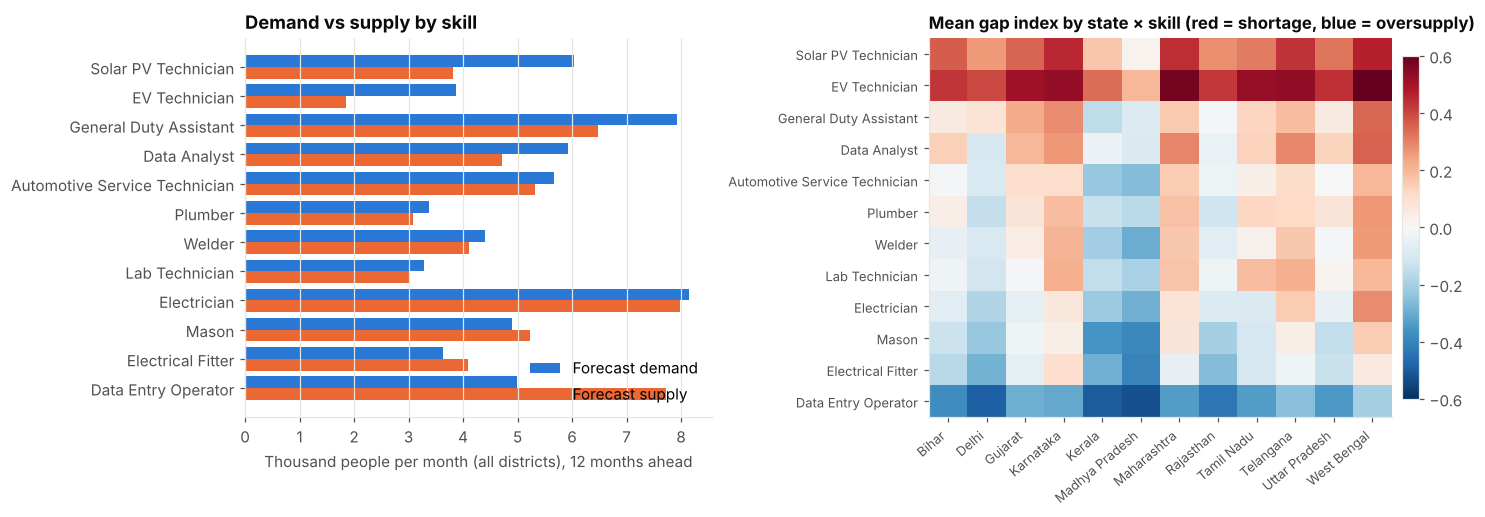

**Risk class counts (12-month planning horizon)**

direction,Balanced,Oversupply,Shortage,Total
risk,,,,
Low,186,0,0,186
Medium,0,127,67,194
High,0,54,64,118
Critical,0,32,226,258


In [43]:
POLICY = {                                   # editable policy assumptions (the dashboard lets planners change them)
    "shortage_bands":   (0.08, 0.15, 0.22),  # gap index at which a shortage becomes Medium / High / Critical
    "oversupply_bands": (0.15, 0.30, 0.45),  # oversupply is tolerated more (graduates can be re-skilled): wider bands
    "low_volume": 10,                        # below this monthly volume a series can never be rated above Medium (statistical noise)
    "close_fraction":  {"Low": 0.0, "Medium": 0.50, "High": 0.75, "Critical": 1.00},   # share of the 12M shortage that new capacity should close
    "reduce_fraction": {"Low": 0.0, "Medium": 0.25, "High": 0.50, "Critical": 0.75},   # share of the 12M surplus that should be removed
    "target_utilisation": 0.90,              # seats expected to be filled in new batches
    "max_expansion": 0.50,                   # a centre can add at most +50 % seats per year
    "max_reduction": 0.40,                   # and shed at most 40 %
    "fill_first_util": 0.75,                 # below this seat utilisation: fill existing seats before sanctioning new ones
}
RISK_ORDER = ["Low", "Medium", "High", "Critical"]

def gap_index(D, S):
    D, S = np.asarray(D, float), np.asarray(S, float)
    return (D - S) / np.maximum(np.maximum(D, S), 1.0)

def classify_risk(D, S, policy=POLICY):
    """Low / Medium / High / Critical from demand and supply (people per month). Returns (risk, direction, gap index)."""
    gi = gap_index(D, S)
    sh, ov = policy["shortage_bands"], policy["oversupply_bands"]
    lvl_s = np.select([gi >= sh[2], gi >= sh[1], gi >= sh[0]], [3, 2, 1], 0)
    lvl_o = np.select([-gi >= ov[2], -gi >= ov[1], -gi >= ov[0]], [3, 2, 1], 0)
    lvl = np.where(gi > 0, lvl_s, lvl_o)
    lvl = np.where(np.maximum(D, S) < policy["low_volume"], np.minimum(lvl, 1), lvl)
    direction = np.where(lvl == 0, "Balanced", np.where(gi > 0, "Shortage", "Oversupply"))
    return np.array(RISK_ORDER)[lvl], direction, gi

G = DEMAND_IN[HANDOVER_FIELDS + ["state", "sector", "low_volume_flag", "demand_trend", "forecast_3m_low", "forecast_3m_high", "forecast_6m_low", "forecast_6m_high",
                                  "forecast_12m_low", "forecast_12m_high"]].copy()
G.index = DEMAND_IN["state"] + " | " + DEMAND_IN["district"] + " | " + DEMAND_IN["skill"]
G = G.reindex(SIDS)
assert G.index.equals(SUP_OUT.index) and not G["district"].isna().any()
for h in HORIZONS:
    G[f"supply_{h}m"] = SUP_OUT[f"supply_{h}m"]
    G[f"gap_{h}m"]    = G[f"forecast_{h}m"] - G[f"supply_{h}m"]
    G[f"gap_index_{h}m"] = gap_index(G[f"forecast_{h}m"], G[f"supply_{h}m"]).round(3)
    G[f"risk_{h}m"], G[f"direction_{h}m"], _ = classify_risk(G[f"forecast_{h}m"], G[f"supply_{h}m"])
G["skill_gap"] = G["gap_12m"]
G["risk"], G["direction"], _gi = classify_risk(G["forecast_12m"], G["supply_12m"])
G["gap_index"] = np.round(_gi, 3)

# ---- the worked example of the brief must come out as written (Demand 8,200 · Supply 6,300 -> gap 1,900 -> Critical shortage)
ex_risk, ex_dir, ex_gi = classify_risk(np.array([8200]), np.array([6300]))
assert (8200 - 6300) == 1900 and ex_risk[0] == "Critical" and ex_dir[0] == "Shortage", "worked example of the brief not reproduced"
print(f"✔ Worked example of the brief reproduced: 8,200 − 6,300 = 1,900 shortage → gap index {ex_gi[0]:.2f} → {ex_risk[0]} {ex_dir[0]}.")

summ = G.groupby("skill").agg(demand_12m=("forecast_12m", "sum"), supply_12m=("supply_12m", "sum"))
summ["gap_12m"] = summ["demand_12m"] - summ["supply_12m"]
summ["gap_index"] = gap_index(summ["demand_12m"], summ["supply_12m"]).round(3)
summ = summ.sort_values("gap_12m", ascending=False)
display(Markdown("**National skill balance, 12 months ahead (people per month)**"))
display(summ.style.format({"demand_12m": "{:,.0f}", "supply_12m": "{:,.0f}", "gap_12m": "{:+,.0f}", "gap_index": "{:+.2f}"}).background_gradient(subset=["gap_index"], cmap="RdBu_r", vmin=-0.6, vmax=0.6))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1, 1.05]})
ax = axes[0]; y = np.arange(len(summ)); hh = 0.4
ax.barh(y - hh / 2, summ["demand_12m"] / 1000, height=hh, color=C[0], label="Forecast demand")
ax.barh(y + hh / 2, summ["supply_12m"] / 1000, height=hh, color=C[1], label="Forecast supply")
ax.set_yticks(y); ax.set_yticklabels(summ.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("Thousand people per month (all districts), 12 months ahead"); ax.set_title("Demand vs supply by skill", loc="left"); ax.legend(loc="lower right")
ax = axes[1]
piv = G.pivot_table(index="skill", columns="state", values="gap_index", aggfunc="mean").loc[summ.index]
im = ax.imshow(piv.to_numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, rotation=40, ha="right", fontsize=8.5); ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index, fontsize=8.5)
ax.grid(False); ax.set_title("Mean gap index by state × skill (red = shortage, blue = oversupply)", loc="left", fontsize=11)
fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); fig.tight_layout(); show(fig, "gap_overview")

display(Markdown("**Risk class counts (12-month planning horizon)**"))
rc = pd.crosstab(G["risk"], G["direction"]).reindex(RISK_ORDER).fillna(0).astype(int); rc["Total"] = rc.sum(axis=1)
display(rc)

## 25. Risk classification

Two complementary layers, both required by the brief's "Classification: XGBoost Classifier":

1. **Rule-based risk (headline).** Transparent, auditable and consistent with the worked example: the gap index of the *forecast* demand and supply is mapped to **Low / Medium / High / Critical** with policy bands (shortages are graded more strictly than oversupply; a low-volume series can never exceed Medium).
2. **XGBoost early-warning classifier.** Learns from the history of both sides which district × skill pairs *drift into* a high-risk class. Target = the risk class **actually realised 12 months after the origin**. It is trained only on origins whose outcome is already known, tested on the hold-out year, and compared with a *persistence* baseline ("risk stays as it is today").

**Hold-out test of the risk classifier** — 9,072 district × skill × origin cases, target = risk class 12 months later (hold-out year targets only)

,Accuracy,Macro F1,Within one class,Mean abs. class error,n
Persistence (risk stays as today),57.6%,0.563,91.4%,0.523,"9,072"
Majority class,29.3%,0.113,50.6%,1.433,"9,072"
XGBoost classifier,61.0%,0.593,91.2%,0.497,"9,072"


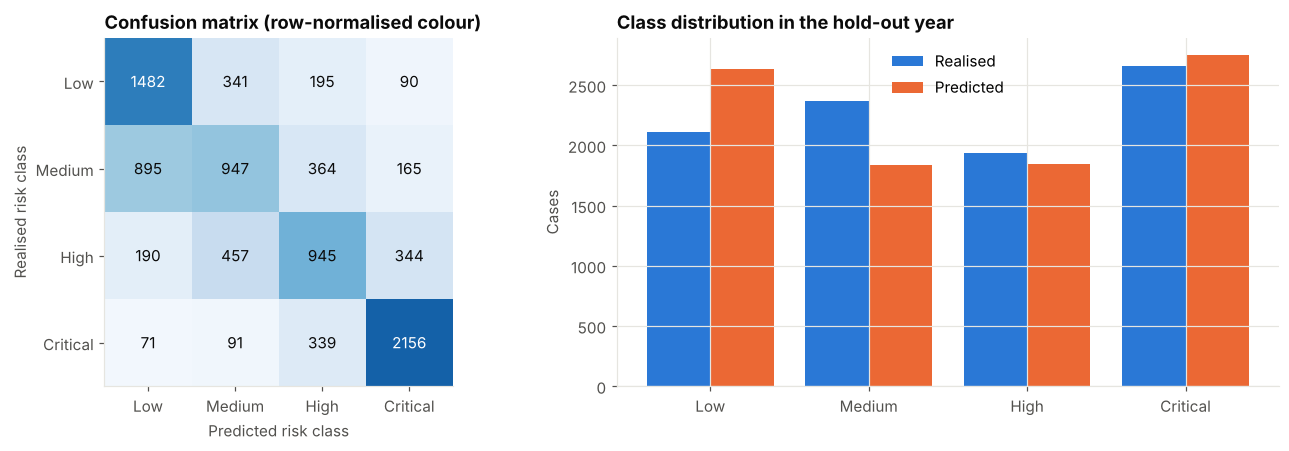

*Reading guide:* the classifier is useful when it beats the persistence line — i.e. when it anticipates **change** of risk, not only today's state. It works on the organic dynamics in constant FY2025-26 units; the headline rule risk uses the nominal hand-over forecasts.  Because supply is simulated here, these scores show that the pipeline works, not how it would score on real registry data.

In [44]:
import sklearn.metrics as skm
from sklearn.utils.class_weight import compute_sample_weight

def build_clf_frame():
    X = SFE_BT[12].copy()
    D3 = DEM_WIDE.rolling(3).mean()
    X["gap_now"] = gap_index(X["dem_avg3"].to_numpy(), X["avg3"].to_numpy())
    X["dem_yoy"] = (L(D3) - L(D3.shift(12))).to_numpy().ravel()
    Dt = D3.shift(-12).to_numpy().ravel()                                    # 3-month average demand around the target month
    St = SUP_WIDE["CERTIFIED"].rolling(3).mean().shift(-12).to_numpy().ravel()
    X["lab_D"], X["lab_S"] = Dt, St
    ok = np.isfinite(Dt) & np.isfinite(St)
    lab = np.full(len(X), -1)
    r, _, _ = classify_risk(np.nan_to_num(Dt), np.nan_to_num(St))
    lab[ok] = pd.Series(r[ok]).map({c: i for i, c in enumerate(RISK_ORDER)}).to_numpy()
    X["risk_cls"] = lab
    X["now_cls"] = pd.Series(classify_risk(np.nan_to_num(X["dem_avg3"].to_numpy()), np.nan_to_num(X["avg3"].to_numpy()))[0]).map({c: i for i, c in enumerate(RISK_ORDER)}).to_numpy()
    X["valid"] = X["valid"] & X[["gap_now", "dem_yoy"]].notna().all(axis=1)
    return X

CLF_FEATURES = SUP_FEATURES + ["gap_now", "dem_yoy"]
CF = build_clf_frame()
def clf_design(X): return X[CLF_FEATURES + CAT_COLS]
CLF_PARAMS = dict(n_estimators=250, learning_rate=0.06, max_depth=4, min_child_weight=10, subsample=0.85, colsample_bytree=0.8, reg_lambda=5)
def make_clf(): return xgb.XGBClassifier(tree_method="hist", enable_categorical=True, objective="multi:softprob", num_class=4, random_state=SEED, n_jobs=2, **CLF_PARAMS)

lab = CF["valid"] & (CF["risk_cls"] >= 0)
tgt = CF["ORIGIN"] + 12
tr_b, te_b = CF[lab & (tgt <= CUT)], CF[lab & (tgt > CUT)]
assert (tr_b["ORIGIN"] + 12).max() <= CUT and (te_b["ORIGIN"] + 12).min() > CUT
assert set(tr_b["risk_cls"]) == {0, 1, 2, 3}, "training data must contain all four risk classes"
clf_bt = make_clf().fit(clf_design(tr_b), tr_b["risk_cls"].to_numpy(), sample_weight=compute_sample_weight("balanced", tr_b["risk_cls"]))
pr_p = clf_bt.predict_proba(clf_design(te_b)); pr_c = pr_p.argmax(axis=1); yt = te_b["risk_cls"].to_numpy()

def clf_scores(y, p):
    return {"Accuracy": skm.accuracy_score(y, p), "Macro F1": skm.f1_score(y, p, average="macro", labels=[0, 1, 2, 3]),
            "Within one class": float((np.abs(y - p) <= 1).mean()), "Mean abs. class error": float(np.abs(y - p).mean())}
major = np.full(len(yt), pd.Series(tr_b["risk_cls"]).mode()[0])
CLF_EVAL = pd.DataFrame({"Persistence (risk stays as today)": clf_scores(yt, te_b["now_cls"].to_numpy()),
                         "Majority class": clf_scores(yt, major), "XGBoost classifier": clf_scores(yt, pr_c)}).T
CLF_EVAL["n"] = len(yt)
display(Markdown(f"**Hold-out test of the risk classifier** — {len(yt):,} district × skill × origin cases, target = risk class 12 months later (hold-out year targets only)"))
display(CLF_EVAL.style.format({"Accuracy": "{:.1%}", "Macro F1": "{:.3f}", "Within one class": "{:.1%}", "Mean abs. class error": "{:.3f}", "n": "{:,.0f}"}))
cm = skm.confusion_matrix(yt, pr_c, labels=[0, 1, 2, 3])
CLF_CM = cm
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]; ax.imshow(cm / np.maximum(cm.sum(axis=1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", color="white" if cm[i, j] / max(cm[i].sum(), 1) > 0.5 else INK)
ax.set_xticks(range(4)); ax.set_xticklabels(RISK_ORDER); ax.set_yticks(range(4)); ax.set_yticklabels(RISK_ORDER); ax.grid(False)
ax.set_xlabel("Predicted risk class"); ax.set_ylabel("Realised risk class"); ax.set_title("Confusion matrix (row-normalised colour)", loc="left")
ax = axes[1]; cnt = pd.Series(yt).value_counts().reindex(range(4)).fillna(0); pcnt = pd.Series(pr_c).value_counts().reindex(range(4)).fillna(0)
ax.bar(np.arange(4) - 0.2, cnt, width=0.4, color=C[0], label="Realised"); ax.bar(np.arange(4) + 0.2, pcnt, width=0.4, color=C[1], label="Predicted")
ax.set_xticks(range(4)); ax.set_xticklabels(RISK_ORDER); ax.set_title("Class distribution in the hold-out year", loc="left"); ax.legend(); ax.set_ylabel("Cases")
fig.tight_layout(); show(fig, "risk_classifier")
display(Markdown("*Reading guide:* the classifier is useful when it beats the persistence line — i.e. when it anticipates **change** of risk, not only today's state. "
                 "It works on the organic dynamics in constant FY2025-26 units; the headline rule risk uses the nominal hand-over forecasts.  "
                 "Because supply is simulated here, these scores show that the pipeline works, not how it would score on real registry data."))

In [45]:
# ---- final classifier: all labelled origins, applied at the forecast origin  ->  early-warning risk 12 months ahead
tr_f = CF[lab & (CF["ORIGIN"] + 12 <= T_LAST)]
assert (tr_f["ORIGIN"] + 12).max() <= T_LAST
CLF_FINAL = make_clf().fit(clf_design(tr_f), tr_f["risk_cls"].to_numpy(), sample_weight=compute_sample_weight("balanced", tr_f["risk_cls"]))
CLF_ROWS = CF[CF["ORIGIN"] == T_LAST].set_index("SID").reindex(SIDS).reset_index()
assert CLF_ROWS["gap_now"].notna().all() and CLF_ROWS["dem_yoy"].notna().all()
P = CLF_FINAL.predict_proba(clf_design(CLF_ROWS))
G["ml_risk"] = np.array(RISK_ORDER)[P.argmax(axis=1)]
for i, c in enumerate(RISK_ORDER):
    G[f"ml_prob_{c.lower()}"] = P[:, i].round(3)
G["ml_confidence"] = P.max(axis=1).round(3)
agree = (G["ml_risk"] == G["risk"]).mean()
within1 = (np.abs(pd.Series(G["ml_risk"]).map(RISK_ORDER.index) - pd.Series(G["risk"]).map(RISK_ORDER.index)) <= 1).mean()
display(Markdown(f"**Early-warning classifier vs rule-based headline risk (all {len(G)} series):** identical class {agree:.0%} · within one class {within1:.0%}. "
                 "Disagreements are the interesting cases: the model sees a drift that the point forecasts do not yet show."))
display(pd.crosstab(G["risk"], G["ml_risk"]).reindex(index=RISK_ORDER, columns=RISK_ORDER).fillna(0).astype(int).rename_axis(index="Rule-based risk", columns="XGBoost early warning"))

**Early-warning classifier vs rule-based headline risk (all 756 series):** identical class 54% · within one class 89%. Disagreements are the interesting cases: the model sees a drift that the point forecasts do not yet show.

XGBoost early warning,Low,Medium,High,Critical
Rule-based risk,,,,
Low,102,82,1,1
Medium,64,60,68,2
High,50,4,47,17
Critical,21,11,29,197


## 26. Recommendation engine

A transparent, rule-based planner that turns the gap into a concrete **seat decision**. It is deliberately not a black box: every number can be traced to the gap, the capacity of the district and the policy parameters in `POLICY`.

| Situation | Action |
|---|---|
| Shortage, seats are **not full** (utilisation below 75 %) | **Fill existing seats first** — mobilisation / counselling; no new sanction yet |
| Shortage, seats are full | **Increase training capacity** by the number of seats needed to close *close_fraction* of the 12M gap (capped at +50 % per year) |
| Oversupply | **Reduce seats** by *reduce_fraction* of the surplus (capped at −40 %), freed seats are offered to shortage skills of the **same district** |
| Balanced | **Maintain capacity** |

Seats are annual seats: `extra certified per month × 12 ÷ (completion rate × target utilisation)`. Priority is the risk weight × the size of the gap, ranked nationally (P1 = top 10 %).

In [46]:
def recommend(Gf, policy=POLICY):
    """Recommendation engine. `Gf` needs: demand/supply 12M, risk, direction, seats, completion, utilisation. Returns a DataFrame of actions."""
    D, S = Gf["forecast_12m"].to_numpy(float), Gf["supply_12m"].to_numpy(float)
    risk, direction, gi = classify_risk(D, S, policy)
    gap = D - S
    comp = np.maximum(Gf["completion_rate"].to_numpy(float), 0.3)
    seats_now = Gf["annual_seats"].to_numpy(float)
    util = Gf["seat_utilisation"].to_numpy(float)
    cf = np.array([policy["close_fraction"][r] for r in risk]); rf = np.array([policy["reduce_fraction"][r] for r in risk])
    seats_per_person = 12.0 / (comp * policy["target_utilisation"])               # annual seats needed per extra certified/month
    add = np.where(direction == "Shortage", np.ceil(np.maximum(gap, 0) * cf * seats_per_person), 0)
    add = np.minimum(add, np.ceil(seats_now * policy["max_expansion"]))
    cut = np.where(direction == "Oversupply", np.ceil(np.maximum(-gap, 0) * rf * seats_per_person), 0)
    cut = np.minimum(cut, np.floor(seats_now * policy["max_reduction"]))
    fill_first = (direction == "Shortage") & (util < policy["fill_first_util"]) & (risk != "Critical")
    action = np.select([fill_first, direction == "Shortage", direction == "Oversupply"],
                       ["Fill existing seats first", "Increase training capacity", "Reduce seats"], "Maintain capacity")
    add = np.where(fill_first, 0, add)
    action = np.where((direction != "Balanced") & (risk == "Low") & (action != "Fill existing seats first"), "Maintain capacity", action)
    add, cut = np.where(action == "Increase training capacity", add, 0), np.where(action == "Reduce seats", cut, 0)
    w = np.array([{"Low": 0.25, "Medium": 1, "High": 2, "Critical": 4}[r] for r in risk])
    score = w * np.abs(gap)
    return pd.DataFrame({"risk": risk, "direction": direction, "gap_index": np.round(gi, 3), "skill_gap": np.rint(gap).astype(int), "action": action,
                         "seat_change": (add - cut).astype(int), "seats_now": seats_now.astype(int),
                         "priority_score": np.round(score, 1)}, index=Gf.index)

def reason_text(r):
    if r["recommendation"] == "Increase training capacity":
        return f"12M shortage of {r['skill_gap']:,} per month ({r['risk']}); add about {r['seat_change']:,} annual seats."
    if r["recommendation"] == "Fill existing seats first":
        return f"12M shortage of {r['skill_gap']:,} per month but only {r['seat_utilisation']:.0%} of seats are used; mobilise candidates before sanctioning new seats."
    if r["recommendation"] == "Reduce seats":
        return f"12M surplus of {-r['skill_gap']:,} per month ({r['risk']}); release about {-r['seat_change']:,} annual seats."
    return "Demand and supply are close; keep capacity and keep monitoring."

G["annual_seats"] = lat_fy["seats"].reindex(SIDS).to_numpy()
for c in ["training_capacity", "completion_rate", "seat_utilisation", "placement_rate", "training_centres"]:
    G[c] = SUP_OUT[c]
for c in ["current_supply", "current_supply_3m_avg", "supply_confidence"]:
    G[c] = SUP_OUT[c]
R = recommend(G)
assert (R["risk"].to_numpy() == G["risk"].to_numpy()).all() and (R["skill_gap"].to_numpy() == G["skill_gap"].to_numpy()).all()
G["recommendation"] = R["action"]
G["seat_change"] = R["seat_change"]
G["priority_score"] = R["priority_score"]
rk = G["priority_score"].rank(ascending=False, method="first")
G["priority_rank"] = rk.astype(int)
G["priority"] = np.select([(rk <= 0.10 * len(G)) & (G["risk"] != "Low"), (rk <= 0.30 * len(G)) & (G["risk"] != "Low")], ["P1 — act now", "P2 — plan"], "P3 — monitor")
G["recommendation_detail"] = G.apply(reason_text, axis=1)

# ---- same-district reallocation: seats released by oversupplied skills are offered to the district's shortage skills (largest need first)
realloc = []
for (st, di), g in G.groupby(["state", "district"]):
    free = g[g["seat_change"] < 0].sort_values("priority_score", ascending=False)
    need = g[g["seat_change"] > 0].sort_values("priority_score", ascending=False)
    pool = {i: -int(r["seat_change"]) for i, r in free.iterrows()}
    for j, rn in need.iterrows():
        want = int(rn["seat_change"])
        for i in list(pool):
            if want <= 0: break
            mv = min(pool[i], want)
            if mv > 0:
                realloc.append({"state": st, "district": di, "from_skill": G.at[i, "skill"], "to_skill": rn["skill"], "seats": mv}); pool[i] -= mv; want -= mv
REALLOC = pd.DataFrame(realloc, columns=["state", "district", "from_skill", "to_skill", "seats"])

tot_add, tot_cut = int(G.loc[G["seat_change"] > 0, "seat_change"].sum()), int(-G.loc[G["seat_change"] < 0, "seat_change"].sum())
moved = int(REALLOC["seats"].sum()) if len(REALLOC) else 0
display(Markdown(f"**Recommended seat changes:** +{tot_add:,} annual seats where short · −{tot_cut:,} where over-supplied · **{moved:,} seats can simply be re-allocated inside the same district** "
                 f"(net new seats needed: {tot_add - moved:,})."))
display(pd.crosstab(G["recommendation"], G["risk"]).reindex(columns=RISK_ORDER).fillna(0).astype(int))
display(Markdown("**Top-10 priority actions**"))
display(G.sort_values("priority_rank").head(10)[["state", "district", "skill", "forecast_12m", "supply_12m", "skill_gap", "risk", "recommendation", "seat_change", "priority"]].reset_index(drop=True))

# ---- consistency checks of the engine
assert (G.loc[G["recommendation"] == "Increase training capacity", "skill_gap"] > 0).all()
assert (G.loc[G["recommendation"] == "Reduce seats", "skill_gap"] < 0).all()
assert (G.loc[G["recommendation"] == "Maintain capacity", "seat_change"] == 0).all()
assert (G["seat_change"] >= -np.floor(G["annual_seats"] * POLICY["max_reduction"])).all() and (G["seat_change"] <= np.ceil(G["annual_seats"] * POLICY["max_expansion"])).all()
assert (G.loc[G["risk"] == "Low", "recommendation"].isin(["Maintain capacity", "Fill existing seats first"])).all()
print("✔ Recommendation engine consistent: directions, caps and low-risk handling verified for every series.")

# ---- scenario robustness: how stable is the risk map if the NCS anchor growth is Low / Base / High?
rob = {}
for nm, g_s in SCEN.items():
    f = (1 + g_s) / (1 + G_BASE)
    r_s, _, _ = classify_risk(G["forecast_12m"] * f, G["supply_12m"]); rob[nm] = pd.Series(r_s).value_counts().reindex(RISK_ORDER).fillna(0).astype(int)
SCEN_RISK = pd.DataFrame(rob).T.rename_axis("Demand anchor scenario"); SCEN_RISK.index = [f"{i} ({SCEN[i]:+.1%})" for i in SCEN_RISK.index]
display(Markdown("**Risk map under the three demand-anchor scenarios of Part 1** (number of series per class, 12M)"))
display(SCEN_RISK)

**Recommended seat changes:** +118,216 annual seats where short · −38,774 where over-supplied · **19,632 seats can simply be re-allocated inside the same district** (net new seats needed: 98,584).

risk,Low,Medium,High,Critical
recommendation,,,,
Fill existing seats first,0,1,0,0
Increase training capacity,0,66,64,226
Maintain capacity,186,0,0,0
Reduce seats,0,127,54,32


**Top-10 priority actions**

,state,district,skill,forecast_12m,supply_12m,skill_gap,risk,recommendation,seat_change,priority
0,West Bengal,Kolkata,General Duty Assistant,494,234,260,Critical,Increase training capacity,1920,P1 — act now
1,West Bengal,Kolkata,Data Analyst,382,147,235,Critical,Increase training capacity,1198,P1 — act now
2,West Bengal,Kolkata,Electrician,500,269,231,Critical,Increase training capacity,2464,P1 — act now
3,West Bengal,Kolkata,Solar PV Technician,387,170,217,Critical,Increase training capacity,1169,P1 — act now
4,Rajasthan,Jaipur,Data Entry Operator,126,304,-178,Critical,Reduce seats,-2000,P1 — act now
5,West Bengal,Kolkata,EV Technician,246,68,178,Critical,Increase training capacity,543,P1 — act now
6,Delhi,North West,Data Entry Operator,121,296,-175,Critical,Reduce seats,-1965,P1 — act now
7,Gujarat,Surat,General Duty Assistant,450,290,160,Critical,Increase training capacity,2510,P1 — act now
8,Tamil Nadu,Chennai,Data Entry Operator,119,267,-148,Critical,Reduce seats,-1606,P1 — act now
9,West Bengal,24 Paraganas North,Data Analyst,293,147,146,Critical,Increase training capacity,1262,P1 — act now


✔ Recommendation engine consistent: directions, caps and low-risk handling verified for every series.


**Risk map under the three demand-anchor scenarios of Part 1** (number of series per class, 12M)

,Low,Medium,High,Critical
low (-8.6%),198,199,170,189
base (+7.3%),186,194,118,258
high (+35.9%),147,101,96,412


## 27. Explainability — SHAP

SHAP shows **which factors drive each prediction**, globally and for a single district × skill:
* the **supply forecast** (tree component(s) of the selected model, one explainer per horizon) — what pushes the forecast up or down relative to the recent level;
* the **risk classifier** — why a district × skill is flagged for the class it gets.

SHAP values are additive: *base value + sum of the contributions = the model output* (verified below). Supply SHAP values are in log-ratio units; `+0.10` means roughly +10 % versus the recent 3-month level.

✔ SHAP additivity verified for the supply models (base value + contributions = model output).


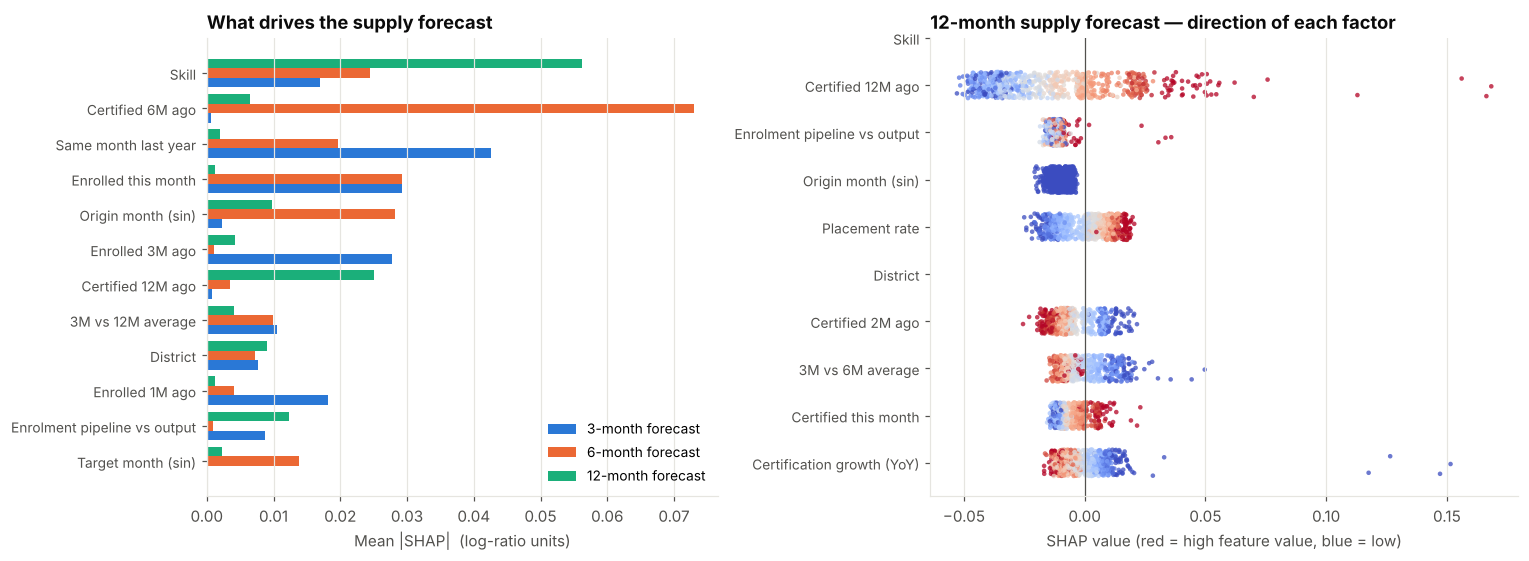

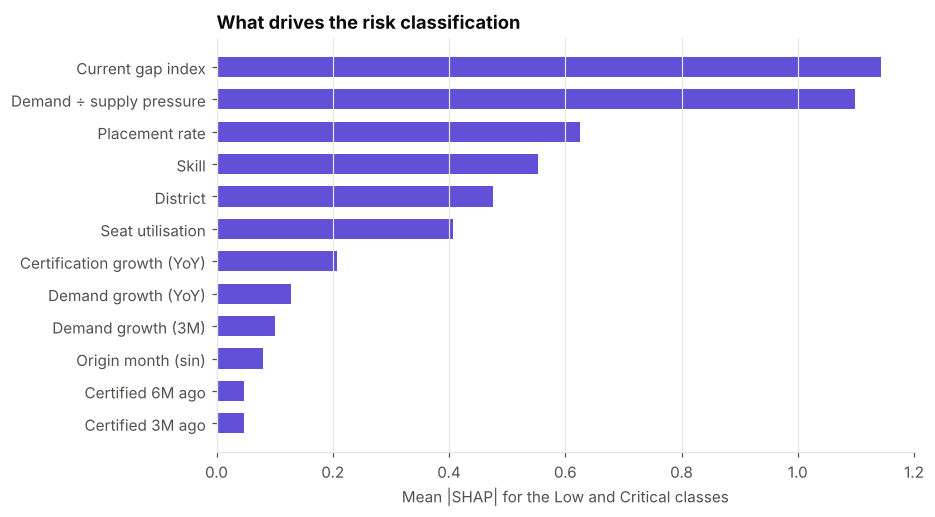

✔ SHAP additivity verified for the risk classifier.


**Example — West Bengal | Kolkata | Electrician:** supply forecast driven by *Recent certified volume (3M avg) (lowers); Certified 12M ago (lowers); Skill (lowers)* · early-warning risk **Critical** driven by *Current gap index (raises); Demand ÷ supply pressure (raises); District (raises)*.

In [47]:
import shap
SUP_LABELS = {"base_log": "Recent certified volume (3M avg)", "rel_lag0": "Certified this month", "rel_lag1": "Certified 1M ago", "rel_lag2": "Certified 2M ago", "rel_lag3": "Certified 3M ago",
              "rel_lag6": "Certified 6M ago", "rel_lag12": "Certified 12M ago", "rel_same_month_ly": "Same month last year", "avg3_vs_avg6": "3M vs 6M average", "avg3_vs_avg12": "3M vs 12M average",
              "enr6_vs_cert": "Enrolment pipeline vs output", "seats_log": "Seats sanctioned", "seat_util": "Seat utilisation", "centres": "Training centres", "seats_per_centre": "Seats per centre",
              "placement_rate": "Placement rate", "demand_supply_ratio": "Demand ÷ supply pressure", "demand_growth_3m": "Demand growth (3M)", "growth_1m": "Certification growth (1M)",
              "growth_3m": "Certification growth (3M)", "growth_yoy": "Certification growth (YoY)", "volatility_6m": "Volatility (6M)", "month_sin": "Origin month (sin)", "month_cos": "Origin month (cos)",
              "target_month_sin": "Target month (sin)", "target_month_cos": "Target month (cos)", "fy_pos": "Position in financial year", "target_crosses_fy": "Target in next FY",
              "STATE": "State", "DISTRICT": "District", "SKILL": "Skill", "SECTOR": "Sector", "gap_now": "Current gap index", "dem_yoy": "Demand growth (YoY)"}
for k in range(7):
    SUP_LABELS[f"enr_lag{k}"] = f"Enrolled {k}M ago" if k else "Enrolled this month"
def lab_(f): return SUP_LABELS.get(f, f)

SSHAP, SSHAP_BASE, SFEAT_NAMES = {}, {}, SUP_FEATURES + CAT_COLS
for h in HORIZONS:
    trees = [m for k, m in SMODELS[h].items() if k in ("LGBM", "XGB")]
    if not trees:                                                       # a linear model was selected: explain a LightGBM on the same data instead
        trees = [make_lgb(**S_TUNED[h]["lgb"]).fit(s_design(SFE_FN[h], "tree"), SFE_FN[h]["y_rel"].to_numpy())]
    Xe = s_design(SFINAL[h], "tree")
    exs = [shap.TreeExplainer(m) for m in trees]                       # for an ensemble the SHAP values of the members are averaged (still additive)
    sv = np.mean([e.shap_values(Xe) for e in exs], axis=0)
    base_v = float(np.mean([np.ravel(e.expected_value)[0] for e in exs]))
    assert np.abs(sv.sum(axis=1) + base_v - np.mean([m.predict(Xe) for m in trees], axis=0)).max() < 1e-4, "SHAP additivity violated"
    SSHAP[h], SSHAP_BASE[h] = sv.astype(np.float32), base_v
print("✔ SHAP additivity verified for the supply models (base value + contributions = model output).")

imp = pd.DataFrame({f"{h}M": np.abs(SSHAP[h]).mean(axis=0) for h in HORIZONS}, index=[lab_(f) for f in SFEAT_NAMES])
top = imp.mean(axis=1).sort_values(ascending=False).head(12).index
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]; d = imp.loc[top][::-1]; y = np.arange(len(d)); hw = 0.27
for k, (h, col) in enumerate(zip(HORIZONS, [C[0], C[1], C[2]])):
    ax.barh(y + (k - 1) * hw, d[f"{h}M"], height=hw, color=col, label=f"{h}-month forecast")
ax.set_yticks(y); ax.set_yticklabels(d.index, fontsize=9); ax.grid(axis="y", visible=False); ax.legend(loc="lower right", fontsize=9)
ax.set_xlabel("Mean |SHAP|  (log-ratio units)"); ax.set_title("What drives the supply forecast", loc="left")
ax = axes[1]
h = 12; sv = SSHAP[h]; Xe = s_design(SFINAL[h], "tree"); order = np.argsort(-np.abs(sv).mean(axis=0))[:10][::-1]
for row, j in enumerate(order):
    f = SFEAT_NAMES[j]
    if f in CAT_COLS: continue
    v = Xe[f].to_numpy(float); lo_, hi_ = np.nanpercentile(v, [5, 95]); c = np.clip((v - lo_) / max(hi_ - lo_, 1e-9), 0, 1)
    ax.scatter(sv[:, j], row + np.random.default_rng(SEED).uniform(-0.28, 0.28, len(v)), c=c, cmap="coolwarm", s=9, alpha=0.75, edgecolor="none")
ax.set_yticks(range(len(order))); ax.set_yticklabels([lab_(SFEAT_NAMES[j]) for j in order], fontsize=9); ax.axvline(0, color=INK2, lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("SHAP value (red = high feature value, blue = low)"); ax.set_title("12-month supply forecast — direction of each factor", loc="left")
fig.tight_layout(); show(fig, "shap_supply")

# ---- classifier SHAP
Xc = clf_design(CLF_ROWS)
exc = shap.TreeExplainer(CLF_FINAL); svc = exc.shap_values(Xc)
svc = np.stack(svc, axis=-1) if isinstance(svc, list) else svc                      # (n, F, K)
base_c = np.ravel(exc.expected_value)
raw = CLF_FINAL.predict(Xc, output_margin=True)
assert np.abs(svc.sum(axis=1) + base_c[None, :] - raw).max() < 1e-3, "SHAP additivity violated (classifier)"
CFEAT_NAMES = CLF_FEATURES + CAT_COLS
cls_imp = np.abs(svc[:, :, 3]).mean(axis=0) + np.abs(svc[:, :, 0]).mean(axis=0)     # importance for the two extreme classes
sel = np.argsort(-cls_imp)[:12][::-1]
fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.barh([lab_(CFEAT_NAMES[j]) for j in sel], cls_imp[sel], color=C[3] if len(C) > 3 else C[0], height=0.62); ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean |SHAP| for the Low and Critical classes"); ax.set_title("What drives the risk classification", loc="left"); fig.tight_layout(); show(fig, "shap_classifier")
print("✔ SHAP additivity verified for the risk classifier.")

# ---- per-series explanation: top 3 drivers in words (supply 12M and risk class)
def top_drivers(sv_row, vals, names, k=3):
    idx = np.argsort(-np.abs(sv_row))[:k]
    return "; ".join(f"{lab_(names[i])} ({'raises' if sv_row[i] > 0 else 'lowers'})" for i in idx)
pos = {s: i for i, s in enumerate(SIDS)}
G["supply_drivers_12m"] = [top_drivers(SSHAP[12][pos[s]], None, SFEAT_NAMES) for s in SIDS]
cls_idx = np.array([RISK_ORDER.index(r) for r in G["ml_risk"]])
G["risk_drivers"] = [top_drivers(svc[i, :, cls_idx[i]], None, CFEAT_NAMES) for i in range(len(SIDS))]
ex_sid = G[(G["skill"] == "Electrician")].sort_values("priority_rank").index[0]
display(Markdown(f"**Example — {ex_sid}:** supply forecast driven by *{G.at[ex_sid, 'supply_drivers_12m']}* · early-warning risk **{G.at[ex_sid, 'ml_risk']}** driven by *{G.at[ex_sid, 'risk_drivers']}*."))

## 28. Final output — fixed format for FastAPI / dashboard

The final table below has **one row per district × skill** and a fixed schema. The first nine columns are exactly the fields requested in the brief; the remaining columns carry the context that the dashboard needs (horizons, confidence, intervals, priority, drivers).

In [48]:
BRIEF_FIELDS = ["district", "skill", "forecast_supply_3m", "forecast_supply_6m", "forecast_supply_12m", "training_capacity", "skill_gap", "risk", "recommendation"]
FINAL_OUT = G.reset_index(drop=True).rename(columns={"supply_3m": "forecast_supply_3m", "supply_6m": "forecast_supply_6m", "supply_12m": "forecast_supply_12m"})
EXTRA = ["state", "sector", "current_demand", "forecast_3m", "forecast_6m", "forecast_12m", "demand_growth", "confidence", "current_supply", "gap_3m", "gap_6m", "gap_12m",
         "gap_index", "direction", "risk_3m", "risk_6m", "risk_12m", "ml_risk", "ml_confidence", "seat_change", "annual_seats", "seat_utilisation", "placement_rate", "completion_rate",
         "priority", "priority_rank", "recommendation_detail", "supply_confidence", "supply_drivers_12m", "risk_drivers"]
FINAL_OUT = FINAL_OUT[BRIEF_FIELDS + EXTRA].sort_values("priority_rank").reset_index(drop=True)
assert FINAL_OUT[BRIEF_FIELDS].notna().all().all() and len(FINAL_OUT) == len(SIDS) and not FINAL_OUT.duplicated(["state", "district", "skill"]).any()
assert (FINAL_OUT["skill_gap"] == FINAL_OUT["forecast_12m"] - FINAL_OUT["forecast_supply_12m"]).all()
assert FINAL_OUT["risk"].isin(RISK_ORDER).all() and FINAL_OUT["forecast_supply_12m"].ge(0).all()
display(Markdown("**The fixed output (brief format) — top priorities:**"))
display(FINAL_OUT[BRIEF_FIELDS].head(10))
FINAL_SCHEMA = {"district": "str", "skill": "str", "forecast_supply_3m": "int  (certified people / month, target " + fc_months[3] + ")",
                "forecast_supply_6m": "int  (target " + fc_months[6] + ")", "forecast_supply_12m": "int  (target " + fc_months[12] + ")",
                "training_capacity": "int  (monthly certification capacity = annual seats × completion ÷ 12)",
                "skill_gap": "int  (forecast demand 12M − forecast supply 12M; + shortage, − oversupply)", "risk": "Low | Medium | High | Critical",
                "recommendation": "Increase training capacity | Fill existing seats first | Reduce seats | Maintain capacity"}
display(Markdown("**Example of one API response record**"))
print(json.dumps({k: (v.item() if hasattr(v, "item") else v) for k, v in FINAL_OUT.iloc[0][BRIEF_FIELDS].items()}, indent=2, ensure_ascii=False))

**The fixed output (brief format) — top priorities:**

,district,skill,forecast_supply_3m,forecast_supply_6m,forecast_supply_12m,training_capacity,skill_gap,risk,recommendation
0,Kolkata,General Duty Assistant,248,259,234,284,260,Critical,Increase training capacity
1,Kolkata,Data Analyst,128,143,147,157,235,Critical,Increase training capacity
2,Kolkata,Electrician,297,324,269,340,231,Critical,Increase training capacity
3,Kolkata,Solar PV Technician,144,200,170,154,217,Critical,Increase training capacity
4,Jaipur,Data Entry Operator,342,389,304,831,-178,Critical,Reduce seats
5,Kolkata,EV Technician,59,64,68,74,178,Critical,Increase training capacity
6,North West,Data Entry Operator,329,359,296,697,-175,Critical,Reduce seats
7,Surat,General Duty Assistant,284,372,290,387,160,Critical,Increase training capacity
8,Chennai,Data Entry Operator,290,320,267,752,-148,Critical,Reduce seats
9,24 Paraganas North,Data Analyst,123,129,147,154,146,Critical,Increase training capacity


**Example of one API response record**

{
  "district": "Kolkata",
  "skill": "General Duty Assistant",
  "forecast_supply_3m": 248,
  "forecast_supply_6m": 259,
  "forecast_supply_12m": 234,
  "training_capacity": 284,
  "skill_gap": 260,
  "risk": "Critical",
  "recommendation": "Increase training capacity"
}


**FastAPI integration (reference snippet — not executed here, so that this notebook writes no extra file).** The dashboard / API only needs the single bundle written in the last cell:

```python
# api.py  ·  run with:  uvicorn api:app --reload
import pickle, pandas as pd
from fastapi import FastAPI, HTTPException

B = pickle.load(open("lmis_bundle.pkl", "rb"))            # only load a bundle that you created yourself
DF = pd.DataFrame(B["final_output"])
app = FastAPI(title="LMIS — supply, gap, risk, recommendation")

@app.get("/forecast")
def forecast(district: str, skill: str):
    r = DF[(DF.district.str.lower() == district.lower()) & (DF.skill.str.lower() == skill.lower())]
    if r.empty: raise HTTPException(404, "unknown district / skill")
    return r.iloc[0][B["brief_fields"]].to_dict()

@app.get("/high-risk")
def high_risk(min_risk: str = "High"):
    order = ["Low", "Medium", "High", "Critical"]
    return DF[DF.risk.map(order.index) >= order.index(min_risk)][B["brief_fields"]].to_dict("records")
```

## 29. Part 2 — Definition of Done

In [49]:
done = {
 "Supply data is cleaned and ready (duplicates, missing values, standardised names, complete monthly grid)":
     len(sup) == len(SIDS) * len(DATES) and not sup[FLOW + STATIC].isna().any().any() and int(audit_s_df.loc[0, "Issues found"]) >= 0,
 "Supply forecasting model is trained and evaluated (rolling validation + hold-out MAE / RMSE / MAPE vs benchmarks)":
     set(S_SELECTED) == set(HORIZONS) and not SEVAL_FIXED.empty and not SEVAL_ROLL.empty,
 "Forecast supply is generated for 3, 6 and 12 months with intervals and confidence":
     all(f"supply_{h}m" in SUP_OUT.columns and f"supply_{h}m_low" in SUP_OUT.columns for h in HORIZONS),
 "Demand and supply are combined to calculate the skill gap (Gap = Forecast Demand − Forecast Supply)":
     bool((G["skill_gap"] == G["forecast_12m"] - G["supply_12m"]).all()),
 "Risk level (Low / Medium / High / Critical) is generated — rule-based + XGBoost classifier":
     set(G["risk"]) <= set(RISK_ORDER) and G["ml_risk"].isin(RISK_ORDER).all(),
 "Recommendation is generated (increase / fill / reduce / maintain, with seat numbers and same-district re-allocation)":
     G["recommendation"].notna().all() and "seat_change" in G.columns,
 "SHAP explanation is available (supply forecast per horizon + risk classifier, additivity verified)":
     all(SSHAP[h].shape == (len(SIDS), len(SFEAT_NAMES)) for h in HORIZONS) and svc.shape[0] == len(SIDS),
 "Final output format is fixed (brief fields + schema + API snippet)":
     list(FINAL_OUT.columns[:len(BRIEF_FIELDS)]) == BRIEF_FIELDS,
 "Model stack as requested: Linear Regression · LightGBM / XGBoost · ARIMA · XGBoost classifier · SHAP":
     {"LR", "LGBM", "XGB"} <= set(SEVAL_FIXED.Model) and "ARIMA" in set(SEVAL_FIXED.Model) and CLF_FINAL is not None,
}
display(pd.DataFrame({"Requirement": list(done), "Status": ["✅ done" if v else "❌ missing" for v in done.values()]}).style.hide(axis="index"))
assert all(done.values()), "a Definition-of-Done item is not met"

Requirement,Status
"Supply data is cleaned and ready (duplicates, missing values, standardised names, complete monthly grid)",✅ done
Supply forecasting model is trained and evaluated (rolling validation + hold-out MAE / RMSE / MAPE vs benchmarks),✅ done
"Forecast supply is generated for 3, 6 and 12 months with intervals and confidence",✅ done
Demand and supply are combined to calculate the skill gap (Gap = Forecast Demand − Forecast Supply),✅ done
Risk level (Low / Medium / High / Critical) is generated — rule-based + XGBoost classifier,✅ done
"Recommendation is generated (increase / fill / reduce / maintain, with seat numbers and same-district re-allocation)",✅ done
"SHAP explanation is available (supply forecast per horizon + risk classifier, additivity verified)",✅ done
Final output format is fixed (brief fields + schema + API snippet),✅ done
Model stack as requested: Linear Regression · LightGBM / XGBoost · ARIMA · XGBoost classifier · SHAP,✅ done


## 30. Results at a glance and limitations

In [50]:
def sev(h, m, k="MAPE"): return float(SEVAL_FIXED[(SEVAL_FIXED.Horizon == h) & (SEVAL_FIXED.Model == m)][k].iloc[0])
nat_gap = G.groupby("skill").apply(lambda g: gap_index(g["forecast_12m"].sum(), g["supply_12m"].sum()))
sh_skill, ov_skill = nat_gap.idxmax(), nat_gap.idxmin()
display(Markdown(f"""
* **Scope:** {len(G):,} district × skill series · {G['state'].nunique()} states · {G['skill'].nunique()} skills · supply source: **{SUPPLY_SOURCE}**.
* **Supply models (rolling validation):** {" · ".join(f"**{h}M → {MODEL_NAMES[S_SELECTED[h]]}**" for h in HORIZONS)}; fixed-origin hold-out MAPE **{sev(3, S_SELECTED[3]):.1f}% / {sev(6, S_SELECTED[6]):.1f}% / {sev(12, S_SELECTED[12]):.1f}%** against seasonal-naive {sev(3, 'SNAIVE'):.1f}% / {sev(6, 'SNAIVE'):.1f}% / {sev(12, 'SNAIVE'):.1f}%.
* **Risk map (12 months, base scenario):** {" · ".join(f"**{c}** {int((G['risk'] == c).sum())}" for c in RISK_ORDER)}; most under-supplied skill nationally: **{sh_skill}** (gap index {nat_gap[sh_skill]:+.2f}), most over-supplied: **{ov_skill}** ({nat_gap[ov_skill]:+.2f}).
* **Early-warning classifier:** hold-out accuracy {CLF_EVAL.loc['XGBoost classifier', 'Accuracy']:.0%} (persistence baseline {CLF_EVAL.loc['Persistence (risk stays as today)', 'Accuracy']:.0%}), within-one-class {CLF_EVAL.loc['XGBoost classifier', 'Within one class']:.0%}.
* **Recommended action:** +{tot_add:,} seats where short, −{tot_cut:,} where over-supplied, of which {moved:,} can be re-allocated inside the same district.
"""))
display(Markdown(r"""
### Limitations — to be stated openly
1. **Supply data is simulated** (anchored to the real PMKVY district volumes). All Part-2 *numbers* are illustrative; the *method* is complete and runs unchanged on a real registry extract (`SUPPLY_CSV`). Because the simulated supply follows a clean pipeline, the supply-model errors are optimistic compared with real data.
2. **Risk bands, close/reduce fractions, seat caps and the 90 % target utilisation are policy assumptions** (`POLICY`); they are exposed as controls in the dashboard so that planners can change them.
3. **The 12-month demand forecast carries the base NCS-anchor assumption** from Part 1 (+7.3 % next-FY growth). The risk map is therefore shown under the Low / Base / High scenarios (§26); supply is not anchor-scaled.
4. **The risk classifier is trained on seven-to-eight months of realised outcomes per series** over four financial years; it is an early-warning aid next to — not instead of — the rule-based headline risk.
5. **Recommendations are district-level seat decisions**, not centre-level; they ignore cost, trainer availability and the mobility of trainees across districts.
"""))


* **Scope:** 756 district × skill series · 12 states · 12 skills · supply source: **SIMULATED (anchored to real PMKVY FY2021-22 district volumes)**.
* **Supply models (rolling validation):** **3M → Ensemble (LGBM+XGB)** · **6M → LightGBM** · **12M → Ensemble (LGBM+XGB)**; fixed-origin hold-out MAPE **5.2% / 8.3% / 8.3%** against seasonal-naive 11.5% / 11.5% / 11.6%.
* **Risk map (12 months, base scenario):** **Low** 186 · **Medium** 194 · **High** 118 · **Critical** 258; most under-supplied skill nationally: **EV Technician** (gap index +0.52), most over-supplied: **Data Entry Operator** (-0.35).
* **Early-warning classifier:** hold-out accuracy 61% (persistence baseline 58%), within-one-class 91%.
* **Recommended action:** +118,216 seats where short, −38,774 where over-supplied, of which 19,632 can be re-allocated inside the same district.



### Limitations — to be stated openly
1. **Supply data is simulated** (anchored to the real PMKVY district volumes). All Part-2 *numbers* are illustrative; the *method* is complete and runs unchanged on a real registry extract (`SUPPLY_CSV`). Because the simulated supply follows a clean pipeline, the supply-model errors are optimistic compared with real data.
2. **Risk bands, close/reduce fractions, seat caps and the 90 % target utilisation are policy assumptions** (`POLICY`); they are exposed as controls in the dashboard so that planners can change them.
3. **The 12-month demand forecast carries the base NCS-anchor assumption** from Part 1 (+7.3 % next-FY growth). The risk map is therefore shown under the Low / Base / High scenarios (§26); supply is not anchor-scaled.
4. **The risk classifier is trained on seven-to-eight months of realised outcomes per series** over four financial years; it is an early-warning aid next to — not instead of — the rule-based headline risk.
5. **Recommendations are district-level seat decisions**, not centre-level; they ignore cost, trainer availability and the mobility of trainees across districts.


## 31. Deployment bundle — the only file this notebook creates

Everything the Streamlit app (`app.py`) needs is written to **one** file, `lmis_bundle.pkl`: the final tables, the history, the evaluation results, the SHAP values and the fitted models (as bytes), plus the policy parameters. After writing, the file is read back and verified; nothing else is written to disk by this notebook.

> **Security note:** a pickle can execute code when loaded. Only load bundles that you created yourself.

In [51]:
import pickle, platform, datetime as dt, sklearn

def tab(d):                                   # DataFrame -> plain dict of lists (loads without any particular pandas version)
    d = d.reset_index(drop=True).copy()
    for c in d.columns:
        if d[c].dtype.kind in "iu": d[c] = d[c].astype("int64")
        elif d[c].dtype.kind == "f": d[c] = d[c].astype("float64")
        elif d[c].dtype.name == "category": d[c] = d[c].astype(str)
    return {c: d[c].tolist() for c in d.columns}

SERIES = G.copy(); SERIES.insert(0, "series_id", SERIES.index)
for c in SUP_OUT.columns:
    if c not in SERIES.columns: SERIES[c] = SUP_OUT[c]
SERIES = SERIES.drop(columns=["annual_seats"]).assign(annual_seats=G["annual_seats"].astype(int)).reset_index(drop=True)

hist_nom = df.pivot(index="t_idx", columns="SERIES_ID", values="DEMAND").reindex(columns=SIDS).sort_index()
shap_x = {}
for h in HORIZONS:
    Xe = s_design(SFINAL[h], "tree")
    shap_x[h] = {"numeric": Xe[SUP_FEATURES].to_numpy(np.float32), "categorical": {c: Xe[c].astype(str).tolist() for c in CAT_COLS}}
BUNDLE = {
    "format_version": 2,
    "meta": {"created": dt.datetime.now().strftime("%Y-%m-%d %H:%M"), "supply_source": SUPPLY_SOURCE, "supply_is_simulated": bool(SIMULATED),
             "last_data_month": f"{LAST_DATE:%Y-%m}", "horizons": list(HORIZONS), "target_months": {str(h): fc_months[h] for h in HORIZONS},
             "dates": [d.strftime("%Y-%m") for d in DATES], "fy_label": {str(k): v for k, v in FY_LABEL.items()}, "last_fy": int(LAST_FY),
             "demand_selected": {str(h): MODEL_NAMES[SELECTED[h]] for h in HORIZONS}, "supply_selected": {str(h): MODEL_NAMES[S_SELECTED[h]] for h in HORIZONS},
             "scenarios": {k: float(v) for k, v in SCEN.items()}, "g_base": float(G_BASE), "model_names": MODEL_NAMES,
             "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__, "lightgbm": lgb.__version__, "xgboost": xgb.__version__, "shap": shap.__version__},
             "n_series": len(SIDS), "n_states": int(G["state"].nunique()), "n_districts": int(G.groupby(["state", "district"]).ngroups), "n_skills": int(G["skill"].nunique())},
    "policy": {k: (list(v) if isinstance(v, tuple) else v) for k, v in POLICY.items()},
    "risk_order": RISK_ORDER, "brief_fields": BRIEF_FIELDS, "final_schema": FINAL_SCHEMA,
    "series": tab(SERIES), "final_output": tab(FINAL_OUT), "realloc": tab(REALLOC), "scenario_risk": tab(SCEN_RISK.reset_index()),
    "history": {"series_ids": SIDS, "dates": [d.strftime("%Y-%m") for d in DATES], "demand_nominal": hist_nom.to_numpy(np.float32), "demand_const": DEM_WIDE.to_numpy(np.float32),
                "supply_certified": SUP_WIDE["CERTIFIED"].to_numpy(np.float32), "supply_enrolled": SUP_WIDE["ENROLLED"].to_numpy(np.float32), "supply_placed": SUP_WIDE["PLACED"].to_numpy(np.float32)},
    "evaluation": {"demand_fixed": tab(EVAL_FIXED), "demand_rolling": tab(EVAL_ROLL), "supply_fixed": tab(SEVAL_FIXED), "supply_rolling": tab(SEVAL_ROLL),
                   "demand_validation": tab(VAL_TAB), "supply_validation": tab(SVAL), "classifier": tab(CLF_EVAL.reset_index().rename(columns={"index": "model"})),
                   "classifier_confusion": CLF_CM.tolist(), "demand_audit": tab(audit_df), "supply_audit": tab(audit_s_df), "supply_params": tab(SKILL_PARAMS.reset_index().rename(columns={"index": "skill"})),
                   "demand_features": tab(FEATURE_TABLE)},
    "shap": {"supply_feature_names": SFEAT_NAMES, "supply_labels": {f: lab_(f) for f in SFEAT_NAMES + CFEAT_NAMES},
             "supply": {str(h): SSHAP[h] for h in HORIZONS}, "supply_base": {str(h): float(SSHAP_BASE[h]) for h in HORIZONS},
             "supply_x": {str(h): shap_x[h] for h in HORIZONS}, "supply_sids": SIDS,
             "classifier_feature_names": CFEAT_NAMES, "classifier": svc.astype(np.float32), "classifier_base": [float(b) for b in base_c],
             "classifier_x": {"numeric": CLF_ROWS[CLF_FEATURES].to_numpy(np.float32), "numeric_names": CLF_FEATURES, "categorical": {c: CLF_ROWS[c].astype(str).tolist() for c in CAT_COLS}}},
    "model_blob": pickle.dumps({"supply_models": {str(h): SMODELS[h] for h in HORIZONS}, "risk_classifier": CLF_FINAL, "supply_features": SUP_FEATURES, "classifier_features": CLF_FEATURES,
                                "categorical": CAT_COLS, "risk_order": RISK_ORDER}, protocol=4),
}
with open(BUNDLE_PATH, "wb") as fh:
    pickle.dump(BUNDLE, fh, protocol=4)

# ---- read the bundle back and verify it
with open(BUNDLE_PATH, "rb") as fh:
    chk = pickle.load(fh)
fo = pd.DataFrame(chk["final_output"])
assert len(fo) == len(SIDS) and list(fo.columns[:len(BRIEF_FIELDS)]) == BRIEF_FIELDS and fo[BRIEF_FIELDS].notna().all().all()
assert fo["risk"].isin(RISK_ORDER).all() and (fo["skill_gap"] == fo["forecast_12m"] - fo["forecast_supply_12m"]).all()
ser = pd.DataFrame(chk["series"]); assert len(ser) == len(SIDS) and ser["series_id"].is_unique
assert chk["history"]["demand_nominal"].shape == (len(DATES), len(SIDS)) and chk["shap"]["supply"]["12"].shape == (len(SIDS), len(SFEAT_NAMES))
mb = pickle.loads(chk["model_blob"])                                          # the stored models must reproduce the stored forecasts
for h in HORIZONS:
    ms = [m for k, m in mb["supply_models"][str(h)].items()]
    rel = np.mean([m.predict(s_design(SFINAL[h], "lin" if k == "LR" else "tree")) for k, m in mb["supply_models"][str(h)].items()], axis=0)
    assert np.allclose(np.rint(pred_count(SFINAL[h], rel)), ser[f"supply_{h}m"].reindex(range(len(ser))).to_numpy()[[list(ser["series_id"]).index(s) for s in SIDS]]), "stored models do not reproduce the forecast"
proba = mb["risk_classifier"].predict_proba(clf_design(CLF_ROWS))
assert np.array_equal(np.array(RISK_ORDER)[proba.argmax(1)], ser.set_index("series_id").loc[SIDS, "ml_risk"].to_numpy())
size_mb = BUNDLE_PATH.stat().st_size / 1e6
print(f"✔ {BUNDLE_PATH} written and verified: {size_mb:.1f} MB · {len(fo):,} series · stored models reproduce the forecasts and the risk classes.")
print("✔ This is the ONLY file created by the notebook — run:  streamlit run app.py")

✔ lmis_bundle.pkl written and verified: 10.4 MB · 756 series · stored models reproduce the forecasts and the risk classes.
✔ This is the ONLY file created by the notebook — run:  streamlit run app.py
